# TellCo User Analytics: Telecom Customer Analysis (Tasks 1 to 4)
**Goal:** analyse one month of xDR data and advise whether TellCo is worth buying.

| Part | Content |
| --- | --- |
| 0 | Setup: imports, configuration, plotting theme |
| 1 | Data loading and cleaning: missing values heatmap, outlier detection **and the decision to keep or remove outliers** |
| 2 | **Task 1** User Overview: handsets, manufacturers, aggregation, EDA, correlation, PCA, deciles |
| 3 | **Task 2** User Engagement: metrics, k-means, elbow, silhouette, radar chart, personas, top apps |
| 4 | **Task 3** User Experience: throughput, RTT, TCP retransmission, handset table, experience clusters |
| 5 | **Task 4** Satisfaction: scores, Linear vs Random Forest vs XGBoost, k=2 segments, CSV export, SQL Server load |
| 5B | **Extra analysis** (beyond the brief): usage concentration, confidence intervals, significance tests, engagement x experience, busy hours, model drivers, cluster stability |
| 6 | **Brief task 4.7** Model deployment and tracking with MLflow |
| 7 | Executive summary, recommendations, limitations |
| 8 | **Dashboard**: interactive dashboard shown inside the notebook (Plotly) |
| 9 | **Engineering deliverables**: installable package, unit tests, CI/CD, Dockerfile, Streamlit app, pipeline run, cloud hosting guide |

**How to run:** put `telcom_data.xlsx` next to the notebook (the load cell also looks in `data/raw/`), then *Kernel > Restart & Run All* (Jupyter) or *Runtime > Run all* (Colab).

**Outputs:** `final_scores.csv`, `engagement_scores.csv`, `experience_scores.csv` and `satisfaction_scores.csv` (section 5.6 and 5.7), loaded into SQL Server in section 5.8, plus the installable package, tests, Dockerfile and dashboard in Part 9.


## Part 0: Setup (imports, configuration, plotting theme)


In [1]:
# %pip install -q pandas numpy matplotlib scikit-learn openpyxl xgboost mlflow   # uncomment on a fresh machine / Colab
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None
    print('xgboost not installed: run  %pip install xgboost  and restart to include it in the model comparison')

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

APPS = ["Social Media", "Google", "Email", "Youtube", "Netflix", "Gaming", "Other"]
ID_COLS = ["Bearer Id", "IMSI", "MSISDN", "IMEI"]

In [2]:
# %pip install -q seaborn     # uncomment on a fresh machine / Colab
# Seaborn is loaded and configured in its own cell
import seaborn as sns

def sns_size(w=6.4, h=4.8):
    """Seaborn theme with a given figure size (call sns_size() with no arguments to reset)."""
    sns.set_theme(style="whitegrid", context="notebook", rc={"figure.figsize": (w, h)})

sns_size()

## Part 1: Load and clean (reusable functions)

Design choices:
- `Dur. (ms)` appears twice. The second copy (`Dur. (ms).1`) holds the full session duration in ms, so we keep it as `Duration_ms`.
- **Missing values:** numeric columns get the column mean, text columns get the mode. Handset fields are filled with `"undefined"` for *both* manufacturer and type, so the two columns can never disagree.
- **Outliers:** IQR rule (below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`), replaced with the mean of the non-outlier values, as the brief requires.
- Totals (`Total Data`, per-app totals) are built **after** cleaning, so that `Total Data = DL + UL` always holds.
- ID columns are never imputed or averaged.

In [3]:
def outlier_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


def replace_outliers_with_mean(s, k=1.5):
    is_out = outlier_mask(s, k)
    return s.mask(is_out, s[~is_out].mean())


def clean_data(df):
    df = df.copy()
    for c in ["Handset Manufacturer", "Handset Type"]:
        df[c] = df[c].fillna("undefined")
    num_cols = [c for c in df.select_dtypes("number").columns if c not in ID_COLS]
    for c in num_cols:
        df[c] = df[c].fillna(df[c].mean()).fillna(0)      # fully empty column -> 0
        df[c] = replace_outliers_with_mean(df[c])
    for c in df.select_dtypes(exclude="number").columns:
        if df[c].isna().any():
            df[c] = df[c].fillna(df[c].mode().iloc[0])
    return df


def add_totals(df):
    df = df.copy()
    for a in APPS:
        df[f"{a} Total"] = df[f"{a} DL (Bytes)"] + df[f"{a} UL (Bytes)"]
    df["Total Data"] = df["Total DL (Bytes)"] + df["Total UL (Bytes)"]
    return df

In [4]:
import os
DATA_PATH = next((p for p in ["telcom_data.xlsx", os.path.join("data", "raw", "telcom_data.xlsx")] if os.path.exists(p)), None)
assert DATA_PATH, "Put telcom_data.xlsx next to this notebook (or in data/raw/)"
raw = pd.read_excel(DATA_PATH)
raw = raw.rename(columns={"MSISDN/Number": "MSISDN", "Dur. (ms).1": "Duration_ms"})
raw = raw.drop(columns=["Dur. (ms)"], errors="ignore")

print("Rows, columns:", raw.shape)
miss = raw.isna().sum()
miss_pct = (miss / len(raw) * 100)
display(pd.DataFrame({"missing": miss, "missing %": miss_pct})[miss > 0].sort_values("missing", ascending=False))

Rows, columns: (150001, 54)


,missing,missing %
Nb of sec with 37500B < Vol UL,130254,86.84
Nb of sec with 6250B < Vol UL < 37500B,111843,74.56
Nb of sec with 125000B < Vol DL,97538,65.02
TCP UL Retrans. Vol (Bytes),96649,64.43
Nb of sec with 31250B < Vol DL < 125000B,93586,62.39
Nb of sec with 1250B < Vol UL < 6250B,92894,61.93
Nb of sec with 6250B < Vol DL < 31250B,88317,58.88
TCP DL Retrans. Vol (Bytes),88146,58.76
HTTP UL (Bytes),81810,54.54
HTTP DL (Bytes),81474,54.32


### 1.1 Missing-value heatmap

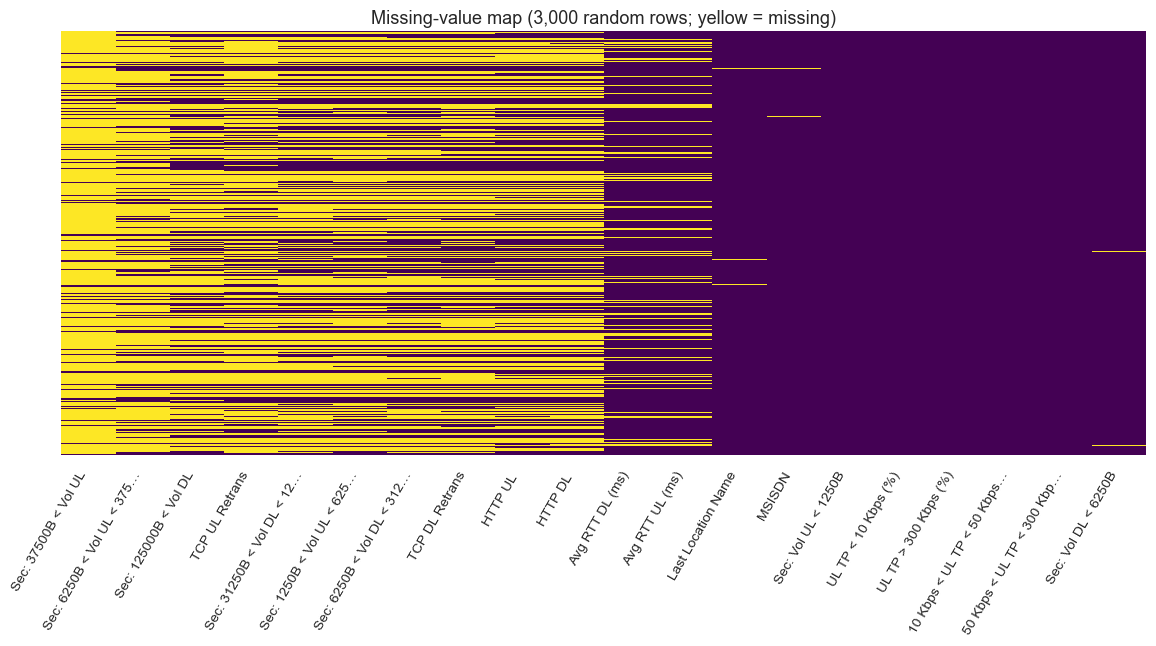

In [5]:
cols_with_na = miss[miss > 0].sort_values(ascending=False).index

def short(c):
    c = c.replace("Nb of sec with ", "Sec: ").replace("Retrans. Vol (Bytes)", "Retrans").replace("(Bytes)", "").replace("Handset ", "H. ")
    return c if len(c) <= 26 else c[:25] + "…"

sample = raw[cols_with_na].sample(3000, random_state=RANDOM_STATE)
sample.columns = [short(c) for c in sample.columns]

# 1) Heatmap of the 20 columns with the most missing data (seaborn)
sns_size(14, 8)
ax = sns.heatmap(sample[sample.columns[:20]].isna(), cbar=False, yticklabels=False, cmap="viridis")
ax.set_title("Missing-value map (3,000 random rows; yellow = missing)", fontsize=13)
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha="right", fontsize=10)
ax.figure.subplots_adjust(bottom=0.35)
sns_size()

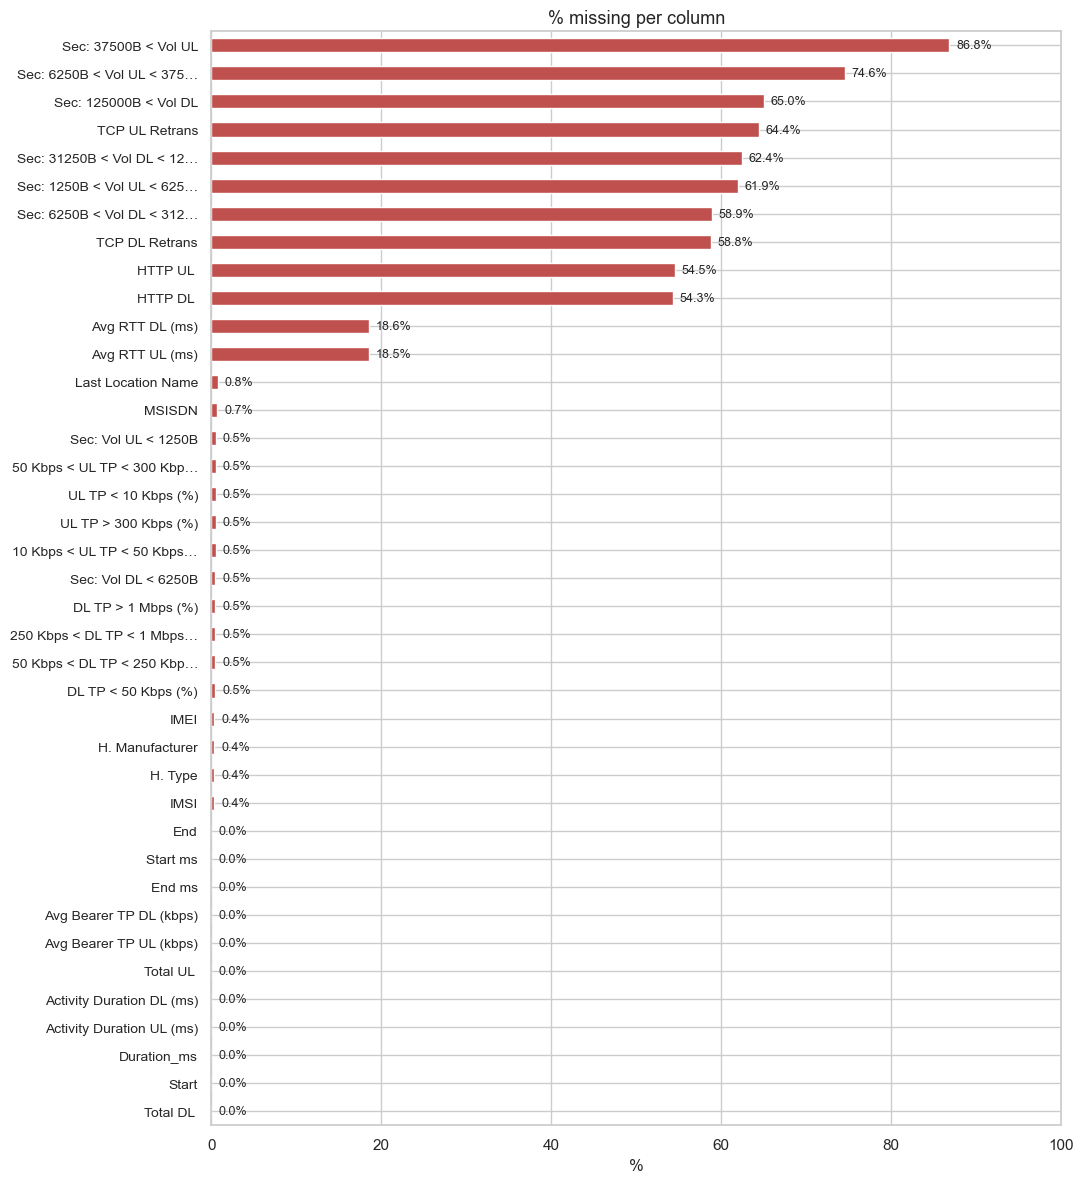

In [6]:
# 2) % missing per column (matplotlib)
vals = miss_pct[cols_with_na].sort_values(); vals.index = [short(c) for c in vals.index]
fig, ax = plt.subplots(figsize=(11, 12))
vals.plot(kind="barh", ax=ax, color="#c0504d"); ax.tick_params(axis="y", labelsize=10)
ax.set_title("% missing per column", fontsize=13); ax.set_xlabel("%"); ax.set_xlim(0, 100)
for i, v in enumerate(vals): ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Analysis: missing values.** 150,001 sessions and 54 columns after the duplicate duration column is dropped; 39 columns have gaps.
- **Heavily missing (over 50%):** six of the eight `Nb of sec with ...` columns (59% to 87%; the other two are under 1%), TCP retransmission volumes (64.4% UL, 58.8% DL) and HTTP volumes (about 54%). Mean-filling these means most rows get the same constant.
- **Moderate:** RTT DL/UL are missing in about 18.5% of sessions.
- **Small (under 1%):** handset fields (572 rows), `MSISDN` (1,066 rows), `IMSI`, `IMEI` and the throughput-bucket percentages.
- The heatmap shows the gaps come in blocks (the same rows are empty across related columns), which points to xDR records where the probe did not capture TCP/HTTP detail rather than random loss.

### 1.2 Outlier detection (before cleaning)
Rule: a value is an outlier if it is below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`. Detection first, decision next.

,outliers,% of non-null
DL TP > 1 Mbps (%),37066,24.84
10 Kbps < UL TP < 50 Kbps (%),31999,21.45
250 Kbps < DL TP < 1 Mbps (%),29751,19.93
HTTP DL (Bytes),12372,18.05
Activity Duration DL (ms),26659,17.77
Activity Duration UL (ms),26022,17.35
Nb of sec with Vol UL < 1250B,25154,16.86
Nb of sec with Vol DL < 6250B,24544,16.45
HTTP UL (Bytes),10415,15.27
UL TP < 10 Kbps (%),22123,14.83


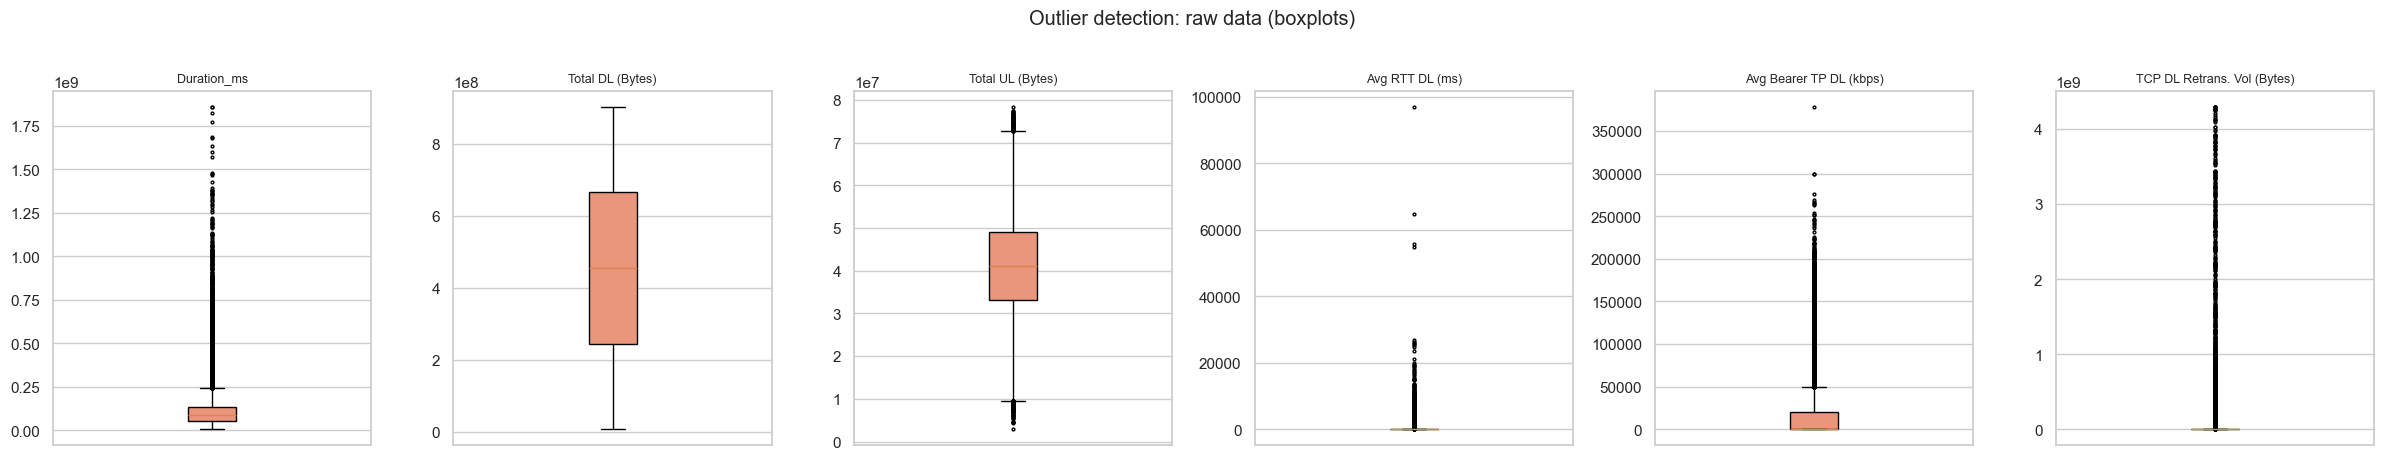

In [7]:
num_raw = [c for c in raw.select_dtypes("number").columns if c not in ID_COLS]
out_tbl = pd.DataFrame({"outliers": {c: int(outlier_mask(raw[c].dropna()).sum()) for c in num_raw}})
out_tbl["% of non-null"] = out_tbl["outliers"] / raw[num_raw].notna().sum() * 100
display(out_tbl.sort_values("% of non-null", ascending=False).head(12))

key = ["Duration_ms", "Total DL (Bytes)", "Total UL (Bytes)", "Avg RTT DL (ms)", "Avg Bearer TP DL (kbps)", "TCP DL Retrans. Vol (Bytes)"]
fig, axes = plt.subplots(1, len(key), figsize=(4 * len(key), 4.5))
for a, c in zip(axes, key):
    a.boxplot(raw[c].dropna(), patch_artist=True, boxprops=dict(facecolor="#e9967a"), flierprops=dict(markersize=2))
    a.set_title(c, fontsize=9); a.set_xticks([])
fig.suptitle("Outlier detection: raw data (boxplots)", y=1.02); plt.tight_layout(); plt.show()

**Analysis: outlier detection.** The IQR rule flags a large share of several columns: the throughput-bucket percentages (15% to 25%), `HTTP DL` (18%), the activity-duration columns (about 17%) and TCP retransmission (about 14.5%). The raw boxplots show long right tails: a few sessions are far above the rest. Whether to delete them is decided in 1.3 below.

### 1.3 Decision: remove the outliers or keep them?
Three options are compared on the same columns: **(A) keep as is**, **(B) delete every row that has an outlier** and **(C) replace only the outlier value with the mean of the normal values**.

In [8]:
flag = pd.concat([outlier_mask(raw[c].dropna()).reindex(raw.index, fill_value=False) for c in key], axis=1)
flag_all = pd.concat([outlier_mask(raw[c].dropna()).reindex(raw.index, fill_value=False) for c in num_raw], axis=1)
rows_key = flag.any(axis=1)
rows_all = flag_all.any(axis=1)
vol_cols = ["Total DL (Bytes)", "Total UL (Bytes)"]
vol_flag = flag[vol_cols].any(axis=1)
share_out = raw.loc[vol_flag, vol_cols].sum().sum() / raw[vol_cols].sum().sum() * 100

rows = []
for c in ["Total DL (Bytes)", "Duration_ms"]:
    for name, ser in [("A keep as is", raw[c]), ("B delete rows with outliers", raw.loc[~rows_key, c]), ("C replace with mean", replace_outliers_with_mean(raw[c]))]:
        rows.append({"column": c, "option": name, "rows kept": ser.notna().sum(), "mean": ser.mean(), "median": ser.median(), "std": ser.std(), "max": ser.max()})
cmp_tbl = pd.DataFrame(rows).set_index(["column", "option"])
display(cmp_tbl)

from IPython.display import Markdown
display(Markdown("**Evidence from the data**"))
display(Markdown(f"- **{rows_key.mean()*100:.1f}%** of sessions have an outlier in at least one of the 6 key columns, and **{rows_all.mean()*100:.1f}%** have one in at least one numeric column. Deleting those rows (option B) would throw away **{rows_key.sum():,} of {len(raw):,} sessions**."))
display(Markdown(f"- Sessions with an outlier in download or upload carry only **{share_out:.1f}%** of all traffic: the volume columns have very few outliers, and most flagged sessions come from duration and network-quality columns (RTT, throughput, TCP)."))
display(Markdown(f"- Deleting rows (option B) barely changes mean Total DL ({cmp_tbl.loc[('Total DL (Bytes)', 'A keep as is'), 'mean']/1e6:,.1f} MB to {cmp_tbl.loc[('Total DL (Bytes)', 'B delete rows with outliers'), 'mean']/1e6:,.1f} MB), so it gains almost nothing for volume, but it removes those sessions and the customers behind them from every later analysis. Mean duration moves from {cmp_tbl.loc[('Duration_ms', 'A keep as is'), 'mean']/3.6e6:,.1f} h (A) to {cmp_tbl.loc[('Duration_ms', 'B delete rows with outliers'), 'mean']/3.6e6:,.1f} h (B) and {cmp_tbl.loc[('Duration_ms', 'C replace with mean'), 'mean']/3.6e6:,.1f} h (C)."))

rows kept           mean  \
column           option                                                  
Total DL (Bytes) A keep as is                    150000 454,643,430.08   
                 B delete rows with outliers     113210 455,069,220.27   
                 C replace with mean             150000 454,643,430.08   
Duration_ms      A keep as is                    150000 104,609,105.55   
                 B delete rows with outliers     113210  97,353,517.54   
                 C replace with mean             150000  92,261,684.14   

                                                     median            std  \
column           option                                                      
Total DL (Bytes) A keep as is                455,841,077.50 244,142,874.38   
                 B delete rows with outliers 456,817,647.50 243,946,088.77   
                 C replace with mean         455,841,077.50 244,142,874.38   
Duration_ms      A keep as is                 86,399,983.00  81,037,611.58   
                 B delete rows with outliers  86,400,049.00  52,589,610.98   
                 C replace with mean          86,399,983.00  49,278,618.49   

                                                          max  
column           option                                        
Total DL (Bytes) A keep as is                  902,969,616.00  
                 B delete rows with outliers   902,969,616.00  
                 C replace with mean           902,969,616.00  
Duration_ms      A keep as is                1,859,336,442.00  
                 B delete rows with outliers   244,900,015.00  
                 C replace with mean           244,900,015.00

**Evidence from the data**

- **24.5%** of sessions have an outlier in at least one of the 6 key columns, and **43.6%** have one in at least one numeric column. Deleting those rows (option B) would throw away **36,790 of 150,001 sessions**.

- Sessions with an outlier in download or upload carry only **0.2%** of all traffic: the volume columns have very few outliers, and most flagged sessions come from duration and network-quality columns (RTT, throughput, TCP).

- Deleting rows (option B) barely changes mean Total DL (454.6 MB to 455.1 MB), so it gains almost nothing for volume, but it removes those sessions and the customers behind them from every later analysis. Mean duration moves from 29.1 h (A) to 27.0 h (B) and 25.6 h (C).

**Decision: we do NOT remove the outlier rows. We keep every session and replace only the outlier values with the mean of the non-outlier values (option C), as the project brief specifies.**

| Why | Explanation |
|---|---|
| Outliers are not errors | Long sessions and very high or low RTT/throughput values are plausible readings from a live network, and nothing in the data marks them as faulty, so there is no reason to treat them as bad records. |
| Too much data would be lost | Deleting rows with an outlier in any of the six key columns removes about a quarter of all sessions (24.5%, 36,790 sessions); counting every numeric column the share rises to 43.6% (see numbers above) and the customers behind them, while the volume columns barely change, so the loss buys almost nothing. |
| k-means is distance based | A few extreme values would otherwise dominate the clusters, so they must be tamed, not ignored. |
| Replacement keeps the customer | The customer stays in the dataset with a typical value instead of an extreme one, so counts of customers and sessions stay correct. |

**Trade-off we accept:** replacement lowers variance, so the most extreme durations and network readings are understated in later results (option C lowers mean duration the most, see table). Raw values stay available in `raw` as the reference. Zero values are not treated as errors.

<div style="border-left:6px solid #c55a11;background:#fdf1e7;padding:10px 14px;border-radius:4px;color:#111"><b>KEY DECISION: outliers</b><br>Do <b>not</b> delete outlier rows. Keep every session and replace only the outlier values with the mean of the normal values (project brief). Deleting would remove about a quarter of all sessions (24.5% in the six key columns, 43.6% across all numeric columns) and barely change data volume.</div>

### 1.4 Apply the decision and check the result

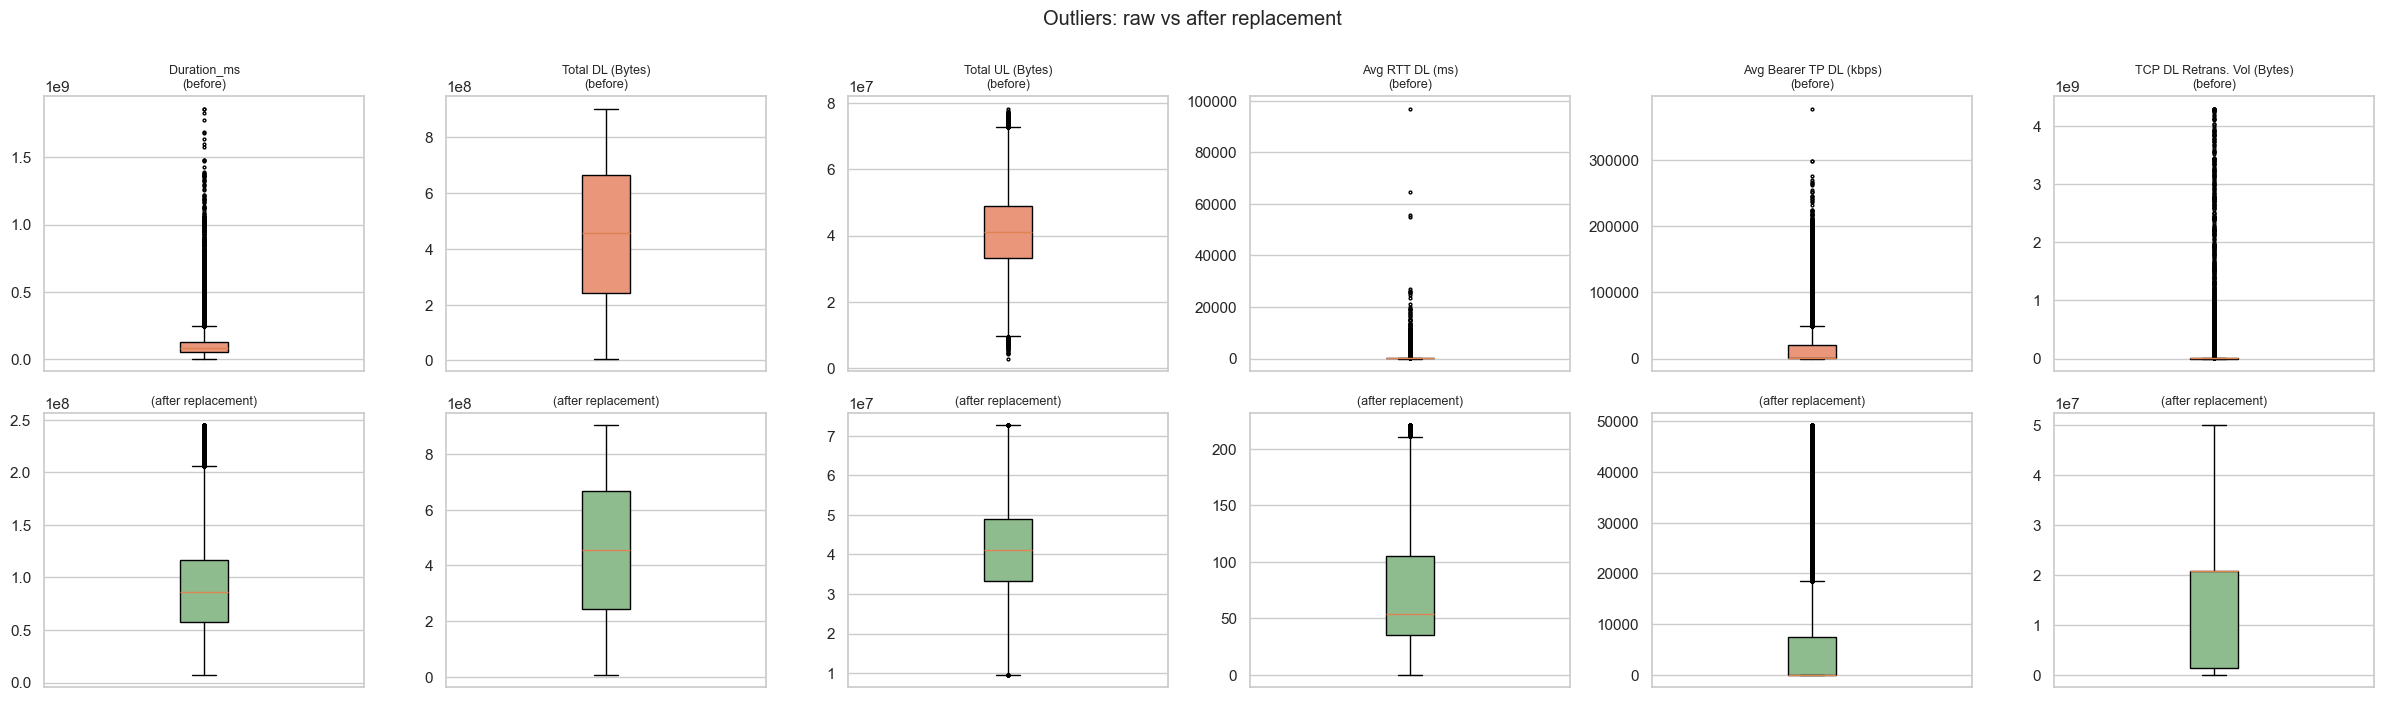

In [9]:
df = clean_data(raw)
df = add_totals(df)

fig, axes = plt.subplots(2, len(key), figsize=(4 * len(key), 7))
for i, c in enumerate(key):
    axes[0, i].boxplot(raw[c].dropna(), patch_artist=True, boxprops=dict(facecolor="#e9967a"), flierprops=dict(markersize=2))
    axes[0, i].set_title(f"{c}\n(before)", fontsize=9)
    axes[1, i].boxplot(df[c], patch_artist=True, boxprops=dict(facecolor="#8fbc8f"), flierprops=dict(markersize=2))
    axes[1, i].set_title("(after replacement)", fontsize=9)
    for r in (0, 1): axes[r, i].set_xticks([])
fig.suptitle("Outliers: raw vs after replacement", y=1.0); plt.tight_layout(); plt.show()

In [10]:
# Cleaning check: everything except the ID columns must be complete
print("Missing values left (excluding ID columns):", int(df.drop(columns=ID_COLS).isna().sum().sum()))
print("ID columns still missing:", df[ID_COLS].isna().sum().to_dict())

Missing values left (excluding ID columns): 0
ID columns still missing: {'Bearer Id': 0, 'IMSI': 570, 'MSISDN': 1066, 'IMEI': 572}


**Analysis: cleaning check.** Every non-ID column is complete (0 missing). The only gaps left are in the identifier columns (`IMSI` 570, `MSISDN` 1,066, `IMEI` 572), which are deliberately not imputed: an invented ID would merge unrelated people. The 1,066 sessions without an `MSISDN` cannot be assigned to a customer and drop out of the per-user tables.

## Part 2: Task 1, User Overview Analysis
### 2.1 Top handsets and manufacturers (Task 1)
`undefined` handsets are excluded from rankings, since they say nothing about the customer base.

,sessions
Handset Type,
Huawei B528S-23A,19752
Apple iPhone 6S (A1688),9419
Apple iPhone 6 (A1586),9023
Apple iPhone 7 (A1778),6326
Apple iPhone Se (A1723),5187
Apple iPhone 8 (A1905),4993
Apple iPhone Xr (A2105),4568
Samsung Galaxy S8 (Sm-G950F),4520
Apple iPhone X (A1901),3813


,sessions
Handset Manufacturer,
Apple,59565
Samsung,40839
Huawei,34423



Top 5 handsets for Apple


,sessions
Handset Type,
Apple iPhone 6S (A1688),9419
Apple iPhone 6 (A1586),9023
Apple iPhone 7 (A1778),6326
Apple iPhone Se (A1723),5187
Apple iPhone 8 (A1905),4993



Top 5 handsets for Samsung


,sessions
Handset Type,
Samsung Galaxy S8 (Sm-G950F),4520
Samsung Galaxy A5 Sm-A520F,3724
Samsung Galaxy J5 (Sm-J530),3696
Samsung Galaxy J3 (Sm-J330),3484
Samsung Galaxy S7 (Sm-G930X),3199



Top 5 handsets for Huawei


,sessions
Handset Type,
Huawei B528S-23A,19752
Huawei E5180,2079
Huawei P20 Lite Huawei Nova 3E,2021
Huawei P20,1480
Huawei Y6 2018,997


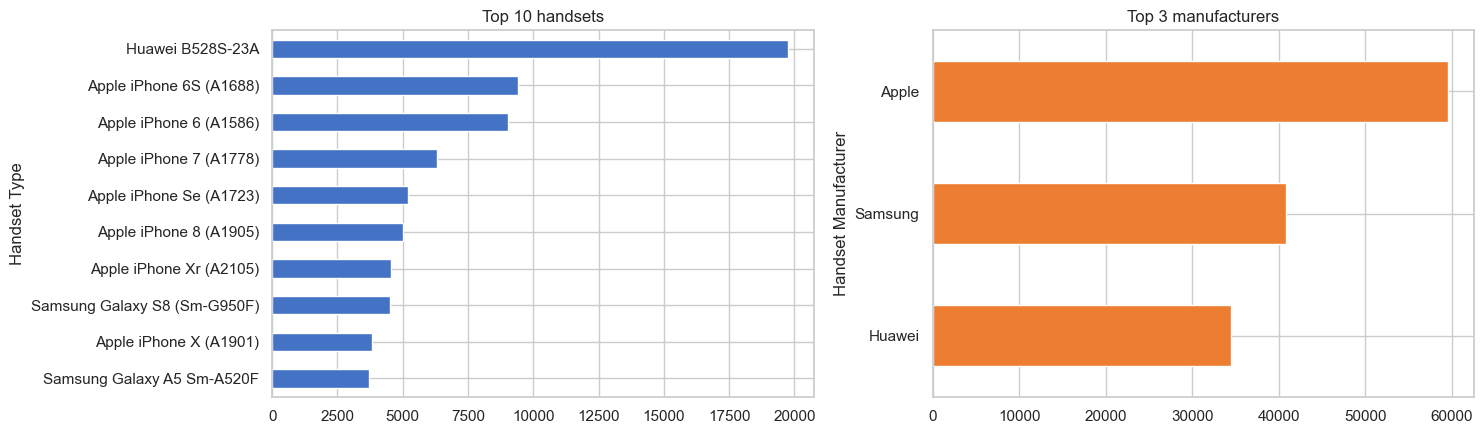

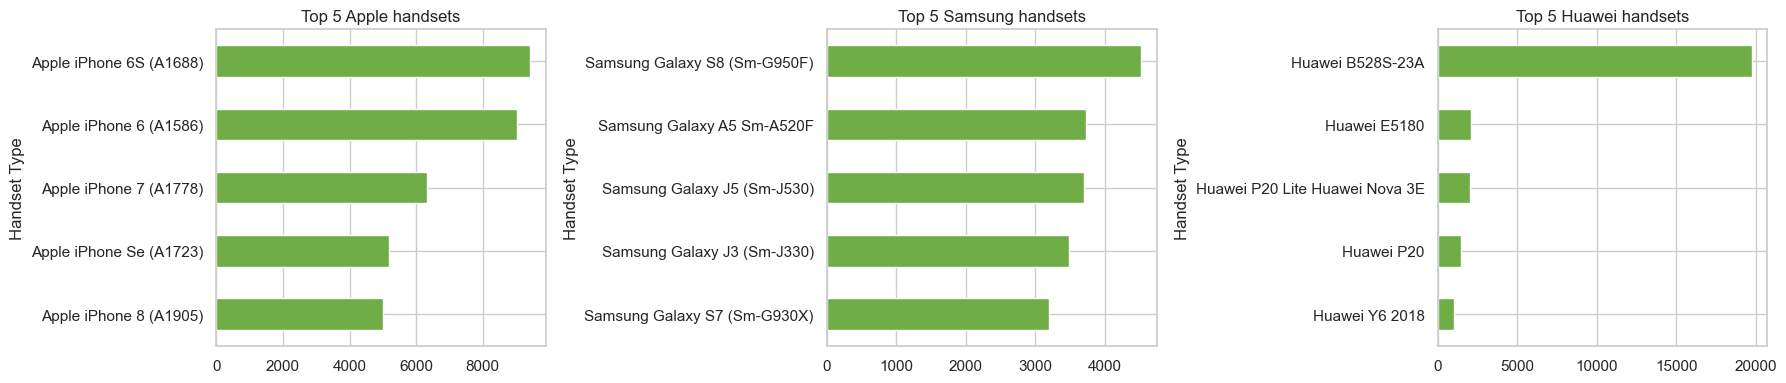

In [11]:
known = df[(df["Handset Type"] != "undefined") & (df["Handset Manufacturer"] != "undefined")]
top10_handsets = known["Handset Type"].value_counts().head(10)
top3_manu = known["Handset Manufacturer"].value_counts().head(3)
top5_per_manu = {m: known.loc[known["Handset Manufacturer"] == m, "Handset Type"].value_counts().head(5)
                 for m in top3_manu.index}

display(top10_handsets.to_frame("sessions")); display(top3_manu.to_frame("sessions"))
for m, s in top5_per_manu.items():
    print("\nTop 5 handsets for", m); display(s.to_frame("sessions"))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
top10_handsets.sort_values().plot(kind="barh", ax=ax[0], color="#4472c4", title="Top 10 handsets")
top3_manu.sort_values().plot(kind="barh", ax=ax[1], color="#ed7d31", title="Top 3 manufacturers")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, (m, s) in zip(ax, top5_per_manu.items()):
    s.sort_values().plot(kind="barh", ax=a, title=f"Top 5 {m} handsets", color="#70ad47")
plt.tight_layout(); plt.show()

**Analysis: handsets and manufacturers.**
- **Manufacturers:** Apple leads with 59,565 sessions, then Samsung (40,839) and Huawei (34,423). Apple is about 44% of the sessions of these three brands.
- **Handsets:** 7 of the top 10 models are iPhones (6S, 6, 7, SE, 8, Xr, X), 2 are Samsung (Galaxy S8, A5) and 1 is Huawei. The single biggest "handset" is the **Huawei B528S-23A (19,752 sessions)**, a 4G home router rather than a phone, so a large group of customers are fixed-wireless broadband users. It has more than twice the sessions of the next model (iPhone 6S, 9,419).
- **Business insight:** Apple's customer base is large and skews to older models (iPhone 6S, 6, 7, SE lead), which makes it the natural target for upgrade and trade-in offers and data bundles. Samsung's mid-range A5/J5/J3 models suggest value bundles, and the Huawei router base needs a home-broadband plan rather than a mobile one. In this data **Apple**, not Samsung, is the largest manufacturer, so handset partnerships should start with Apple.

### 2.2 Per-user aggregation (Task 1.1)
One row per customer (`MSISDN`): number of xDR sessions, total duration, total download and upload, and total volume per application. Sessions are counted as rows, because `Bearer Id` loses precision when opened in Excel.

In [12]:
def user_aggregate(df):
    g = df.dropna(subset=["MSISDN"]).groupby("MSISDN")
    agg = {"Duration_ms": "sum", "Total DL (Bytes)": "sum", "Total UL (Bytes)": "sum"}
    for a in APPS:
        agg[f"{a} Total"] = "sum"
    out = g.agg(agg)
    out.insert(0, "Sessions", g.size())
    out["Total Data"] = out["Total DL (Bytes)"] + out["Total UL (Bytes)"]
    return out

users = user_aggregate(df)
app_cols = [f"{a} Total" for a in APPS]
print("Sessions with a customer id:", int(df["MSISDN"].notna().sum()), "| Customers:", len(users))
users.head()

Sessions with a customer id: 148935 | Customers: 106856


,Sessions,Duration_ms,Total DL (Bytes),Total UL (Bytes),Social Media Total,Google Total,Email Total,Youtube Total,Netflix Total,Gaming Total,Other Total,Total Data
MSISDN,,,,,,,,,,,,
"33,601,001,722.00",1,"116,720,140.00","842,637,466.00","36,053,108.00","2,232,135.00","4,389,005.00","1,331,362.00","21,624,548.00","27,180,981.00","812,458,661.00","386,570,872.00","878,690,574.00"
"33,601,001,754.00",1,"181,230,963.00","120,755,184.00","36,104,459.00","2,660,565.00","5,334,863.00","3,307,781.00","12,432,223.00","11,221,763.00","119,750,078.00","281,710,071.00","156,859,643.00"
"33,601,002,511.00",1,"134,969,374.00","556,659,663.00","39,306,820.00","3,195,623.00","3,443,126.00","3,205,380.00","21,333,570.00","19,353,900.00","538,827,713.00","501,693,672.00","595,966,483.00"
"33,601,007,832.00",1,"49,878,024.00","401,993,172.00","20,327,526.00","280,294.00","9,678,493.00","2,284,670.00","6,977,321.00","1,942,092.00","391,126,127.00","35,279,702.00","422,320,698.00"
"33,601,008,617.00",2,"37,104,453.00","1,363,130,417.00","94,280,527.00","2,912,542.00","18,499,616.00","3,305,469.00","41,533,002.00","49,201,724.00","1,314,797,820.00","804,804,484.00","1,457,410,944.00"


**Analysis: per-user aggregation.** 148,935 sessions with a customer id collapse into **106,856 customers**, about 1.39 sessions each in the month. The first rows show the usual pattern: one session, a few hundred MB, and **Gaming and Other making up almost all of each user's volume**. Because totals are built after cleaning, `Total Data` equals DL + UL for every user. This table feeds every engagement and satisfaction result below.

### 2.3 Full exploratory data analysis (Task 1.2)

In [13]:
display(pd.DataFrame({"type": users.dtypes.astype(str), "example": users.iloc[0]}))
display(users.describe().T)

,type,example
Sessions,int64,1.00
Duration_ms,float64,"116,720,140.00"
Total DL (Bytes),float64,"842,637,466.00"
Total UL (Bytes),float64,"36,053,108.00"
Social Media Total,float64,"2,232,135.00"
Google Total,float64,"4,389,005.00"
Email Total,float64,"1,331,362.00"
Youtube Total,float64,"21,624,548.00"
Netflix Total,float64,"27,180,981.00"
Gaming Total,float64,"812,458,661.00"


,count,mean,std,min,25%,50%,75%,max
Sessions,"106,856.00",1.39,0.81,1.00,1.00,1.00,2.00,18.00
Duration_ms,"106,856.00","128,911,063.87","102,097,941.70","7,142,988.00","71,308,343.00","97,154,392.00","169,624,591.50","1,964,108,482.94"
Total DL (Bytes),"106,856.00","633,652,680.89","464,555,056.46","8,827,082.00","314,827,063.75","570,367,723.00","807,364,490.25","8,156,743,493.00"
Total UL (Bytes),"106,856.00","57,307,011.37","35,615,851.71","9,512,288.00","36,423,820.75","46,775,508.50","65,660,374.25","729,577,380.00"
Social Media Total,"106,856.00","2,547,966.82","1,908,038.04","1,563.00","1,211,281.50","2,303,756.00","3,307,509.00","43,374,779.00"
Google Total,"106,856.00","10,882,434.42","7,544,861.44","40,330.00","5,942,636.00","9,586,153.00","13,214,739.75","152,191,852.00"
Email Total,"106,856.00","3,148,795.81","2,222,400.10","18,176.00","1,674,481.00","2,799,824.50","3,847,197.50","42,418,782.00"
Youtube Total,"106,856.00","31,558,399.28","21,294,917.68","78,903.00","18,631,088.50","26,800,376.00","37,927,975.75","452,958,769.00"
Netflix Total,"106,856.00","31,538,332.31","21,289,556.97","184,569.00","18,555,972.75","26,718,889.50","37,976,957.00","399,519,079.00"
Gaming Total,"106,856.00","599,769,010.72","449,150,462.40","306,358.00","288,063,112.50","542,349,206.50","777,304,138.00","7,749,432,234.00"


**Analysis: variables and basic metrics.** `Sessions` is an integer count; the other 11 variables (duration, download, upload, seven app totals, total data) are continuous and numeric, so scaling is needed before PCA and k-means.
- **Typical customer:** median 1 session, 97 million ms (about 27 hours) and 618 MB of data; the mean is 691 MB.
- **Skew:** the mean is above the median for every variable, so usage is right-skewed. The largest customer (8.85 GB) is about 12.8 times the mean.
- **Floor:** the smallest customer used 33 MB, so there are no dormant accounts.
- **App scale:** Gaming and Other average about 600 MB per user each, against 2.5 MB for Social Media and 3.1 MB for Email.

In [14]:
disp = users.describe().T
disp["variance"] = users.var()
disp["IQR"] = disp["75%"] - disp["25%"]
disp["range"] = disp["max"] - disp["min"]
disp["CV"] = disp["std"] / disp["mean"]
disp["skew"] = users.skew()
disp[["mean", "50%", "std", "IQR", "range", "CV", "skew"]]

,mean,50%,std,IQR,range,CV,skew
Sessions,1.39,1.00,0.81,1.00,17.00,0.58,3.35
Duration_ms,"128,911,063.87","97,154,392.00","102,097,941.70","98,316,248.50","1,956,965,494.94",0.79,2.70
Total DL (Bytes),"633,652,680.89","570,367,723.00","464,555,056.46","492,537,426.50","8,147,916,411.00",0.73,2.15
Total UL (Bytes),"57,307,011.37","46,775,508.50","35,615,851.71","29,236,553.50","720,065,092.00",0.62,2.90
Social Media Total,"2,547,966.82","2,303,756.00","1,908,038.04","2,096,227.50","43,373,216.00",0.75,2.09
Google Total,"10,882,434.42","9,586,153.00","7,544,861.44","7,272,103.75","152,151,522.00",0.69,2.40
Email Total,"3,148,795.81","2,799,824.50","2,222,400.10","2,172,716.50","42,400,606.00",0.71,2.37
Youtube Total,"31,558,399.28","26,800,376.00","21,294,917.68","19,296,887.25","452,879,866.00",0.67,2.54
Netflix Total,"31,538,332.31","26,718,889.50","21,289,556.97","19,420,984.25","399,334,510.00",0.68,2.48
Gaming Total,"599,769,010.72","542,349,206.50","449,150,462.40","489,241,025.50","7,749,125,876.00",0.75,2.07


**Analysis: dispersion.**
- The coefficient of variation (CV) runs from 0.58 (Sessions) to 0.79 (Duration): uneven usage, but no variable passes 1, partly because outlier replacement trimmed the tails. Skewness is positive everywhere (2.0 to 3.4).
- Duration is the most dispersed variable (range of about 1.96 billion ms, or 22.7 days).
- The IQR of `Total Data` is 499 MB, so the middle half of customers is spread across a wide band.
- Variances are huge only because of the units (bytes squared); compare variables with CV, not variance.

**Graphical univariate analysis:** histograms (shape, skew) and boxplots (outliers) on a log scale so small apps stay visible.

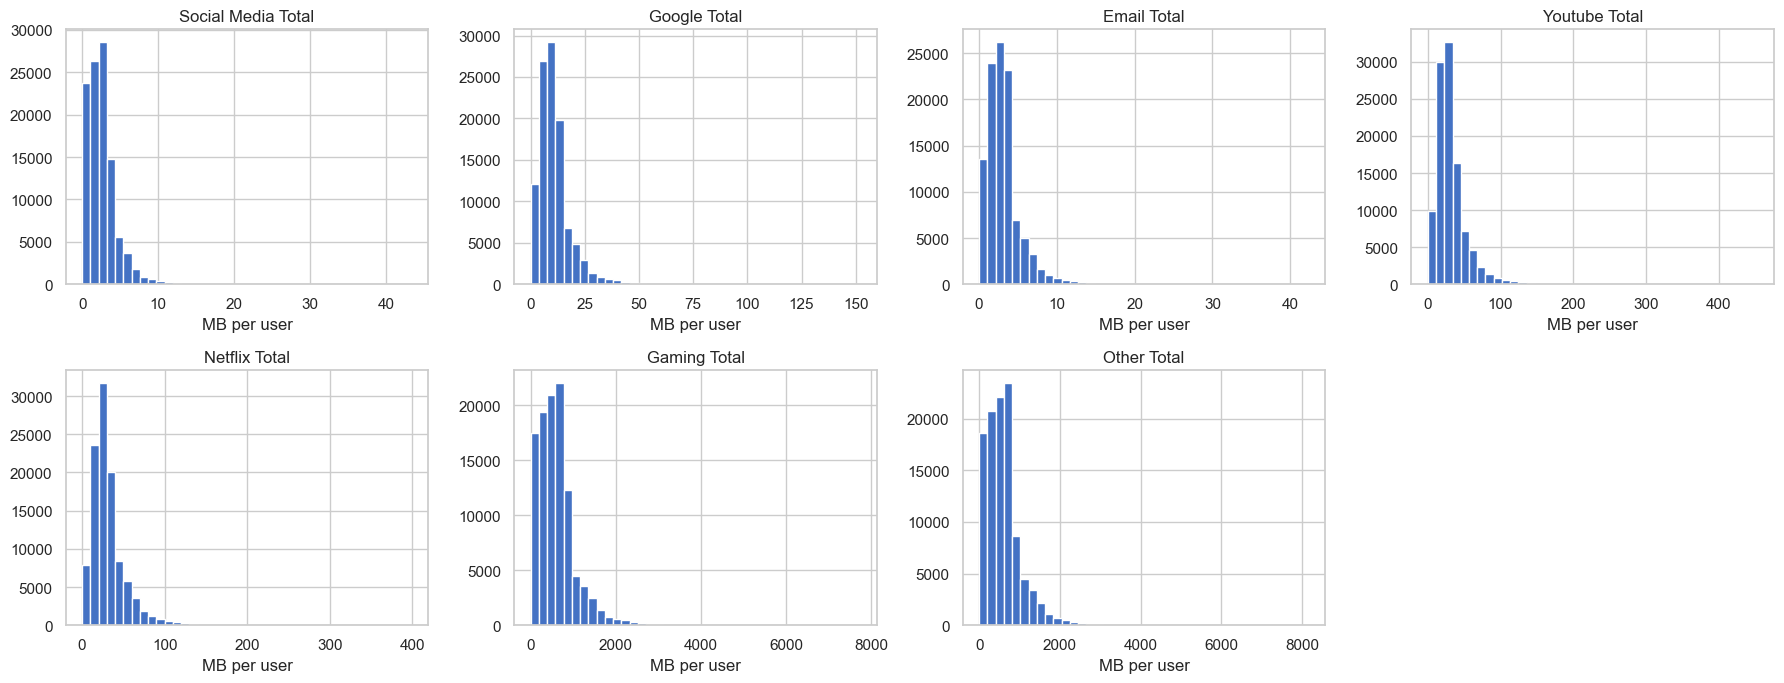

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, c in zip(axes, app_cols):
    ax.hist(users[c] / 1e6, bins=40, color="#4472c4"); ax.set_title(c); ax.set_xlabel("MB per user")
axes[-1].axis("off"); plt.tight_layout(); plt.show()

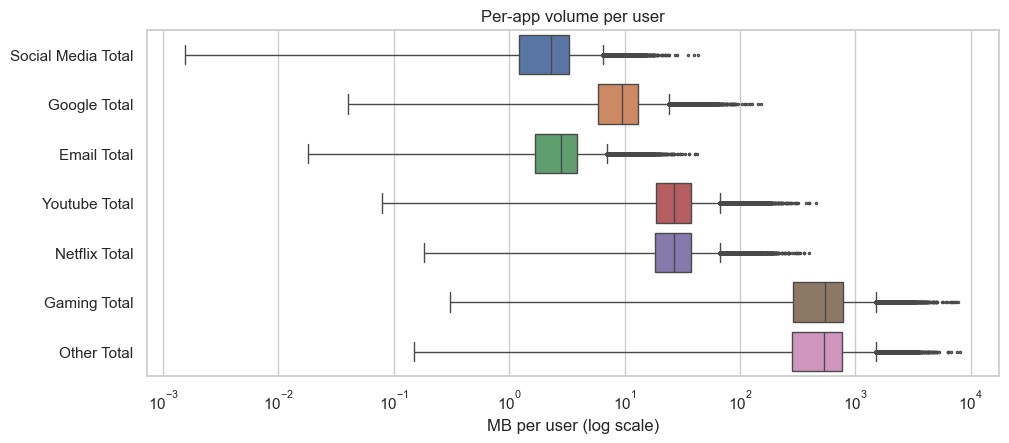

In [16]:
sns_size(11, 4.5)
ax = sns.boxplot(data=users[app_cols] / 1e6, orient="h", showfliers=True, fliersize=1.5)
ax.set_xscale("log"); ax.set_xlabel("MB per user (log scale)"); ax.set_title("Per-app volume per user")
sns_size()

**Analysis: graphical univariate.** Every histogram is right-skewed: most users sit at the low end with a long tail of heavy users. On the log-scale boxplot the apps separate into two tiers: **Gaming and Other** (medians around 540 MB per user) and everything else (Social Media, Email, Google, YouTube, Netflix at 2 to 30 MB). Heavy-tail outliers exist in every app, so a small number of users carry a lot of volume.

**Bivariate analysis:** each application against total DL+UL.

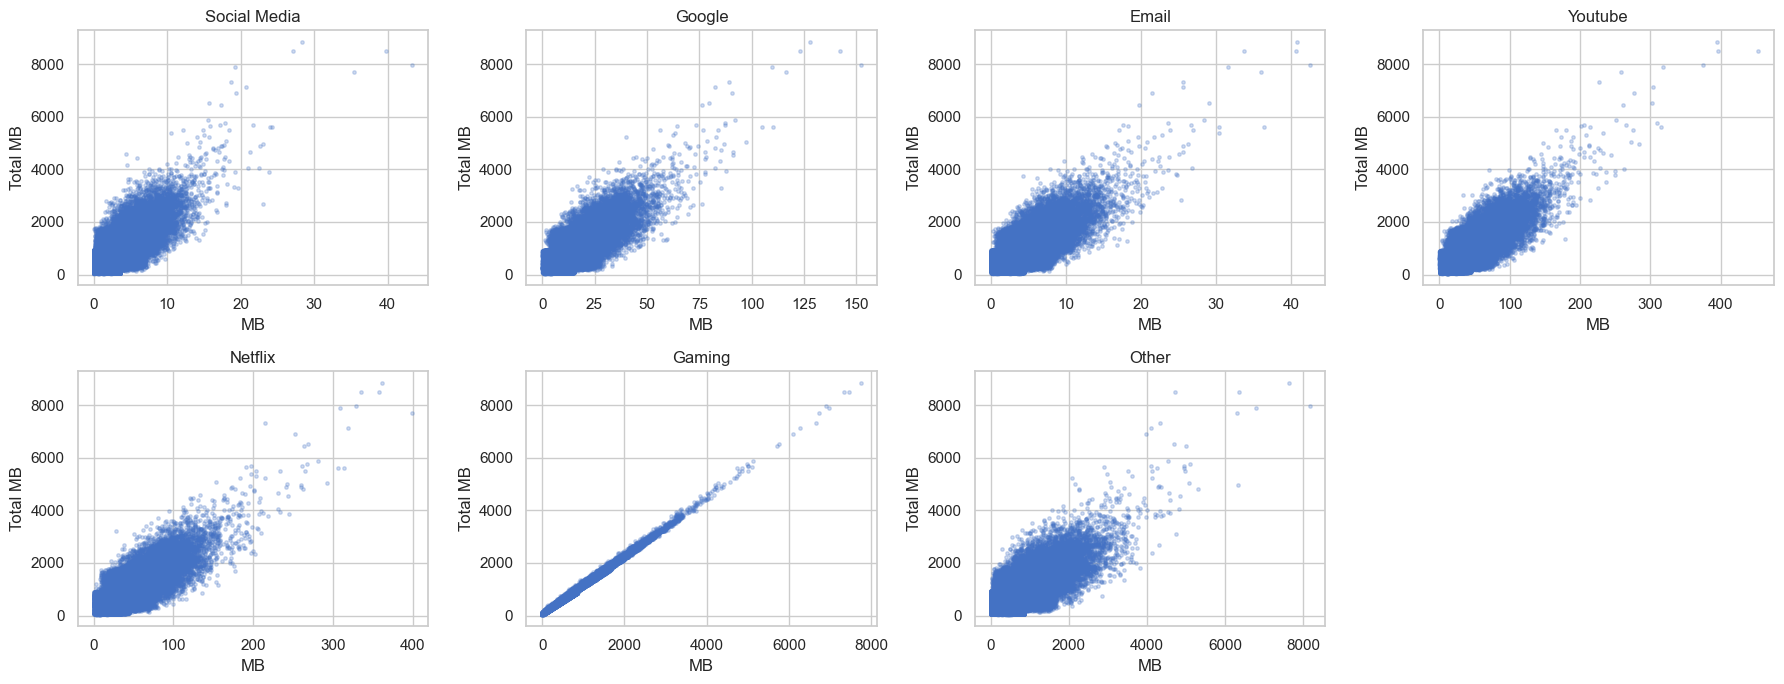

,correlation with Total Data
Gaming Total,1.00
Youtube Total,0.71
Netflix Total,0.70
Google Total,0.68
Email Total,0.66
Social Media Total,0.62
Other Total,0.62


In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, a in zip(axes, APPS):
    ax.scatter(users[f"{a} Total"] / 1e6, users["Total Data"] / 1e6, s=6, alpha=0.25, color="#4472c4")
    ax.set_title(a); ax.set_xlabel("MB"); ax.set_ylabel("Total MB")
axes[-1].axis("off"); plt.tight_layout(); plt.show()
users[app_cols].corrwith(users["Total Data"]).sort_values(ascending=False).to_frame("correlation with Total Data")

**Analysis: bivariate (app vs total data).** Total traffic is almost entirely driven by **Gaming** (correlation 1.00, tight straight line in the scatter). The other apps follow: YouTube 0.71, Netflix 0.70, Google 0.68, Email 0.66, Social Media and Other 0.62, shown as loose clouds. Part of the gaming relationship is mechanical (gaming is a large share of the total), but the practical message holds: to forecast network load, watch gaming volume first.

**Decile analysis:** users are cut into 10 groups by total duration. The five longest-duration deciles (6 to 10) are compared on total data.

,users,duration_ms,total_data,% of all data
Decile,,,,
6,10686,"1,168,432,898,646.92","6,399,377,492,243.34",8.67
7,10685,"1,485,261,411,937.64","6,114,194,683,663.42",8.28
8,10686,"1,793,063,490,802.34","7,408,424,005,276.34",10.03
9,10685,"2,197,704,524,032.01","8,635,761,334,756.70",11.70
10,10686,"3,831,000,463,458.68","16,221,370,980,322.65",21.97


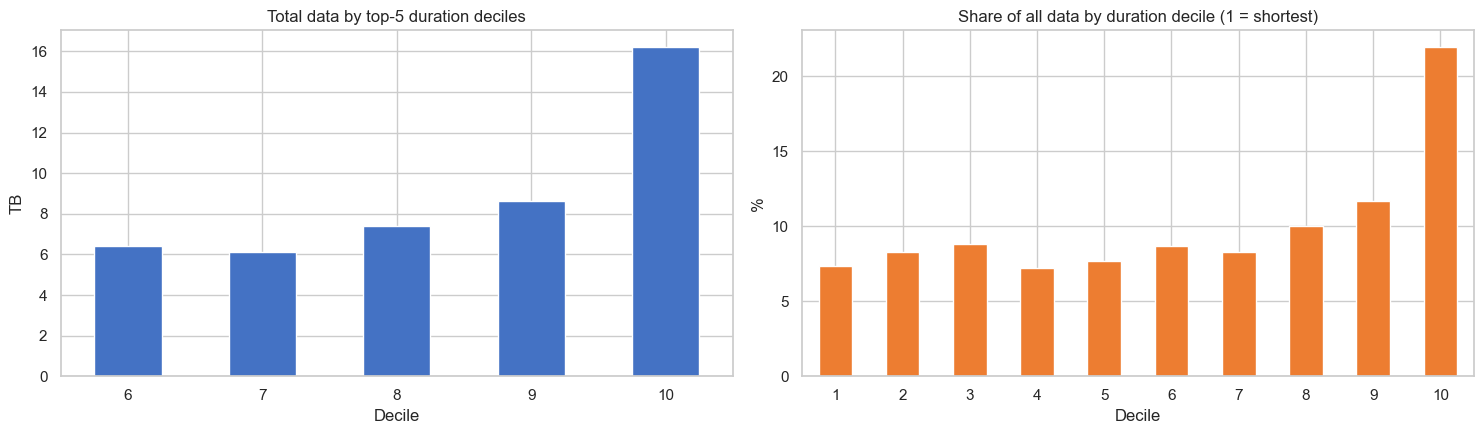

In [18]:
u = users.copy()
u["Decile"] = pd.qcut(u["Duration_ms"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
dec_all = u.groupby("Decile").agg(users=("Total Data", "size"), duration_ms=("Duration_ms", "sum"), total_data=("Total Data", "sum"))
dec_all["% of all data"] = dec_all["total_data"] / dec_all["total_data"].sum() * 100
display(dec_all[dec_all.index > 5])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
(dec_all.loc[6:, "total_data"] / 1e12).plot(kind="bar", ax=ax[0], color="#4472c4", rot=0)
ax[0].set_title("Total data by top-5 duration deciles"); ax[0].set_ylabel("TB")
dec_all["% of all data"].plot(kind="bar", ax=ax[1], color="#ed7d31", rot=0)
ax[1].set_title("Share of all data by duration decile (1 = shortest)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Analysis: duration deciles.** Among deciles 6 to 10, total data rises with duration (apart from a small dip at decile 7) and jumps at the top: decile 10 carries **16.2 TB (22.0% of all data)** against 6.4, 6.1, 7.4 and 8.6 TB for deciles 6 to 9. The five longest-duration deciles together hold about **61% of all traffic**, and the single longest 10% of users produce about 36% of that. Long-connected users are the most valuable and the most demanding group on the network.

**Correlation analysis** of the seven application volumes (plus total data).

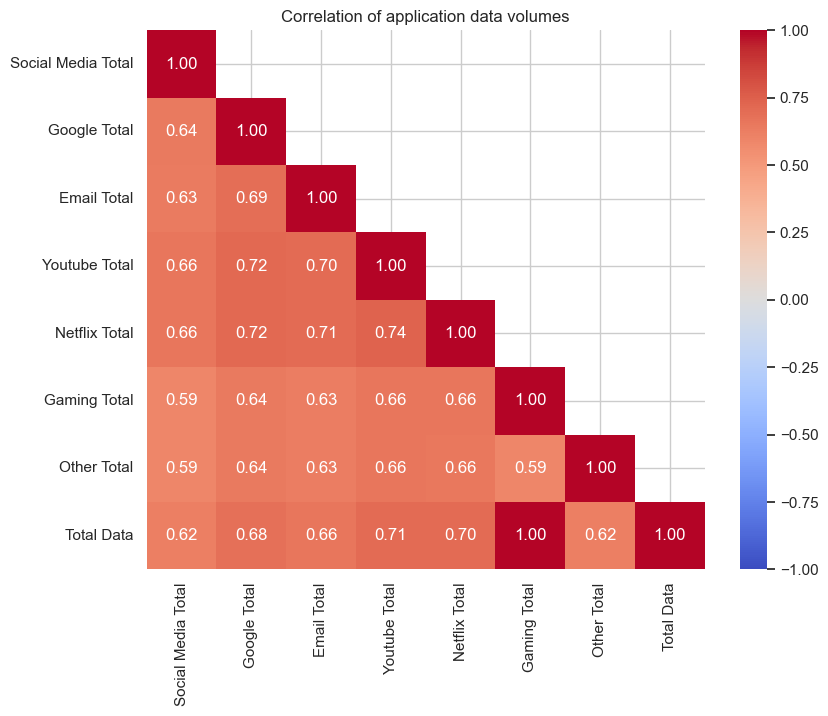

In [19]:
corr = users[app_cols + ["Total Data"]].corr()
sns_size(9, 7)
ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, mask=np.triu(np.ones_like(corr, dtype=bool), 1))
ax.set_title("Correlation of application data volumes")
sns_size()

**Analysis: correlation of apps.** All app volumes correlate **positively and moderately (0.59 to 0.74)**. The strongest pair is YouTube and Netflix (0.74), then Google with YouTube/Netflix (0.72): video users also use search and other services. Gaming and Other are the least tied to the rest (0.59 to 0.66). No pair exceeds 0.8, so no application is redundant. The common pattern is simply that heavy users are heavy on everything.

**Dimensionality reduction (PCA)** on the seven application volumes, after `StandardScaler`.

,explained variance,cumulative
PC1,0.71,0.71
PC2,0.06,0.77
PC3,0.06,0.82
PC4,0.05,0.88
PC5,0.04,0.92
PC6,0.04,0.96
PC7,0.04,1.00


,PC1,PC2
Social Media Total,0.36,-0.12
Google Total,0.39,0.00
Email Total,0.38,-0.03
Youtube Total,0.39,-0.01
Netflix Total,0.39,0.01
Gaming Total,0.36,0.77
Other Total,0.36,-0.62


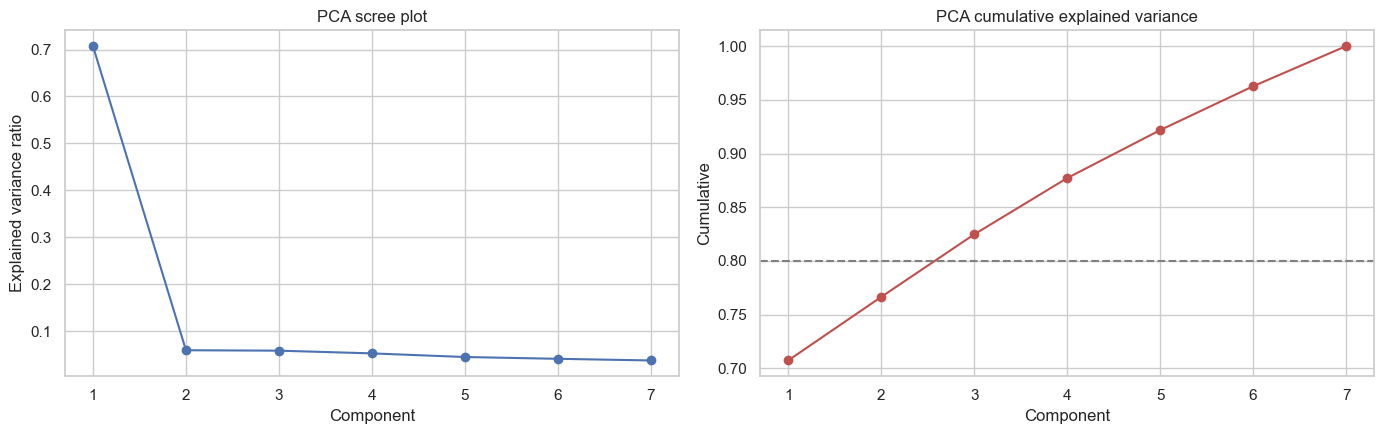

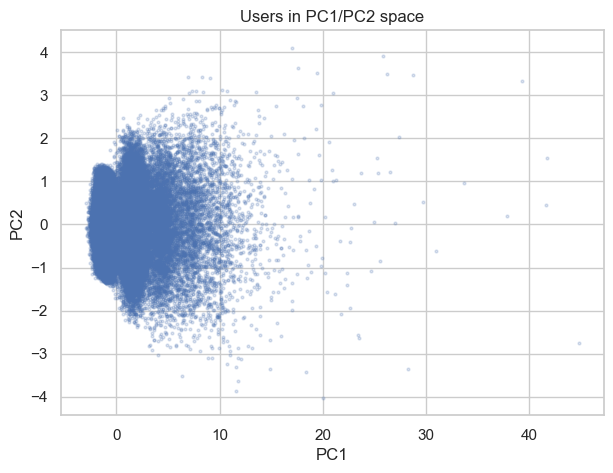

In [20]:
Xs = StandardScaler().fit_transform(users[app_cols])
pca = PCA().fit(Xs)
evr = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(app_cols))])
display(evr.to_frame("explained variance").assign(cumulative=evr.cumsum()))
display(pd.DataFrame(pca.components_[:2].T, index=app_cols, columns=["PC1", "PC2"]))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(range(1, 8), evr.values, "o-"); ax[0].set_title("PCA scree plot")
ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance ratio")
ax[1].plot(range(1, 8), evr.cumsum().values, "o-", color="#c0504d"); ax[1].axhline(0.8, ls="--", color="grey")
ax[1].set_title("PCA cumulative explained variance"); ax[1].set_xlabel("Component"); ax[1].set_ylabel("Cumulative")
plt.tight_layout(); plt.show()

scores_pc = pca.transform(Xs)[:, :2]
plt.figure(figsize=(7, 5)); plt.scatter(scores_pc[:, 0], scores_pc[:, 1], s=4, alpha=0.2)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Users in PC1/PC2 space"); plt.show()

**Analysis: PCA.**
1. **PC1 explains 71%** of the variance; PC1 and PC2 together explain 77%.
2. All seven apps load almost equally on PC1 (0.36 to 0.39), with Google, YouTube and Netflix slightly highest (0.39).
3. PC1 is a **general usage-volume axis** (heavy vs light user), not a specific app. PC2 is a contrast between **Gaming (+0.77) and Other (-0.62)**.
4. **Three components** reach about 82%, so 80% of the information needs three, not seven, dimensions. The scree plot flattens after PC1 and the cumulative curve crosses 80% at PC3.

### Task 1: business insights
- **Target Apple first.** Apple is the largest manufacturer (59,565 sessions), with an old iPhone base (6S, 6, 7, SE): trade-in and upgrade campaigns plus data bundles have the biggest reach. Samsung and Huawei follow.
- **Serve the router segment separately.** The Huawei B528S-23A is the top device and is a home-broadband box. These customers need a fixed-wireless plan, not a phone plan.
- **Plan capacity around gaming.** Gaming is the dominant traffic driver, and the longest-connected 10% of users produce 22% of all data.
- **Usage is one dimension.** PCA shows heavy users are heavy across every app, so a simple "usage tier" is enough for segmentation.

## Part 3: Task 2, User Engagement Analysis
Metrics: **session frequency**, **session duration** and **total traffic** (DL+UL).

### 3.1 Top 10 customers per engagement metric (Task 2.1)


In [21]:
ENG = ["Sessions", "Duration_ms", "Total Data"]
for m in ENG:
    print(f"\nTop 10 customers by {m}"); display(users[m].nlargest(10).to_frame(m))


Top 10 customers by Sessions


,Sessions
MSISDN,
"33,626,320,676.00",18
"33,614,892,860.00",17
"33,625,779,332.00",17
"33,659,725,664.00",16
"33,675,877,202.00",15
"33,760,536,639.00",15
"33,667,163,239.00",13
"33,603,127,838.00",12
"33,604,515,716.00",12



Top 10 customers by Duration_ms


,Duration_ms
MSISDN,
"33,659,725,664.00","1,964,108,482.94"
"33,626,320,676.00","1,867,500,062.32"
"33,675,877,202.00","1,803,762,068.94"
"33,659,359,429.00","1,771,448,889.38"
"33,614,892,860.00","1,760,476,588.32"
"33,760,536,639.00","1,715,576,013.54"
"33,625,779,332.00","1,692,856,620.51"
"33,664,712,899.00","1,533,644,801.16"
"33,786,323,068.00","1,474,711,546.76"



Top 10 customers by Total Data


,Total Data
MSISDN,
"33,614,892,860.00","8,846,226,494.00"
"33,760,536,639.00","8,514,773,963.00"
"33,625,779,332.00","8,499,620,722.00"
"33,626,320,676.00","7,971,167,261.00"
"33,675,877,202.00","7,891,110,608.00"
"33,659,725,664.00","7,705,862,783.00"
"33,666,464,084.00","7,308,500,938.00"
"33,760,413,819.00","7,132,370,514.00"
"33,664,712,899.00","6,903,962,803.32"


**Analysis: top-10 customers.** The same few customers appear in all three lists: for example `3362632****` is first in sessions (18) and fourth in data, `3361489****` is second in sessions and first in data (**8.85 GB**), and `3365972****` has the longest duration (about 1.96 billion ms, or 22.7 days). A small group is simultaneously the most frequent, longest and heaviest, which is the group to protect with service quality and premium offers.

### 3.2 Normalise and run k-means (k = 3) (Task 2.1)
Min-max scaling puts all three metrics on 0 to 1; otherwise `Total Data` (billions of bytes) would decide every cluster.

,users,sessions_mean,duration_h_mean,data_GB_mean,data_TB_total,% users,% of traffic
Persona,,,,,,,
Light Users,80760,1.04,26.00,0.50,40.27,75.58,54.54
Regular Users,21753,2.15,54.90,1.11,24.08,20.36,32.62
Heavy Users,4343,4.19,122.57,2.18,9.48,4.06,12.84


Sessions                   Duration_ms                   \
                   min max mean    sum           min              max   
Persona                                                                 
Light Users          1   2 1.04  84085  7,142,988.00   261,422,541.00   
Regular Users        1   4 2.15  46663 18,235,797.00   514,317,346.00   
Heavy Users          3  18 4.19  18187 85,556,232.00 1,964,108,482.94   

                                                      Total Data  \
                        mean                  sum            min   
Persona                                                            
Light Users    93,606,623.23 7,559,670,892,364.90  33,249,009.00   
Regular Users 197,624,024.40 4,298,915,402,776.09 167,774,602.00   
Heavy Users   441,246,683.27 1,916,334,345,422.18 661,851,764.00   

                                                                       
                           max             mean                   sum  
Persona                                                                
Light Users   1,030,485,444.00   498,587,951.82 40,265,962,988,660.57  
Regular Users 2,509,056,852.00 1,107,147,552.35 24,083,780,706,286.79  
Heavy Users   8,846,226,494.00 2,183,616,205.77  9,483,445,181,643.31

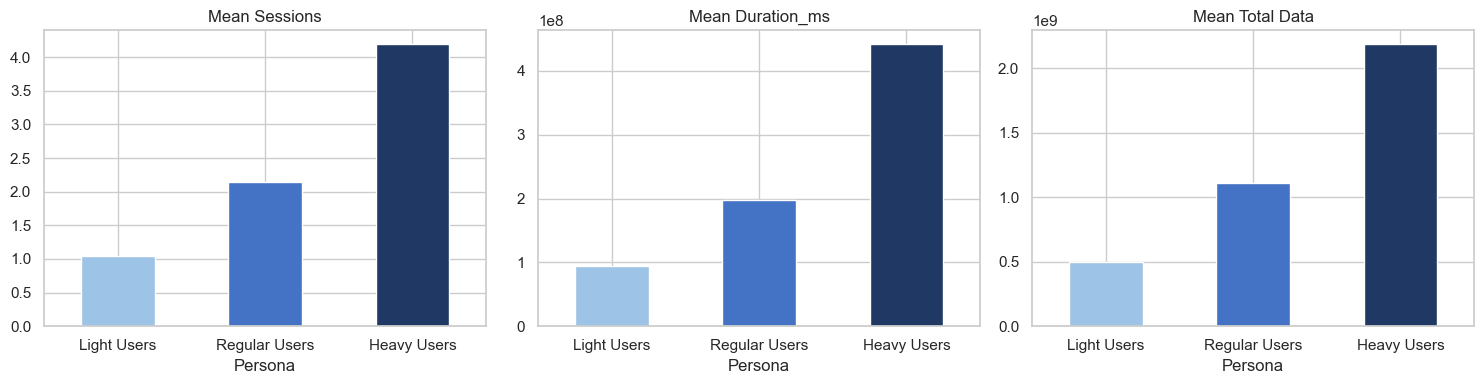

In [22]:
eng_scaler = MinMaxScaler()
X_eng = eng_scaler.fit_transform(users[ENG])
km_eng = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_eng)
eng = users[ENG].copy(); eng["Cluster"] = km_eng.labels_

# Give clusters business names, ordered by mean traffic
order = eng.groupby("Cluster")["Total Data"].mean().sort_values().index.tolist()
persona = dict(zip(order, ["Light Users", "Regular Users", "Heavy Users"]))
eng["Persona"] = eng["Cluster"].map(persona)

prof_eng = eng.groupby("Persona").agg(users=("Sessions", "size"),
                                      sessions_mean=("Sessions", "mean"), duration_h_mean=("Duration_ms", lambda s: s.mean() / 3.6e6),
                                      data_GB_mean=("Total Data", lambda s: s.mean() / 1e9),
                                      data_TB_total=("Total Data", lambda s: s.sum() / 1e12))
prof_eng["% users"] = prof_eng["users"] / prof_eng["users"].sum() * 100
prof_eng["% of traffic"] = prof_eng["data_TB_total"] / prof_eng["data_TB_total"].sum() * 100
prof_eng = prof_eng.loc[["Light Users", "Regular Users", "Heavy Users"]]
display(prof_eng)
display(eng.groupby("Persona")[ENG].agg(["min", "max", "mean", "sum"]).loc[["Light Users", "Regular Users", "Heavy Users"]])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ENG):
    eng.groupby("Persona")[m].mean().loc[["Light Users", "Regular Users", "Heavy Users"]].plot(kind="bar", ax=a, rot=0, title=f"Mean {m}", color=["#9dc3e6", "#4472c4", "#1f3864"])
plt.tight_layout(); plt.show()

### 3.3 Choosing k: elbow method and silhouette score (Task 2.1)

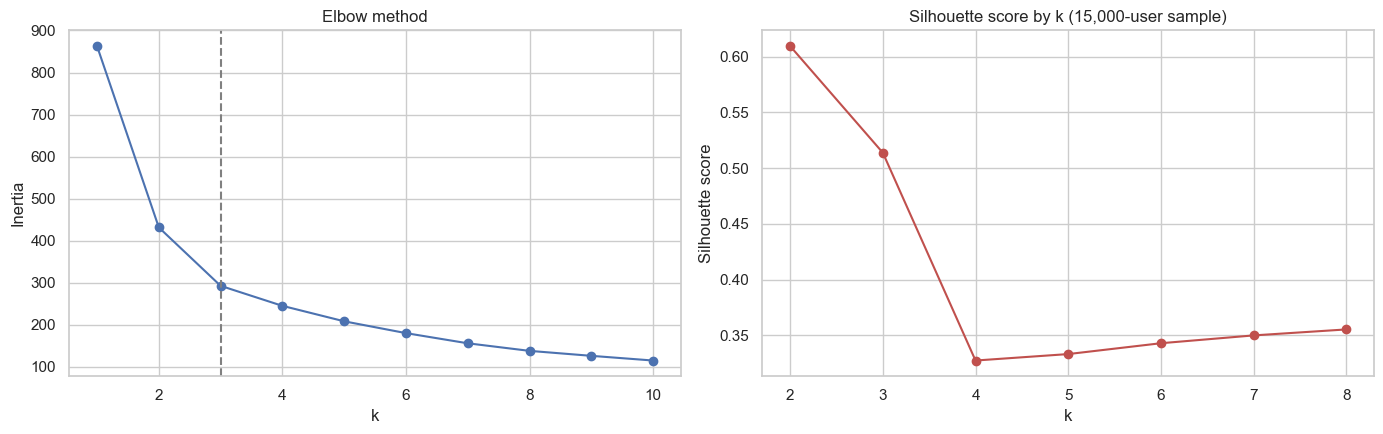

,k,inertia,silhouette,inertia drop
0,1,862.80,NaN,NaN
1,2,431.76,0.61,431.03
2,3,292.95,0.51,138.81
3,4,245.38,0.33,47.57
4,5,208.62,0.33,36.76
5,6,180.53,0.34,28.09
6,7,156.36,0.35,24.17
7,8,138.35,0.36,18.01
8,9,126.54,NaN,11.81
9,10,115.37,NaN,11.17


In [23]:
ks = list(range(1, 11))
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_eng).inertia_ for k in ks]

sil_ks = list(range(2, 9))
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_eng), 15000, replace=False)
sil = []
for k in sil_ks:
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_eng)
    sil.append(silhouette_score(X_eng[sample_idx], lab[sample_idx]))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia"); ax[0].set_title("Elbow method")
ax[0].axvline(3, ls="--", color="grey")
ax[1].plot(sil_ks, sil, "o-", color="#c0504d"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette score by k (15,000-user sample)")
plt.tight_layout(); plt.show()
sel = pd.DataFrame({"k": ks, "inertia": inertia}).merge(pd.DataFrame({"k": sil_ks, "silhouette": sil}), how="left", on="k")
sel["inertia drop"] = sel["inertia"].diff().abs()
sel

**Analysis: why k = 3.**
- **Elbow:** inertia drops by 431 (k=1 to 2) and 139 (k=2 to 3), then only 48 and 37; the curve bends at **k = 3**.
- **Silhouette:** the score is highest at k=2 (0.61), still good at k=3 (0.51) and falls to 0.33 at k=4 and stays between 0.33 and 0.36 for larger k, so clusters start overlapping after three.
- **Decision:** k=2 only separates light from heavy and hides the middle group. k=3 sits at the elbow, keeps good separation (0.51) and gives three business personas that stakeholders can act on, so we use **k = 3**.

<div style="border-left:6px solid #1f4e79;background:#eaf2fb;padding:10px 14px;border-radius:4px;color:#111"><b>KEY RESULT: number of engagement clusters</b><br><b>k = 3</b>. The elbow bends at 3; silhouette is highest at k=2 but k=2 hides the middle group, and it falls sharply after k=3.</div>

### 3.4 Radar chart: cluster comparison

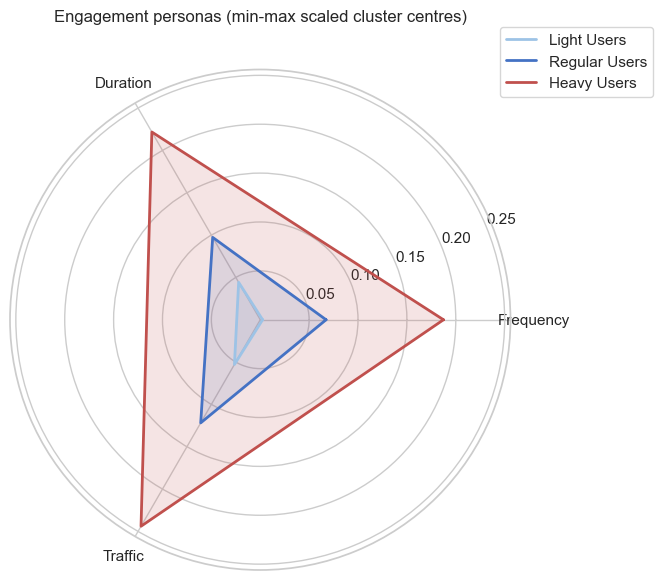

,Frequency,Duration,Traffic
Light Users,0.00,0.04,0.05
Regular Users,0.07,0.10,0.12
Heavy Users,0.19,0.22,0.24


In [24]:
centers = pd.DataFrame(km_eng.cluster_centers_, columns=["Frequency", "Duration", "Traffic"])
centers.index = [persona[i] for i in centers.index]
centers = centers.loc[["Light Users", "Regular Users", "Heavy Users"]]

labels = list(centers.columns); angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist(); angles += angles[:1]
fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw=dict(polar=True))
for (name, row), col in zip(centers.iterrows(), ["#9dc3e6", "#4472c4", "#c0504d"]):
    vals = row.tolist() + row.tolist()[:1]
    ax.plot(angles, vals, label=name, color=col, lw=2); ax.fill(angles, vals, color=col, alpha=0.15)
ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels); ax.set_title("Engagement personas (min-max scaled cluster centres)", y=1.08)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1)); plt.show()
centers

**Analysis: engagement personas (k = 3).**

| Persona | Users | Share | Sessions | Hours online | Data per user | Share of traffic |
|---|---|---|---|---|---|---|
| Light Users | 80,760 | 75.6% | 1.04 | 26 | 0.50 GB | 54.5% |
| Regular Users | 21,753 | 20.4% | 2.15 | 55 | 1.11 GB | 32.6% |
| Heavy Users | 4,343 | 4.1% | 4.19 | 123 | 2.18 GB | 12.8% |

- Heavy Users are only **4.1% of customers but 12.8% of traffic (about 3 times their share)**; Regular and Heavy together are 24% of users and 45% of traffic.
- The radar chart shows the three groups are ordered the same way on all three axes, so frequency, duration and traffic move together. Heavy Users have 3 to 18 sessions and up to 8.8 GB: they are the accounts to prioritise for capacity and retention. The Light group is the volume base and the main upsell opportunity.

### 3.5 Top users per application and the top 3 applications (Task 2.1)


Top 10 users: Social Media


,Social Media (MB)
MSISDN,
"33,626,320,676.00",43.37
"33,760,536,639.00",39.78
"33,659,725,664.00",35.41
"33,614,892,860.00",28.29
"33,625,779,332.00",27.14
"33,667,163,239.00",24.25
"33,786,323,068.00",23.97
"33,669,068,942.00",23.80
"33,603,127,838.00",23.08



Top 10 users: Google


,Google (MB)
MSISDN,
"33,626,320,676.00",152.19
"33,625,779,332.00",142.31
"33,614,892,860.00",127.97
"33,760,536,639.00",123.22
"33,659,725,664.00",116.52
"33,786,323,068.00",110.25
"33,675,877,202.00",109.86
"33,667,163,239.00",105.03
"33,761,268,199.00",97.09



Top 10 users: Email


,Email (MB)
MSISDN,
"33,626,320,676.00",42.42
"33,614,892,860.00",40.79
"33,625,779,332.00",40.63
"33,786,323,068.00",36.31
"33,659,725,664.00",36.00
"33,760,536,639.00",33.69
"33,675,877,202.00",31.51
"33,665,460,546.00",30.42
"33,667,163,239.00",30.34


(All seven applications are stored in top10_app.)


,share %,TB
Gaming Total,46.93,64.09
Other Total,46.83,63.95
Youtube Total,2.47,3.37
Netflix Total,2.47,3.37
Google Total,0.85,1.16
Email Total,0.25,0.34
Social Media Total,0.20,0.27


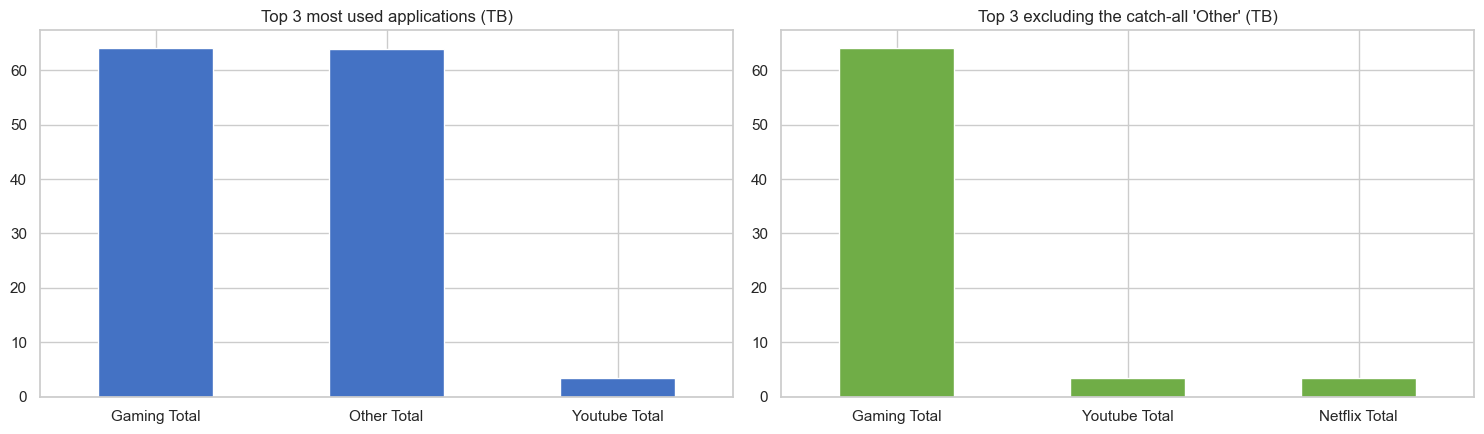

In [25]:
top10_app = {a: users[f"{a} Total"].nlargest(10) for a in APPS}
for a in APPS[:3]:
    print(f"\nTop 10 users: {a}"); display((top10_app[a] / 1e6).to_frame(f"{a} (MB)"))
print("(All seven applications are stored in top10_app.)")

app_tot = users[app_cols].sum().sort_values(ascending=False)
app_share = (app_tot / app_tot.sum() * 100).to_frame("share %").assign(TB=app_tot / 1e12)
display(app_share)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
(app_tot.head(3) / 1e12).plot(kind="bar", ax=ax[0], rot=0, color="#4472c4", title="Top 3 most used applications (TB)")
(app_tot.drop("Other Total") / 1e12).head(3).plot(kind="bar", ax=ax[1], rot=0, color="#70ad47", title="Top 3 excluding the catch-all 'Other' (TB)")
plt.tight_layout(); plt.show()

**All seven applications (Task 2.1 asks for the top 10 users per application).** The cell above prints three; this one prints every application side by side (MB per user).

In [26]:
top10_all = pd.DataFrame({a: (users[f"{a} Total"].nlargest(10) / 1e6).round(1).values for a in APPS},
                         index=[f"#{i}" for i in range(1, 11)])
display(top10_all.rename_axis("rank"))
print("MSISDN of the #1 user per application:")
display(pd.Series({a: int(users[f"{a} Total"].idxmax()) for a in APPS}, name="MSISDN").to_frame())

,Social Media,Google,Email,Youtube,Netflix,Gaming,Other
rank,,,,,,,
#1,43.40,152.20,42.40,453.00,399.50,"7,749.40","8,167.90"
#2,39.80,142.30,40.80,396.30,361.40,"7,461.00","7,639.30"
#3,35.40,128.00,40.60,394.40,357.00,"7,326.70","6,798.50"
#4,28.30,123.20,36.30,374.50,334.60,"6,970.60","6,354.60"
#5,27.10,116.50,36.00,317.40,328.70,"6,887.60","6,326.70"
#6,24.20,110.30,33.70,315.20,318.30,"6,725.60","6,317.40"
#7,24.00,109.90,31.50,308.80,313.90,"6,646.30","5,305.40"
#8,23.80,105.00,30.40,303.20,309.10,"6,268.60","5,117.80"
#9,23.10,97.10,30.30,302.70,305.90,"6,103.90","5,077.80"


MSISDN of the #1 user per application:


,MSISDN
Social Media,33626320676
Google,33626320676
Email,33626320676
Youtube,33625779332
Netflix,33659725664
Gaming,33614892860
Other,33626320676


**Analysis: top users per app and top 3 apps.**
- The top Social Media, Google and Email users are the same heavy customers seen earlier (for example `3362632****`), which confirms the overlap.
- **Share of app traffic:** Gaming 64.1 TB (46.9%), Other 64.0 TB (46.8%), YouTube 3.4 TB (2.5%), Netflix 3.4 TB (2.5%), Google 0.9%, Email 0.25%, Social Media 0.2%.
- `Other` is a catch-all, not a real application, so the real top 3 are **Gaming, YouTube and Netflix**. Video streaming is clearly second after gaming.
- Caution: Gaming and Other have almost identical totals, which is unusual. Validate the app-level split with the data owner before presenting it as fact.
- **The app totals do not reconcile with Total Data:** the seven app totals add up to 136.6 TB, about 1.85 times the Total Data (DL + UL) of 73.8 TB. The shares above are therefore shares of the app total, not of Total Data, and this is a second reason to validate the app-level fields.

### Task 2: business insights
- **Protect the 4% who drive 13% of traffic.** Heavy Users are the highest-value, highest-load accounts: prioritise their network quality and offer premium plans.
- **Upsell the Light base.** Three in four customers use about 0.5 GB and one session a month; a modest move up to the Regular tier adds more traffic than any other action.
- **Gaming and video are the product.** Gaming, YouTube and Netflix are the real traffic drivers, so low-latency and video-optimised plans are the most relevant offers.

### 3.6 Tables for the slides: top handsets, top customers per metric and per application
Task 1 asks for the top 5 handsets per top-3 manufacturer and Task 2 asks for the top 10 customers per engagement metric and per application. They are collected here in slide-ready form and saved to `data/processed/slide_tables/`.

In [27]:
SLIDE_DIR = os.path.join("data", "processed", "slide_tables"); os.makedirs(SLIDE_DIR, exist_ok=True)

# Task 1: top 5 handsets for each of the top 3 manufacturers
t5 = pd.concat({m: s.rename_axis("Handset").reset_index(name="Sessions").set_index(pd.RangeIndex(1, len(s) + 1, name="Rank"))
                for m, s in top5_per_manu.items()}, axis=1)
print("Top 5 handsets per top-3 manufacturer"); display(t5)
t5.to_csv(os.path.join(SLIDE_DIR, "top5_handsets_per_manufacturer.csv"))

# Task 2: top 10 customers per engagement metric
tm = pd.concat({m: users[m].nlargest(10).rename_axis("MSISDN").reset_index(name=m).set_index(pd.RangeIndex(1, 11, name="Rank"))
                for m in ENG}, axis=1)
tm.columns = pd.MultiIndex.from_tuples([(a, "MSISDN" if b == "MSISDN" else "Value") for a, b in tm.columns])
tm = tm.astype({(m, "MSISDN"): "int64" for m in ENG})
print("Top 10 customers per engagement metric"); display(tm)
tm.to_csv(os.path.join(SLIDE_DIR, "top10_customers_per_engagement_metric.csv"))

# Task 2: top 10 customers per application (MB)
ta = pd.concat({a: users[f"{a} Total"].nlargest(10).rename_axis("MSISDN").reset_index()
                    .assign(MB=lambda t, a=a: (t[f"{a} Total"] / 1e6).round(1))[["MSISDN", "MB"]]
                    .astype({"MSISDN": "int64"}).set_index(pd.RangeIndex(1, 11, name="Rank")) for a in APPS}, axis=1)
print("Top 10 customers per application"); display(ta)
ta.to_csv(os.path.join(SLIDE_DIR, "top10_customers_per_application.csv"))
print("Saved 3 CSV files in", SLIDE_DIR)

Top 5 handsets per top-3 manufacturer


Apple                                Samsung           \
                      Handset Sessions                       Handset Sessions   
Rank                                                                            
1     Apple iPhone 6S (A1688)     9419  Samsung Galaxy S8 (Sm-G950F)     4520   
2      Apple iPhone 6 (A1586)     9023    Samsung Galaxy A5 Sm-A520F     3724   
3      Apple iPhone 7 (A1778)     6326   Samsung Galaxy J5 (Sm-J530)     3696   
4     Apple iPhone Se (A1723)     5187   Samsung Galaxy J3 (Sm-J330)     3484   
5      Apple iPhone 8 (A1905)     4993  Samsung Galaxy S7 (Sm-G930X)     3199   

                              Huawei           
                             Handset Sessions  
Rank                                           
1                   Huawei B528S-23A    19752  
2                       Huawei E5180     2079  
3     Huawei P20 Lite Huawei Nova 3E     2021  
4                         Huawei P20     1480  
5                     Huawei Y6 2018      997

Top 10 customers per engagement metric


Sessions        Duration_ms                    Total Data  \
           MSISDN Value       MSISDN            Value       MSISDN   
Rank                                                                 
1     33626320676    18  33659725664 1,964,108,482.94  33614892860   
2     33614892860    17  33626320676 1,867,500,062.32  33760536639   
3     33625779332    17  33675877202 1,803,762,068.94  33625779332   
4     33659725664    16  33659359429 1,771,448,889.38  33626320676   
5     33675877202    15  33614892860 1,760,476,588.32  33675877202   
6     33760536639    15  33760536639 1,715,576,013.54  33659725664   
7     33667163239    13  33625779332 1,692,856,620.51  33666464084   
8     33603127838    12  33664712899 1,533,644,801.16  33760413819   
9     33604515716    12  33786323068 1,474,711,546.76  33664712899   
10    33627080969    12  33606582008 1,322,254,377.00  33698792269   

                       
                Value  
Rank                   
1    8,846,226,494.00  
2    8,514,773,963.00  
3    8,499,620,722.00  
4    7,971,167,261.00  
5    7,891,110,608.00  
6    7,705,862,783.00  
7    7,308,500,938.00  
8    7,132,370,514.00  
9    6,903,962,803.32  
10   6,540,899,126.00

Top 10 customers per application


Social Media             Google               Email            Youtube  \
           MSISDN    MB       MSISDN     MB       MSISDN    MB       MSISDN   
Rank                                                                          
1     33626320676 43.40  33626320676 152.20  33626320676 42.40  33625779332   
2     33760536639 39.80  33625779332 142.30  33614892860 40.80  33760536639   
3     33659725664 35.40  33614892860 128.00  33625779332 40.60  33614892860   
4     33614892860 28.30  33760536639 123.20  33786323068 36.30  33626320676   
5     33625779332 27.10  33659725664 116.50  33659725664 36.00  33675877202   
6     33667163239 24.20  33786323068 110.30  33760536639 33.70  33667163239   
7     33786323068 24.00  33675877202 109.90  33675877202 31.50  33627080969   
8     33669068942 23.80  33667163239 105.00  33665460546 30.40  33760413819   
9     33603127838 23.10  33761268199  97.10  33667163239 30.30  33698792269   
10    33658490784 23.00  33698756430  91.90  33698792269 29.10  33603127838   

                 Netflix              Gaming                 Other           
         MB       MSISDN     MB       MSISDN       MB       MSISDN       MB  
Rank                                                                         
1    453.00  33659725664 399.50  33614892860 7,749.40  33626320676 8,167.90  
2    396.30  33614892860 361.40  33760536639 7,461.00  33614892860 7,639.30  
3    394.40  33625779332 357.00  33625779332 7,326.70  33675877202 6,798.50  
4    374.50  33760536639 334.60  33675877202 6,970.60  33625779332 6,354.60  
5    317.40  33626320676 328.70  33626320676 6,887.60  33603127838 6,326.70  
6    315.20  33760413819 318.30  33659725664 6,725.60  33659725664 6,317.40  
7    308.80  33667163239 313.90  33666464084 6,646.30  33626948251 5,305.40  
8    303.20  33675877202 309.10  33760413819 6,268.60  33627080969 5,117.80  
9    302.70  33786323068 305.90  33664712899 6,103.90  33761268199 5,077.80  
10   284.10  33761268199 292.10  33698792269 5,753.70  33658361927 5,013.70

Saved 3 CSV files in data\processed\slide_tables


## Part 4: Task 3, User Experience Analysis
Network parameters (TCP retransmission, RTT, throughput) and handset type, per customer. Missing values and outliers were treated in Part 1 (mean for numbers, mode for text), as Task 3.1 requires.

In [28]:
EXP = ["Avg TCP", "Avg RTT", "Avg Throughput"]
d = df.dropna(subset=["MSISDN"]).copy()
d["Avg TCP"] = (d["TCP DL Retrans. Vol (Bytes)"] + d["TCP UL Retrans. Vol (Bytes)"]) / 2
d["Avg RTT"] = (d["Avg RTT DL (ms)"] + d["Avg RTT UL (ms)"]) / 2
d["Avg Throughput"] = (d["Avg Bearer TP DL (kbps)"] + d["Avg Bearer TP UL (kbps)"]) / 2

exp = d.groupby("MSISDN")[EXP].mean()
handset = (d.groupby(["MSISDN", "Handset Type"]).size().reset_index(name="n")
             .sort_values("n", ascending=False).drop_duplicates("MSISDN").set_index("MSISDN")["Handset Type"])
exp["Handset Type"] = handset
print("Customers:", len(exp))
exp.head()

Customers: 106856


,Avg TCP,Avg RTT,Avg Throughput,Handset Type
MSISDN,,,,
"33,601,001,722.00","10,784,786.47",23.00,38.00,Huawei P20 Lite Huawei Nova 3E
"33,601,001,754.00","10,784,786.47",15.50,49.50,Apple iPhone 7 (A1778)
"33,601,002,511.00","10,784,786.47",63.73,48.50,undefined
"33,601,007,832.00","380,362.33",42.00,124.00,Apple iPhone 5S (A1457)
"33,601,008,617.00","7,735,101.23",29.75,"10,200.35",Apple iPhone Se (A1723)


**Analysis: per-customer experience metrics.** The first rows show three customers with exactly the same `Avg TCP` of **10,784,786.47** and one with an RTT of 63.73: those are the **imputed means**, not measurements (58% to 64% of the TCP rows and 18.5% of the RTT rows were missing). Customers with the imputed value look "average" and are hard to tell apart, which is the main limit of this task.

### 4.1 Top 10, bottom 10 and most frequent 10 values (Task 3.2)

In [29]:
for col in EXP:
    print(f"\n===== {col} =====")
    freq = exp[col].round(2).value_counts().head(10)
    display(pd.DataFrame({"top 10": exp[col].nlargest(10).values,
                          "bottom 10": exp[col].nsmallest(10).values,
                          "most frequent value": freq.index.values,
                          "customers with it": freq.values}))


===== Avg TCP =====


,top 10,bottom 10,most frequent value,customers with it
0,"25,302,424.50",48.50,"10,784,786.47",55974
1,"25,158,996.50",64.00,"10,405,604.14",367
2,"25,129,699.50",64.50,"10,405,622.14",167
3,"25,068,007.50",67.00,"7,176,073.37",147
4,"25,066,712.50",71.50,"380,494.33",145
5,"25,043,901.00",88.00,"10,595,195.30",82
6,"25,002,031.50",88.00,"10,405,616.14",81
7,"24,967,586.31",88.50,"381,159.33",78
8,"24,921,420.00",89.50,"379,875.33",78
9,"24,903,269.31",91.00,"379,848.33",70



===== Avg RTT =====


,top 10,bottom 10,most frequent value,customers with it
0,129.00,0.00,63.73,18515
1,127.50,0.00,14.50,2950
2,125.50,1.00,19.50,2367
3,125.50,2.00,19.00,1639
4,124.50,2.50,20.00,1583
5,124.00,3.00,15.00,1577
6,124.00,4.00,14.00,1456
7,123.50,4.50,24.50,1307
8,123.00,4.50,20.50,1206
9,121.50,5.00,15.50,1190



===== Avg Throughput =====


,top 10,bottom 10,most frequent value,customers with it
0,"25,837.50",0.00,"3,895.97",3191
1,"25,756.50",0.00,7.50,2872
2,"25,720.00",0.00,31.50,2138
3,"25,711.50",0.00,48.50,1094
4,"25,691.50",0.00,45.00,1062
5,"25,615.00",0.00,49.00,1025
6,"25,612.50",0.00,48.00,938
7,"25,610.00",0.00,49.50,918
8,"25,577.50",0.00,44.50,881
9,"25,566.00",0.00,45.50,864


**Analysis: top, bottom and most frequent values.**
- **TCP retransmission:** the highest are about 25 MB per customer; the lowest are 48 to 91 bytes, a spread of more than five orders of magnitude.
- **RTT:** the worst are 121 to 129 ms; the best are 0 to 5 ms (the 0 ms values are probably invalid measurements).
- **Throughput:** the best are about 25.6 to 25.8 Mbps; the bottom ten are all **0 kbps**, customers with no usable throughput record.
- **Most frequent values are imputation artefacts:** 10,784,786.47 for TCP (**55,974 customers, 52%**), 63.73 ms for RTT (18,515 customers) and 3,895.97 kbps for throughput (3,191). They reflect the cleaning method, not real network behaviour.

### 4.2 Throughput analysis: histogram, boxplot, handset-wise comparison (Task 3.3 d)

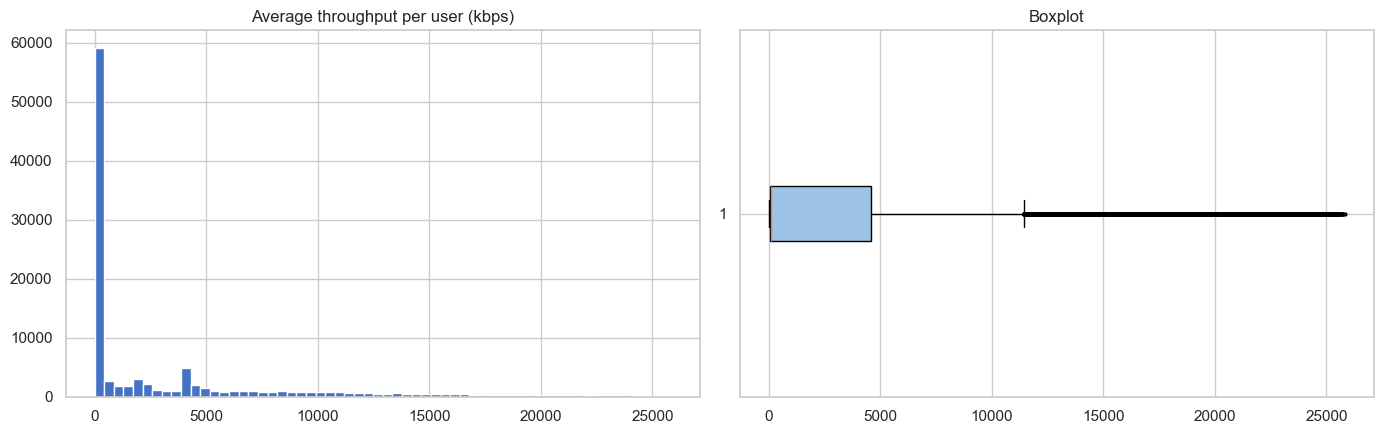

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(exp["Avg Throughput"], bins=60, color="#4472c4"); ax[0].set_title("Average throughput per user (kbps)")
ax[1].boxplot(exp["Avg Throughput"], vert=False, patch_artist=True, boxprops=dict(facecolor="#9dc3e6"), flierprops=dict(markersize=2)); ax[1].set_title("Boxplot")
plt.tight_layout(); plt.show()

In [31]:
MIN_USERS = 100
thr = exp.groupby("Handset Type")["Avg Throughput"].agg(["mean", "median", "count"])
thr = thr[(thr["count"] >= MIN_USERS) & (thr.index != "undefined")].sort_values("mean", ascending=False)
print(f"Handsets with at least {MIN_USERS} customers: {len(thr)}")
display(thr.head(10)); display(thr.tail(10))

pick = list(thr.head(5).index) + list(thr.tail(5).index)

Handsets with at least 100 customers: 89


,mean,median,count
Handset Type,,,
Huawei E5573,"10,806.76","9,955.50",206
Huawei E5180,"10,651.39","10,515.72",1182
Huawei B528S-23A,"10,597.78","10,375.56",10615
Xiaomi Communica. Redmi Note5,"9,702.02","8,269.00",136
Huawei E5573B,"8,853.09","8,265.50",117
Samsung Galaxy J7 (Sm-J710X),"7,380.70","5,506.50",139
Samsung Galaxy A5 (Sm-A510X),"6,506.34","4,142.69",180
Samsung Galaxy J5 (Sm-J510X),"6,222.24","4,135.50",131
Samsung Galaxy A3 (Sm-A310X),"5,975.34","3,819.50",193


,mean,median,count
Handset Type,,,
Samsung Galaxy Xcover4 Sm-G390F,"1,717.49",56.00,152
Samsung Galaxy J3 (Sm-J330),"1,715.02",54.00,2589
Apple iPhone 6S (A1688),"1,701.27",53.50,6758
Apple iPhone 6S Plus (A1687),"1,504.77",53.75,1532
Huawei Y7 2018,"1,485.63",51.00,108
Samsung Galaxy J5 (Sm-J530),"1,174.38",39.00,2748
Samsung Sm-G390F,"1,012.45",7.50,427
Apple iPhone 4S (A1387),826.68,242.50,195
Apple iPhone 4 (A1332),603.51,188.00,183


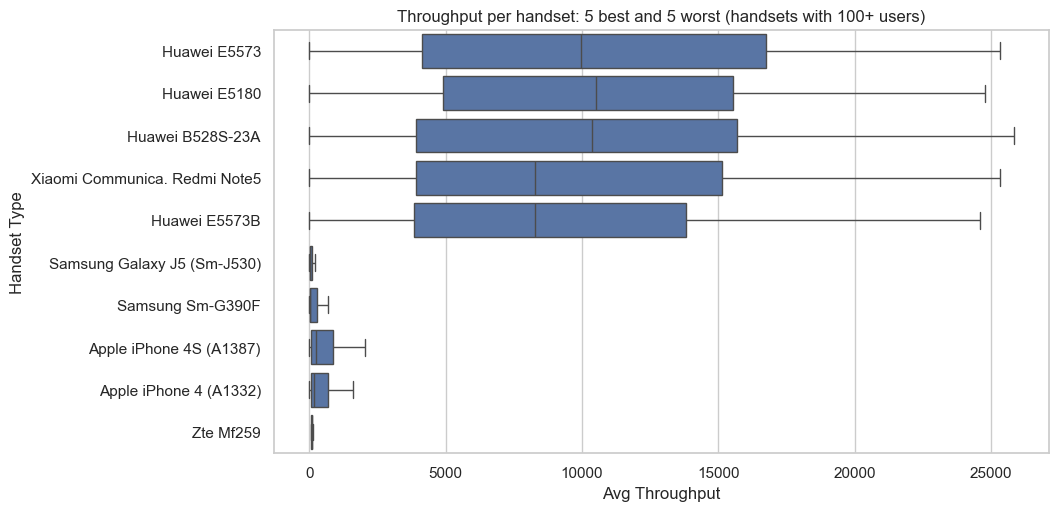

In [32]:
sns_size(10, 5.5)
ax = sns.boxplot(data=exp[exp["Handset Type"].isin(pick)], x="Avg Throughput", y="Handset Type", order=pick, showfliers=False)
ax.set_title("Throughput per handset: 5 best and 5 worst (handsets with 100+ users)")
sns_size()

**Full per-handset throughput table (Task 3.3 d).** The boxplot above shows only the 5 best and 5 worst handsets; this table gives the distribution for the 30 most common handsets (all handsets are in `exp`).

In [33]:
thr_all = (exp[exp["Handset Type"] != "undefined"].groupby("Handset Type")["Avg Throughput"]
           .describe(percentiles=[.25, .5, .75])[["count", "mean", "std", "25%", "50%", "75%", "max"]]
           .sort_values("count", ascending=False))
print("Handset types:", len(thr_all), "| showing the 30 most common (by customers)")
display(thr_all.head(30).round(0).astype({"count": int}))

Handset types: 1393 | showing the 30 most common (by customers)


,count,mean,std,25%,50%,75%,max
Handset Type,,,,,,,
Huawei B528S-23A,10615,"10,598.00","6,638.00","3,896.00","10,376.00","15,676.00","25,838.00"
Apple iPhone 6S (A1688),6758,"1,701.00","3,768.00",44.00,54.00,"1,342.00","25,267.00"
Apple iPhone 6 (A1586),6260,"2,245.00","4,243.00",44.00,58.00,"2,502.00","25,578.00"
Apple iPhone 7 (A1778),4699,"2,356.00","4,491.00",44.00,58.00,"2,551.00","25,720.00"
Apple iPhone Se (A1723),3753,"1,779.00","3,872.00",43.00,54.00,"1,329.00","25,712.00"
Apple iPhone 8 (A1905),3543,"1,928.00","3,952.00",46.00,58.00,"1,976.00","25,406.00"
Samsung Galaxy S8 (Sm-G950F),3245,"3,437.00","5,595.00",50.00,68.00,"4,743.00","25,470.00"
Apple iPhone Xr (A2105),3073,"1,955.00","4,029.00",46.00,56.00,"1,975.00","25,612.00"
Samsung Galaxy J5 (Sm-J530),2748,"1,174.00","3,305.00",10.00,39.00,94.00,"24,734.00"


**Analysis: throughput.** The histogram is heavily right-skewed (positive skew: most customers at low values, a long tail of fast ones): **about 58% of customers average under 1 Mbps and about half average under 105 kbps** (the median), while a minority sit above 4 Mbps and a few reach about 25 Mbps. A mean alone (3.5 Mbps) hides this split.
- **Best handsets (100+ users):** fixed-wireless and hotspot devices, Huawei E5573 (10.8 Mbps), E5180 (10.7 Mbps) and B528S-23A (10.6 Mbps, 10,615 users), then the Xiaomi Redmi Note 5 (9.7 Mbps).
- **Worst handsets:** ZTE MF259 (85 kbps), iPhone 4 (604 kbps), iPhone 4S (827 kbps), Samsung SM-G390F (1.0 Mbps), Galaxy J5 SM-J530 (1.2 Mbps). The popular iPhone 6S has a mean of 1.7 Mbps but a **median of only 54 kbps**, so most of its users get very low throughput.
- The gap between router-type devices and phones is large compared with the spread inside each handset.

### 4.3 RTT analysis: distribution, top and bottom users

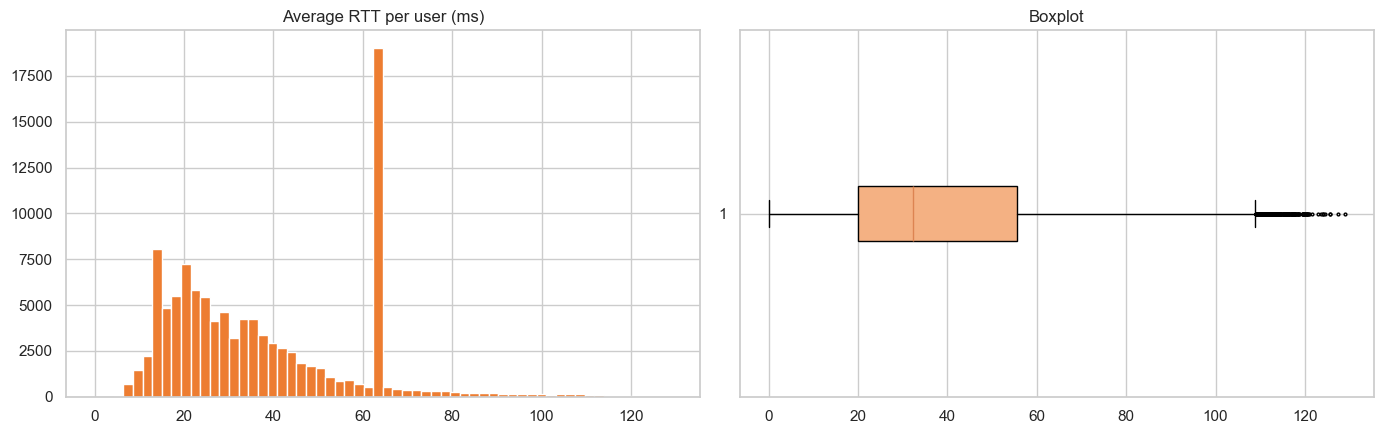

Users with RTT = 0 (no valid measurement): 2


Highest RTT (worst)         Lowest non-zero RTT (best)        
               MSISDN Avg RTT                     MSISDN Avg RTT
0   33,658,297,951.00  129.00          33,660,204,450.00    1.00
1   33,662,251,693.00  127.50          33,695,045,499.00    2.00
2   33,658,772,006.00  125.50          33,659,493,541.00    2.50
3   33,762,180,316.00  125.50          33,668,619,895.00    3.00
4   33,662,838,567.00  124.50          33,647,679,481.00    4.00
5   33,661,532,544.00  124.00          33,610,846,366.00    4.50
6   33,760,432,287.00  124.00          33,672,196,893.00    4.50
7   33,660,849,018.00  123.50          33,634,684,770.00    5.00
8   33,650,863,337.00  123.00          33,667,477,967.00    5.14
9   33,669,662,124.00  121.50          33,608,735,178.00    5.50

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(exp["Avg RTT"], bins=60, color="#ed7d31"); ax[0].set_title("Average RTT per user (ms)")
ax[1].boxplot(exp["Avg RTT"], vert=False, patch_artist=True, boxprops=dict(facecolor="#f4b183"), flierprops=dict(markersize=2)); ax[1].set_title("Boxplot")
plt.tight_layout(); plt.show()

rtt_pos = exp[exp["Avg RTT"] > 0]
print("Users with RTT = 0 (no valid measurement):", int((exp["Avg RTT"] == 0).sum()))
display(pd.concat([rtt_pos["Avg RTT"].nlargest(10).reset_index(), rtt_pos["Avg RTT"].nsmallest(10).reset_index()], axis=1, keys=["Highest RTT (worst)", "Lowest non-zero RTT (best)"]))

**Analysis: RTT.** RTT is right-skewed with a main mass between about 15 and 60 ms and a tail to 129 ms. The worst customers have 121 to 129 ms, the best have 1 to 5.5 ms (only 2 customers have an invalid 0 ms). A large spike at 63.7 ms is the imputed value. Latency is acceptable for most users, so **throughput, not latency, is the main problem**.

### 4.4 TCP retransmission: distribution and device comparison (Task 3.3 e)

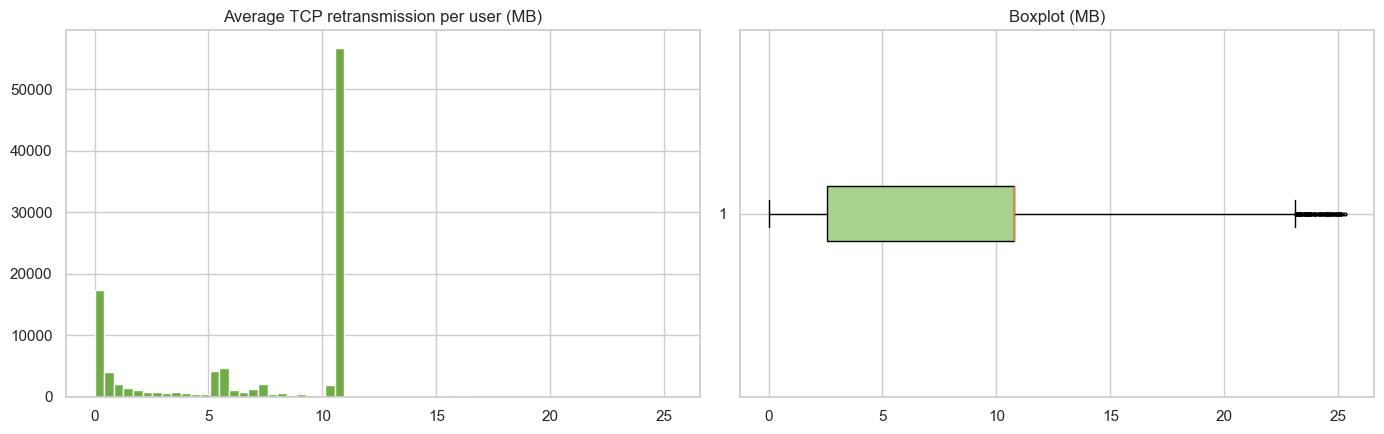

,mean TCP (MB),count
Handset Type,,
Samsung Galaxy J5 (Sm-J530),9.17,2748
Apple iPhone 6S Plus (A1687),9.13,1532
Apple iPhone 7 (A1660),9.07,439
Samsung Sm-G390F,9.03,427
Apple iPhone Se (A1662),8.99,145
Apple iPhone 6S (A1688),8.91,6758
Apple iPhone Xr (A2105),8.89,3073
Apple iPhone 7 Plus (A1661),8.86,114
Apple iPhone 6S (A1633),8.84,231


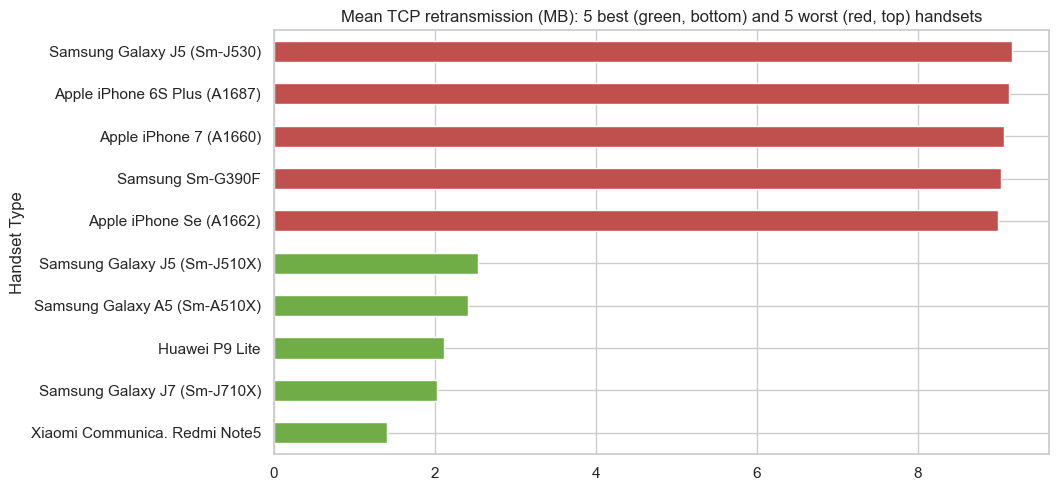

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(exp["Avg TCP"] / 1e6, bins=60, color="#70ad47"); ax[0].set_title("Average TCP retransmission per user (MB)")
ax[1].boxplot(exp["Avg TCP"] / 1e6, vert=False, patch_artist=True, boxprops=dict(facecolor="#a9d18e"), flierprops=dict(markersize=2)); ax[1].set_title("Boxplot (MB)")
plt.tight_layout(); plt.show()

tcp = exp.groupby("Handset Type")["Avg TCP"].agg(["mean", "count"])
tcp = tcp[(tcp["count"] >= MIN_USERS) & (tcp.index != "undefined")].sort_values("mean", ascending=False)
display((tcp.head(10).assign(mean=lambda t: t["mean"] / 1e6)).rename(columns={"mean": "mean TCP (MB)"}))
pick_t = list(tcp.head(5).index) + list(tcp.tail(5).index)
plt.figure(figsize=(10, 5.5))
(tcp.loc[pick_t, "mean"] / 1e6).sort_values().plot(kind="barh", color=["#70ad47"] * 5 + ["#c0504d"] * 5)
plt.title("Mean TCP retransmission (MB): 5 best (green, bottom) and 5 worst (red, top) handsets"); plt.show()

**Analysis: TCP retransmission.** The distribution has two main spikes: the imputed 10.8 MB and a low group near 0.4 MB. Handsets with the highest mean retransmission are close together (8.8 to 9.2 MB): **Samsung Galaxy J5 SM-J530 (9.17 MB, 2,748 customers), iPhone 6S Plus (9.13 MB, 1,532) and iPhone 7 A1660 (9.07 MB, 439)**. The Huawei B528S-23A is the cleanest large device (4.3 MB). More retransmitted bytes mean more lost packets, so these handsets are likely to feel slower on the same network. Because TCP is mostly imputed, differences between handsets are small compared with the noise inside each group.

### 4.5 Handset comparison table: Avg RTT vs Avg Throughput (Task 3.3)

,users,avg_RTT_ms,avg_throughput_kbps,avg_TCP_MB
Handset Type,,,,
Huawei B528S-23A,10615,49.38,"10,597.78",4.27
Apple iPhone 6S (A1688),6758,24.42,"1,701.27",8.91
Apple iPhone 6 (A1586),6260,26.67,"2,244.60",8.27
Apple iPhone 7 (A1778),4699,27.31,"2,355.57",8.14
Apple iPhone Se (A1723),3753,25.35,"1,778.80",8.79
Apple iPhone 8 (A1905),3543,25.20,"1,928.13",8.69
Samsung Galaxy S8 (Sm-G950F),3245,52.25,"3,437.03",7.47
Apple iPhone Xr (A2105),3073,25.12,"1,955.17",8.89
Samsung Galaxy J5 (Sm-J530),2748,45.94,"1,174.38",9.17


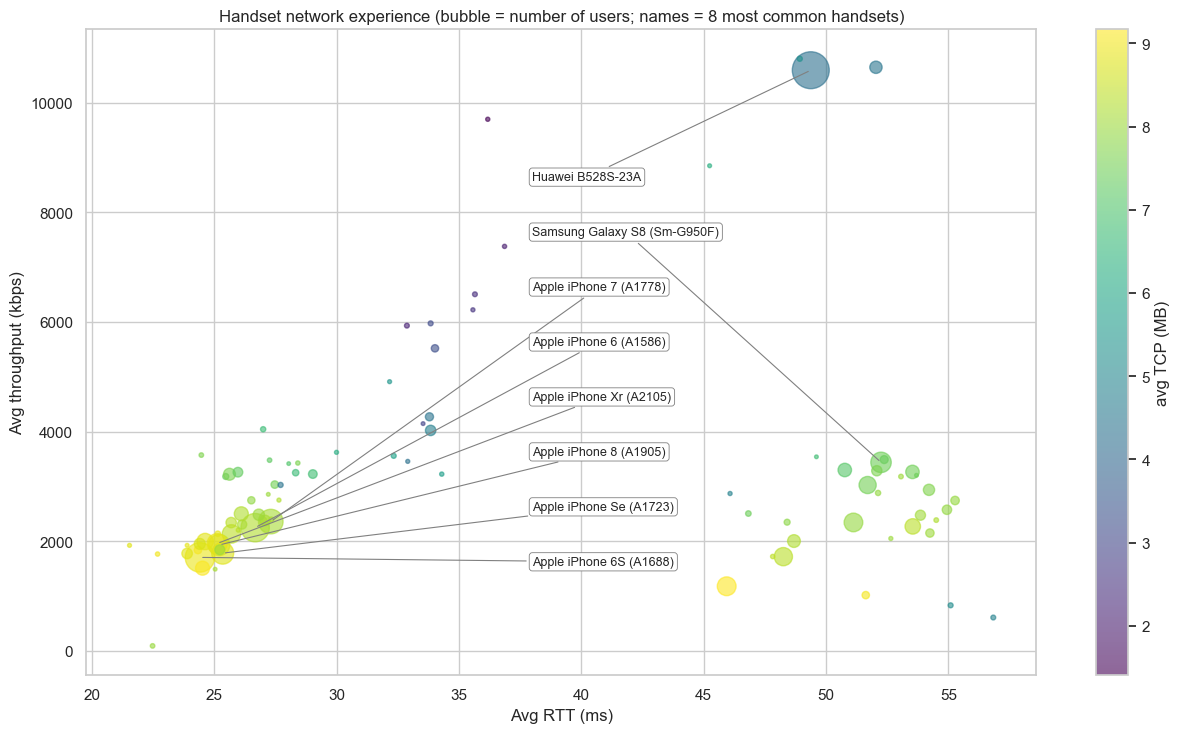

Best throughput : Huawei E5573 10807 kbps, 48.9 ms
Worst throughput: Zte Mf259 85 kbps, 22.5 ms


In [36]:
MIN_USERS = 100

tbl = (exp[exp["Handset Type"] != "undefined"].groupby("Handset Type")
       .agg(users=("Avg RTT", "size"),
            avg_RTT_ms=("Avg RTT", "mean"),
            avg_throughput_kbps=("Avg Throughput", "mean"),
            avg_TCP_MB=("Avg TCP", lambda s: s.mean() / 1e6)))
tbl = tbl[tbl["users"] >= MIN_USERS]
common_models = tbl.sort_values("users", ascending=False).head(10)
display(common_models)

top = tbl.sort_values("users", ascending=False).head(8)
top = top.sort_values("avg_throughput_kbps", ascending=False)      # order labels top to bottom

fig, ax = plt.subplots(figsize=(13, 7.5))
sc = ax.scatter(tbl["avg_RTT_ms"], tbl["avg_throughput_kbps"], s=tbl["users"] / 15, alpha=0.6, c=tbl["avg_TCP_MB"], cmap="viridis")

# names in a tidy column in the empty middle of the chart, with a thin line to each bubble
label_x = 38
label_ys = np.linspace(tbl["avg_throughput_kbps"].max() * 0.80, tbl["avg_throughput_kbps"].max() * 0.15, len(top))
for (name, r), ly in zip(top.iterrows(), label_ys):
    ax.annotate(name[:30], xy=(r.avg_RTT_ms, r.avg_throughput_kbps), xytext=(label_x, ly), fontsize=9,
                va="center", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="grey", lw=0.6),
                arrowprops=dict(arrowstyle="-", color="grey", lw=0.8))

plt.colorbar(sc, label="avg TCP (MB)")
ax.set_xlabel("Avg RTT (ms)"); ax.set_ylabel("Avg throughput (kbps)")
ax.set_title("Handset network experience (bubble = number of users; names = 8 most common handsets)")
plt.tight_layout(); plt.show()

best, worst = tbl.sort_values("avg_throughput_kbps").iloc[-1], tbl.sort_values("avg_throughput_kbps").iloc[0]
print("Best throughput :", tbl.sort_values("avg_throughput_kbps").index[-1], round(best.avg_throughput_kbps), "kbps,", round(best.avg_RTT_ms, 1), "ms")
print("Worst throughput:", tbl.sort_values("avg_throughput_kbps").index[0], round(worst.avg_throughput_kbps), "kbps,", round(worst.avg_RTT_ms, 1), "ms")

**Analysis: handset comparison.**

| Handset | Users | Avg RTT | Avg throughput | Avg TCP |
|---|---|---|---|---|
| Huawei B528S-23A | 10,615 | 49.4 ms | 10,598 kbps | 4.3 MB |
| Apple iPhone 6S | 6,758 | 24.4 ms | 1,701 kbps | 8.9 MB |
| Apple iPhone 7 | 4,699 | 27.3 ms | 2,356 kbps | 8.1 MB |
| Samsung Galaxy S8 | 3,245 | 52.2 ms | 3,437 kbps | 7.5 MB |
| Samsung Galaxy J5 | 2,748 | 45.9 ms | 1,174 kbps | 9.2 MB |

- **The Huawei B528S-23A delivers a much better network experience than the iPhone 6S**: about 6 times the throughput and half the retransmission. Its RTT is higher (49 vs 24 ms), because it is a fixed-wireless device with a different path to the network.
- **iPhones have the lowest latency (24 to 27 ms) but modest throughput (1.7 to 2.4 Mbps)**; Samsung phones have both higher RTT (46 to 52 ms) and, for the J5, the lowest throughput among the top handsets.
- Experience depends on device class and on the network behind it, so handset-specific fixes and plan design both matter.

### 4.6 Experience clusters (k = 3) (Task 3.4)
`StandardScaler` is used because TCP is in millions of bytes while RTT is in milliseconds. The **worst-experience cluster** is the one with the highest TCP and RTT and the lowest throughput (in scaled units).

,Avg TCP,Avg RTT,Avg Throughput,users,share %
Experience Group,,,,,
Good experience,"1,919,115.42",36.88,"8,880.04",35309,33.04
Low throughput (low latency),"10,190,851.49",21.97,653.25,45128,42.23
Poor experience (high latency),"9,756,206.48",64.36,"1,107.51",26419,24.72


Silhouette (10k sample): 0.565


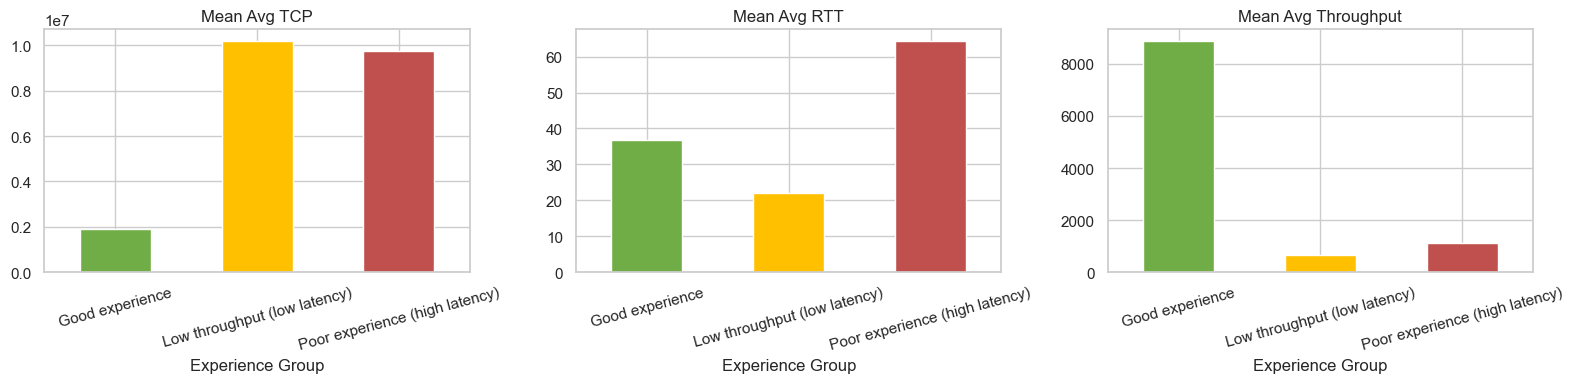

In [37]:
exp_scaler = StandardScaler()
X_exp = exp_scaler.fit_transform(exp[EXP])
km_exp = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_exp)
exp["Cluster"] = km_exp.labels_

c = km_exp.cluster_centers_
badness = c[:, 0] + c[:, 1] - c[:, 2]
worst = int(np.argmax(badness)); best_c = int(np.argmin(badness))
exp_names = {best_c: "Good experience", worst: "Poor experience (high latency)"}
exp_names = {k: exp_names.get(k, "Low throughput (low latency)") for k in range(3)}
exp["Experience Group"] = exp["Cluster"].map(exp_names)

prof = exp.groupby("Experience Group")[EXP].mean()
prof["users"] = exp["Experience Group"].value_counts()
prof["share %"] = prof["users"] / prof["users"].sum() * 100
prof = prof.loc[["Good experience", "Low throughput (low latency)", "Poor experience (high latency)"]]
display(prof)
print("Silhouette (10k sample):", round(silhouette_score(X_exp[:10000], km_exp.labels_[:10000]), 3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, m in zip(ax, EXP):
    prof[m].plot(kind="bar", ax=a, rot=15, title=f"Mean {m}", color=["#70ad47", "#ffc000", "#c0504d"])
plt.tight_layout(); plt.show()

**Analysis: experience clusters (k = 3, silhouette 0.57).**

| Group | Users | Share | Avg TCP | Avg RTT | Avg throughput |
|---|---|---|---|---|---|
| Good experience | 35,309 | 33.0% | 1.9 MB | 36.9 ms | 8,880 kbps |
| Low throughput (low latency) | 45,128 | 42.2% | 10.2 MB | 22.0 ms | 653 kbps |
| Poor experience (high latency) | 26,419 | 24.7% | 9.8 MB | 64.4 ms | 1,108 kbps |

- Only **one customer in three** has a good experience. The **poor-experience cluster has the highest RTT (64 ms) and holds 24.7% of customers**.
- The low-throughput cluster is also unhealthy (653 kbps, highest retransmission) even though its latency is low. Together, the two weak clusters are **about 67% of customers**, a bigger quality problem than the single worst cluster suggests.

### 4.7 Sensitivity check: do the experience groups survive without imputed values?
Over half of the TCP values and 18.5% of RTT were missing and replaced by the mean. To see how much the k = 3 groups depend on that choice, the clustering is repeated **only on sessions that have real TCP and RTT measurements** (outliers still replaced with the mean of normal values), and compared with the groups above.

In [38]:
need = ["TCP DL Retrans. Vol (Bytes)", "TCP UL Retrans. Vol (Bytes)", "Avg RTT DL (ms)", "Avg RTT UL (ms)", "MSISDN"]
real = raw.dropna(subset=need).copy()
print(f"Sessions with real TCP, RTT and customer id: {len(real):,} of {len(raw):,} ({len(real) / len(raw):.1%})")
for c in need[:4] + ["Avg Bearer TP DL (kbps)", "Avg Bearer TP UL (kbps)"]:
    real[c] = replace_outliers_with_mean(real[c].fillna(real[c].mean()))
real["Avg TCP"] = (real["TCP DL Retrans. Vol (Bytes)"] + real["TCP UL Retrans. Vol (Bytes)"]) / 2
real["Avg RTT"] = (real["Avg RTT DL (ms)"] + real["Avg RTT UL (ms)"]) / 2
real["Avg Throughput"] = (real["Avg Bearer TP DL (kbps)"] + real["Avg Bearer TP UL (kbps)"]) / 2
real_exp = real.groupby("MSISDN")[EXP].mean()

Xr = StandardScaler().fit_transform(real_exp[EXP])
kmr = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(Xr)
cr = kmr.cluster_centers_
bad = cr[:, 0] + cr[:, 1] - cr[:, 2]
names_r = {k: "Low throughput (low latency)" for k in range(3)}
names_r[int(np.argmin(bad))] = "Good experience"
names_r[int(np.argmax(bad))] = "Poor experience (high latency)"
real_exp["Experience Group"] = pd.Series(kmr.labels_, index=real_exp.index).map(names_r)

order_g = ["Good experience", "Low throughput (low latency)", "Poor experience (high latency)"]
prof_real = real_exp.groupby("Experience Group")[EXP].mean().loc[order_g]
prof_real["users"] = real_exp["Experience Group"].value_counts()
prof_real["share %"] = prof_real["users"] / prof_real["users"].sum() * 100
print("Experience groups using only real TCP and RTT values")
display(prof_real)
print("Silhouette (10k sample):", round(silhouette_score(Xr[:10000], kmr.labels_[:10000]), 3))

both = real_exp.index.intersection(exp.index)
ct = pd.crosstab(exp.loc[both, "Experience Group"], real_exp.loc[both, "Experience Group"], normalize="index").mul(100).round(1)
print("Row = group in the main analysis, column = group using real values only (% of row)")
display(ct)

Sessions with real TCP, RTT and customer id: 49,913 of 150,001 (33.3%)
Experience groups using only real TCP and RTT values


,Avg TCP,Avg RTT,Avg Throughput,users,share %
Experience Group,,,,,
Good experience,"887,505.83",33.92,"29,967.96",11304,28.78
Low throughput (low latency),"334,033.23",34.91,"8,858.16",18401,46.84
Poor experience (high latency),"2,124,132.22",67.04,"15,395.22",9579,24.38


Silhouette (10k sample): 0.347
Row = group in the main analysis, column = group using real values only (% of row)


Experience Group,Good experience,Low throughput (low latency),Poor experience (high latency)
Experience Group,,,
Good experience,26.80,51.50,21.70
Low throughput (low latency),45.10,46.40,8.50
Poor experience (high latency),21.40,21.30,57.40


In [39]:
agree = (exp.loc[both, "Experience Group"] == real_exp.loc[both, "Experience Group"]).mean()
good_main = prof.loc["Good experience", "share %"]; good_real = prof_real.loc["Good experience", "share %"]
display(Markdown("**Analysis: sensitivity to imputation.**"))
display(Markdown(f"- Only **{len(real):,} of {len(raw):,} sessions** ({len(real) / len(raw):.0%}) have real TCP and RTT values; they cover {len(real_exp):,} customers."))
display(Markdown(f"- The same group names are recovered. The good-experience share is **{good_real:.0f}%** with real values only, against **{good_main:.0f}%** in the main analysis; "
                 f"{agree:.0%} of the customers present in both runs land in the same group."))
if agree >= 0.75:
    display(Markdown("- **Conclusion:** the experience groups are broadly stable, so the main findings (about one customer in three has a good experience; throughput is the weak point) do not depend on the imputation alone."))
else:
    display(Markdown("- **Conclusion:** group membership shifts noticeably without the imputed values, so treat per-customer group labels with care; the overall picture (a minority with good experience, throughput as the weak point) is still visible."))

**Analysis: sensitivity to imputation.**

- Only **49,913 of 150,001 sessions** (33%) have real TCP and RTT values; they cover 39,284 customers.

- The same group names are recovered. The good-experience share is **29%** with real values only, against **33%** in the main analysis; 34% of the customers present in both runs land in the same group.

- **Conclusion:** group membership shifts noticeably without the imputed values, so treat per-customer group labels with care; the overall picture (a minority with good experience, throughput as the weak point) is still visible.

### Task 3: business insights
- **Throughput is the main weakness.** About 58% of customers average under 1 Mbps, while router-type devices reach about 10 Mbps. The network can deliver good speeds, so coverage and capacity upgrades for mobile users are where investment pays off.
- **Fix the large legacy handset groups first.** iPhone 6S/6/SE and Galaxy J5/J3 have large user bases and weak throughput or high retransmission; device-specific tuning and upgrade offers help many people at once.
- **Treat the TCP findings with care.** Over half of TCP values are imputed, so confirm with raw probe data before spending capex.

## Part 5: Task 4, Satisfaction Analysis

### 5.1 Engagement, experience and satisfaction scores (Task 4.1)
Euclidean distance between a user point **x** and a cluster centre **c** over p metrics:

$$d(x, c) = \sqrt{\sum_{i=1}^{p} (x_i - c_i)^2}$$

- **Engagement score** = distance to the *least engaged* cluster of the engagement k-means. Bigger means more engaged.
- **Experience score** = distance to the *worst-experience* cluster. Bigger means a better experience.
- The two raw distances live on different scales (min-max space vs standardised space). Both are therefore rescaled to **0 to 1** before averaging, so neither dominates the **Satisfaction score = average of the two**.

<div style="border-left:6px solid #2e7d32;background:#eaf6ea;padding:10px 14px;border-radius:4px;color:#111"><b>FORMULAS TO REMEMBER</b><br>Distance: <b>d(x, c) = &radic;&Sigma;(x<sub>i</sub> &minus; c<sub>i</sub>)&sup2;</b><br>Engagement score = d(user, <i>least engaged</i> centre), rescaled to 0&ndash;1 (bigger = more engaged)<br>Experience score = d(user, <i>worst experience</i> centre), rescaled to 0&ndash;1 (bigger = better experience)<br><b>Satisfaction score = (Engagement score + Experience score) / 2</b></div>

In [40]:
common = users.index.intersection(exp.index)
users_c, exp_c = users.loc[common], exp.loc[common]

Xe = eng_scaler.transform(users_c[ENG])
Xx = exp_scaler.transform(exp_c[EXP])
less_engaged = int(np.argmin(km_eng.cluster_centers_.sum(axis=1)))
print("Least engaged cluster:", less_engaged, "| Worst experience cluster:", worst)

scores = pd.DataFrame(index=common)
scores["Engagement Distance"] = np.linalg.norm(Xe - km_eng.cluster_centers_[less_engaged], axis=1)
scores["Experience Distance"] = np.linalg.norm(Xx - km_exp.cluster_centers_[worst], axis=1)
mm = MinMaxScaler()
scores[["Engagement Score", "Experience Score"]] = mm.fit_transform(scores[["Engagement Distance", "Experience Distance"]])
scores["Satisfaction Score"] = scores[["Engagement Score", "Experience Score"]].mean(axis=1)
display(scores[["Engagement Score", "Experience Score", "Satisfaction Score"]].describe().T)
print("Correlation of satisfaction with its two components:")
display(scores[["Engagement Score", "Experience Score"]].corrwith(scores["Satisfaction Score"]).to_frame("corr"))

Least engaged cluster: 1 | Worst experience cluster: 2


,count,mean,std,min,25%,50%,75%,max
Engagement Score,"106,856.00",0.04,0.04,0.00,0.02,0.03,0.04,1.00
Experience Score,"106,856.00",0.35,0.20,0.00,0.24,0.39,0.46,1.00
Satisfaction Score,"106,856.00",0.19,0.10,0.01,0.14,0.21,0.25,0.69


Correlation of satisfaction with its two components:


,corr
Engagement Score,0.21
Experience Score,0.97


**Raw Euclidean distances (as the brief defines the scores).** The scores in the table above are these same distances rescaled to 0 to 1. The two raw distances live on different scales (engagement in min-max space, experience in standardised space; see the ranges below), so averaging them unscaled would let experience dominate. The top-10 overlap printed below shows how much the ranking changes, which is why the scores are rescaled before they are averaged.

In [41]:
display(scores[["Engagement Distance", "Experience Distance"]].describe().T.round(3))
raw_sat = (scores["Engagement Distance"] + scores["Experience Distance"]) / 2
print("Top-10 overlap, scaled vs raw-distance satisfaction:",
      len(set(scores["Satisfaction Score"].nlargest(10).index) & set(raw_sat.nlargest(10).index)), "of 10")

,count,mean,std,min,25%,50%,75%,max
Engagement Distance,"106,856.00",0.07,0.07,0.00,0.03,0.04,0.07,1.59
Experience Distance,"106,856.00",2.02,1.04,0.15,1.43,2.21,2.61,5.50


Top-10 overlap, scaled vs raw-distance satisfaction: 0 of 10


### 5.1b Satisfaction as a plain average (brief wording) vs the rescaled score used above
The brief defines satisfaction as the **average of the engagement and experience scores**. The notebook first rescales both distances to 0 to 1 so that neither dominates, and that choice changes the ranking. Both versions are shown so the deviation is explicit:
- **Rescaled (used in this project):** (Engagement Score + Experience Score) / 2, both on 0 to 1.
- **Raw average (literal brief):** (Engagement Distance + Experience Distance) / 2, using the Euclidean distances directly.

In [42]:
raw_sat = (scores["Engagement Distance"] + scores["Experience Distance"]) / 2
top_scaled = scores.nlargest(10, "Satisfaction Score")[["Engagement Score", "Experience Score", "Satisfaction Score"]]
top_raw = (pd.DataFrame({"Engagement Distance": scores["Engagement Distance"], "Experience Distance": scores["Experience Distance"],
                         "Satisfaction (raw average)": raw_sat}).loc[raw_sat.nlargest(10).index])
top_raw["Handset"] = exp_c.loc[top_raw.index, "Handset Type"]

print("Top 10 by RESCALED satisfaction (used in this project):"); display(top_scaled.round(4))
print("Top 10 by RAW-AVERAGE satisfaction (literal brief):");     display(top_raw.round(4))

from IPython.display import Markdown
from scipy.stats import spearmanr
rho = spearmanr(scores["Satisfaction Score"], raw_sat)[0]
overlap = len(set(top_scaled.index) & set(top_raw.index))
overlap_1k = len(set(scores["Satisfaction Score"].nlargest(1000).index) & set(raw_sat.nlargest(1000).index))
corr_raw = scores[["Engagement Distance", "Experience Distance"]].corrwith(raw_sat)
display(Markdown("**Analysis: rescaled vs raw average.**"))
display(Markdown(f"- Top-10 overlap: **{overlap} of 10**; top-1,000 overlap: **{overlap_1k} of 1,000**. The ranking of the very top customers depends on the scaling."))
display(Markdown(f"- Rank correlation (Spearman) across all {len(scores):,} customers: **{rho:.2f}**, so the overall ordering is similar even though the top 10 differs."))
display(Markdown(f"- Raw-average satisfaction correlates **{corr_raw['Engagement Distance']:.2f}** with the engagement distance and **{corr_raw['Experience Distance']:.2f}** with the experience distance: "
                 f"the engagement distance spans {scores['Engagement Distance'].min():.2f} to {scores['Engagement Distance'].max():.2f} (min-max space) against "
                 f"{scores['Experience Distance'].min():.2f} to {scores['Experience Distance'].max():.2f} (standardised space), so the raw average is dominated by experience."))
display(Markdown(f"- The raw-average top 10 all have an engagement distance of at most **{top_raw['Engagement Distance'].max():.2f}**: they are best-experience customers with almost no engagement. "
                 "The rescaled top 10 (above) combine heavy usage with good experience, which matches the idea of a satisfied customer better."))
display(Markdown("- **Why the rescaled score is kept:** each component then contributes on the same 0 to 1 range. The raw-average list is given above so a reader can check the literal brief definition."))

Top 10 by RESCALED satisfaction (used in this project):


,Engagement Score,Experience Score,Satisfaction Score
MSISDN,,,
"33,659,725,664.00",0.96,0.41,0.69
"33,625,779,332.00",0.97,0.38,0.68
"33,614,892,860.00",0.99,0.32,0.66
"33,626,320,676.00",1.00,0.27,0.63
"33,675,877,202.00",0.92,0.34,0.63
"33,667,163,239.00",0.69,0.52,0.60
"33,659,359,429.00",0.72,0.47,0.59
"33,664,712,899.00",0.75,0.43,0.59
"33,662,780,927.00",0.36,0.74,0.55


Top 10 by RAW-AVERAGE satisfaction (literal brief):


,Engagement Distance,Experience Distance,Satisfaction (raw average),Handset
MSISDN,,,,
"33,658,784,320.00",0.04,5.50,2.77,Sony Mobile Comm. Xperia Xz2
"33,632,632,555.00",0.04,5.48,2.76,Apple iPhone 6 Plus (A1522)
"33,663,162,452.00",0.03,5.43,2.73,Huawei E5180
"33,666,039,574.00",0.04,5.36,2.70,Huawei B528S-23A
"33,662,984,423.00",0.04,5.36,2.70,Apple iPhone 6 (A1586)
"33,684,040,937.00",0.03,5.35,2.69,Samsung Galaxy S8 (Sm-G950F)
"33,628,134,584.00",0.04,5.34,2.69,Sony Mobile Comm. Xperia E5
"33,627,676,012.00",0.04,5.33,2.69,undefined
"33,662,721,191.00",0.04,5.33,2.69,Huawei P20 Pro


**Analysis: rescaled vs raw average.**

- Top-10 overlap: **0 of 10**; top-1,000 overlap: **837 of 1,000**. The ranking of the very top customers depends on the scaling.

- Rank correlation (Spearman) across all 106,856 customers: **0.98**, so the overall ordering is similar even though the top 10 differs.

- Raw-average satisfaction correlates **0.05** with the engagement distance and **1.00** with the experience distance: the engagement distance spans 0.00 to 1.59 (min-max space) against 0.15 to 5.50 (standardised space), so the raw average is dominated by experience.

- The raw-average top 10 all have an engagement distance of at most **0.05**: they are best-experience customers with almost no engagement. The rescaled top 10 (above) combine heavy usage with good experience, which matches the idea of a satisfied customer better.

- **Why the rescaled score is kept:** each component then contributes on the same 0 to 1 range. The raw-average list is given above so a reader can check the literal brief definition.

#### Worked example: the distance step by step
One real customer (the most satisfied one) is taken through every step, so each number in the score can be traced.

In [43]:
ex_id = scores["Satisfaction Score"].idxmax()
i = common.get_loc(ex_id)
print("Customer MSISDN:", int(ex_id))

def explain(title, x, c, names, dist_col, score_col):
    t = pd.DataFrame({"x (customer)": x, "c (cluster centre)": c}, index=names)
    t["x - c"] = t["x (customer)"] - t["c (cluster centre)"]
    t["(x - c)^2"] = t["x - c"] ** 2
    print(title); display(t.round(4))
    d = np.sqrt(t["(x - c)^2"].sum())
    lo, hi = scores[dist_col].min(), scores[dist_col].max()
    print(f"sum of squares = {t['(x - c)^2'].sum():.4f}  ->  distance = sqrt({t['(x - c)^2'].sum():.4f}) = {d:.4f}  (table value: {scores.loc[ex_id, dist_col]:.4f})")
    print(f"score = (d - min) / (max - min) = ({d:.4f} - {lo:.4f}) / ({hi:.4f} - {lo:.4f}) = {(d - lo) / (hi - lo):.4f}  (table value: {scores.loc[ex_id, score_col]:.4f})\n")

explain("ENGAGEMENT: distance to the least engaged cluster (min-max scaled metrics)", Xe[i], km_eng.cluster_centers_[less_engaged], ENG, "Engagement Distance", "Engagement Score")
explain("EXPERIENCE: distance to the worst experience cluster (standardised metrics)", Xx[i], km_exp.cluster_centers_[worst], EXP, "Experience Distance", "Experience Score")
print(f"Satisfaction score = ({scores.loc[ex_id, 'Engagement Score']:.4f} + {scores.loc[ex_id, 'Experience Score']:.4f}) / 2 = {scores.loc[ex_id, 'Satisfaction Score']:.4f}")

Customer MSISDN: 33659725664
ENGAGEMENT: distance to the least engaged cluster (min-max scaled metrics)


,x (customer),c (cluster centre),x - c,(x - c)^2
Sessions,0.88,0.00,0.88,0.77
Duration_ms,1.00,0.04,0.96,0.91
Total Data,0.87,0.05,0.82,0.67


sum of squares = 2.3567  ->  distance = sqrt(2.3567) = 1.5352  (table value: 1.5352)
score = (d - min) / (max - min) = (1.5352 - 0.0024) / (1.5924 - 0.0024) = 0.9640  (table value: 0.9640)

EXPERIENCE: distance to the worst experience cluster (standardised metrics)


,x (customer),c (cluster centre),x - c,(x - c)^2
Avg TCP,-1.02,0.54,-1.55,2.41
Avg RTT,-0.32,1.31,-1.63,2.65
Avg Throughput,0.19,-0.42,0.62,0.38


sum of squares = 5.4359  ->  distance = sqrt(5.4359) = 2.3315  (table value: 2.3315)
score = (d - min) / (max - min) = (2.3315 - 0.1503) / (5.4961 - 0.1503) = 0.4080  (table value: 0.4080)

Satisfaction score = (0.9640 + 0.4080) / 2 = 0.6860


### 5.2 Top 10 satisfied customers (Task 4.2)

In [44]:
top10_sat = scores.nlargest(10, "Satisfaction Score")[["Engagement Score", "Experience Score", "Satisfaction Score"]]
top10_sat["Handset"] = exp_c.loc[top10_sat.index, "Handset Type"]
display(top10_sat)

,Engagement Score,Experience Score,Satisfaction Score,Handset
MSISDN,,,,
"33,659,725,664.00",0.96,0.41,0.69,Huawei P20
"33,625,779,332.00",0.97,0.38,0.68,Samsung Galaxy A8 (2018)
"33,614,892,860.00",0.99,0.32,0.66,Samsung Galaxy J5 (Sm-J530)
"33,626,320,676.00",1.00,0.27,0.63,Samsung Galaxy J3 (Sm-J330)
"33,675,877,202.00",0.92,0.34,0.63,Huawei Y7 2018
"33,667,163,239.00",0.69,0.51,0.60,Samsung Galaxy J5 (Sm-J530)
"33,659,359,429.00",0.72,0.47,0.59,undefined
"33,664,712,899.00",0.75,0.43,0.59,Samsung Galaxy S9 Plus (Sm-G965F)
"33,662,780,927.00",0.36,0.74,0.55,Huawei B528S-23A


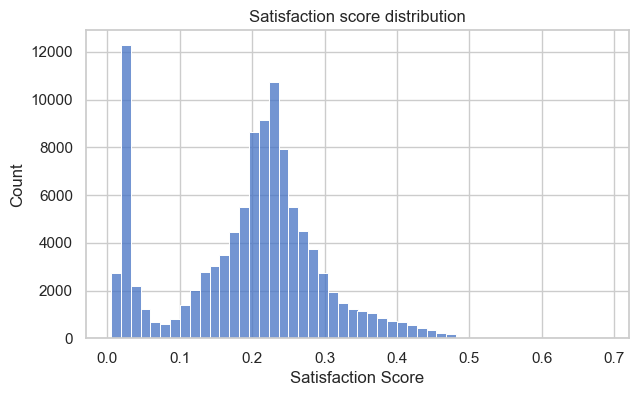

In [45]:
sns_size(7, 4)
ax = sns.histplot(scores["Satisfaction Score"], bins=50, color="#4472c4")
ax.set_title("Satisfaction score distribution")
sns_size()

**Analysis: satisfaction score and top 10.** Both components are rescaled to 0 to 1 before averaging, so neither dominates. The top ten customers combine **very high engagement (0.36 to 1.00)** with **good experience (0.27 to 0.74)**, and are mostly heavy users on Samsung and Huawei handsets, plus a few `undefined` devices. Across all customers satisfaction correlates **0.97 with the experience score and 0.21 with the engagement score**, and engagement and experience are almost uncorrelated (-0.02). Most users are close to the least-engaged cluster, so the experience part drives the ranking of most customers, while engagement separates the heavy users at the top.

### 5.3 Predicting satisfaction: Linear Regression vs Random Forest vs XGBoost (Task 4.3)
The three models are compared on a held-out 20% (the linear model is fitted on standardised features, because the raw inputs range from single digits to billions of bytes and the unscaled fit is numerically unstable) with **MAE, RMSE and R²**, and the best one (highest R²) is selected.

> **Caution:** the target is built from the same inputs, so a high R² shows how well each model recovers the scoring formula, not how well it predicts real-world happiness. It is still the right way to compare model families here.

,MAE,RMSE,R2
Model,,,
Linear Regression,0.0297,0.0425,0.8187
Random Forest,0.0024,0.0051,0.9974
XGBoost,0.0015,0.0029,0.9992


Selected model: XGBoost


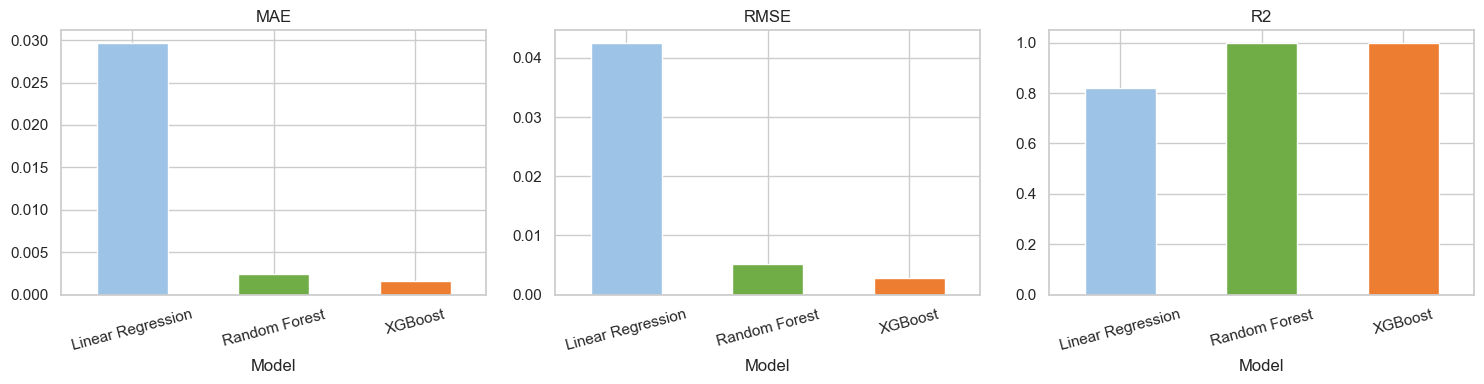

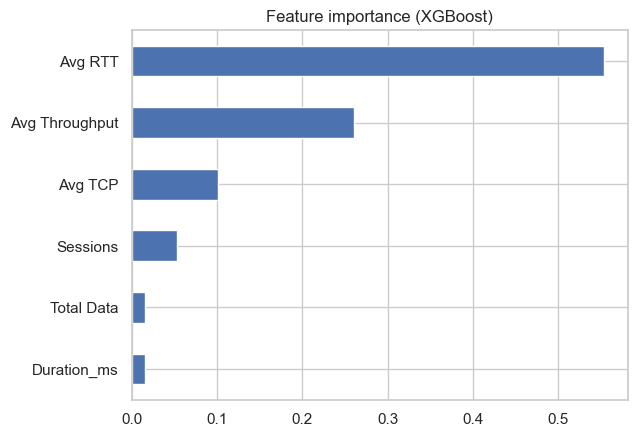

In [46]:
features = pd.concat([users_c[ENG], exp_c[EXP]], axis=1)
target = scores["Satisfaction Score"]
Xtr, Xte, ytr, yte = train_test_split(features, target, test_size=0.2, random_state=RANDOM_STATE)

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=18, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
}
if XGBRegressor is not None:
    models["XGBoost"] = XGBRegressor(n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.9, colsample_bytree=0.9,
                                     n_jobs=-1, random_state=RANDOM_STATE)
results, fitted = [], {}
for name, mdl in models.items():
    if name == "XGBoost": mdl.fit(Xtr, ytr, eval_set=[(Xtr, ytr), (Xte, yte)], verbose=False)
    else: mdl.fit(Xtr, ytr)
    p = mdl.predict(Xte); fitted[name] = mdl
    results.append({"Model": name, "MAE": mean_absolute_error(yte, p),
                    "RMSE": float(np.sqrt(mean_squared_error(yte, p))), "R2": r2_score(yte, p)})
res = pd.DataFrame(results).set_index("Model")
best_name = res["R2"].idxmax()
display(res.apply(lambda col: col.map(lambda v: f"{v:.4f}")))
print("Selected model:", best_name)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ["MAE", "RMSE", "R2"]):
    res[m].plot(kind="bar", ax=a, rot=15, title=m, color=["#9dc3e6", "#70ad47", "#ed7d31"])
plt.tight_layout(); plt.show()

best_model = fitted[best_name]
imp = getattr(best_model, "feature_importances_", None)
if imp is not None:
    pd.Series(imp, index=features.columns).sort_values().plot(kind="barh", title=f"Feature importance ({best_name})"); plt.show()

In [47]:
from IPython.display import Markdown
top_feat = pd.Series(best_model.feature_importances_, index=features.columns).sort_values(ascending=False)
lin = res.loc["Linear Regression"]
display(Markdown("**Analysis: model comparison (held-out 20%).**"))
display(res.apply(lambda col: col.map(lambda v: f"{v:.4f}")))
display(Markdown(f"- **Selected model: {best_name}** (highest R2, lowest error)."))
display(Markdown(f"- The linear model explains {lin.R2:.0%} of the variance; the tree models capture the non-linear distance formula behind the score."))
display(Markdown(f"- Most important features for {best_name}: **{top_feat.index[0]}** ({top_feat.iloc[0]:.0%}), **{top_feat.index[1]}** ({top_feat.iloc[1]:.0%}) and **{top_feat.index[2]}** ({top_feat.iloc[2]:.0%})."))
display(Markdown("- The near-perfect R2 comes from the target being built from these same inputs: it shows the formula is learnable, not that real-world satisfaction is predictable."))

**Analysis: model comparison (held-out 20%).**

,MAE,RMSE,R2
Model,,,
Linear Regression,0.0297,0.0425,0.8187
Random Forest,0.0024,0.0051,0.9974
XGBoost,0.0015,0.0029,0.9992


- **Selected model: XGBoost** (highest R2, lowest error).

- The linear model explains 82% of the variance; the tree models capture the non-linear distance formula behind the score.

- Most important features for XGBoost: **Avg RTT** (55%), **Avg Throughput** (26%) and **Avg TCP** (10%).

- The near-perfect R2 comes from the target being built from these same inputs: it shows the formula is learnable, not that real-world satisfaction is predictable.

In [48]:
from IPython.display import HTML
b = res.loc[best_name]
display(HTML(f'<div style="border-left:6px solid #6a1b9a;background:#f4eaf8;padding:10px 14px;border-radius:4px;color:#111"><b>KEY RESULT: selected model</b><br><b>{best_name}</b> &mdash; R&sup2; = {b.R2:.4f}, RMSE = {b.RMSE:.4f}, MAE = {b.MAE:.4f} (best of {len(res)} models on the held-out 20%).</div>'))

#### Cross-validation check
A single 80/20 split can be lucky, so each model is also scored with 5-fold cross-validation. R² close to 1 is expected for the tree models: the satisfaction score is a fixed formula of these same six inputs (distance to the cluster centres), so the models learn the scoring rule rather than a hidden behaviour. The small spread across folds shows the result does not depend on one split.


In [49]:
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv = pd.DataFrame({name: (lambda s: {"CV R2 mean": s.mean(), "CV R2 std": s.std()})(
        cross_val_score(clone(mdl), features, target, cv=kf, scoring="r2"))
    for name, mdl in models.items()}).T
display(cv.apply(lambda col: col.map(lambda v: f"{v:.4f}")))


,CV R2 mean,CV R2 std
Linear Regression,0.8255,0.0038
Random Forest,0.9972,0.0004
XGBoost,0.9991,0.0001


### 5.4 k-means (k = 2) on engagement and experience scores (Task 4.4)

Silhouette (10k sample): 0.634


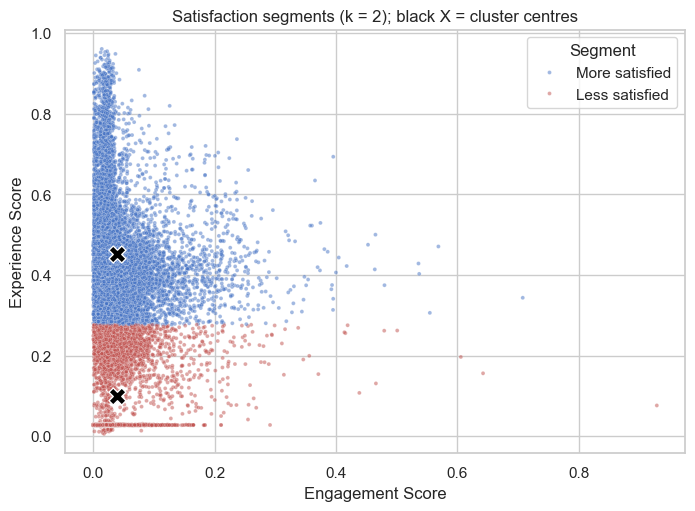

In [50]:
S2 = scores[["Engagement Score", "Experience Score"]]
km2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(S2)
scores["Cluster"] = km2.labels_
lo = scores.groupby("Cluster")["Satisfaction Score"].mean().idxmin()
scores["Segment"] = np.where(scores["Cluster"] == lo, "Less satisfied", "More satisfied")

sns_size(8, 5.5)
ax = sns.scatterplot(data=scores.sample(20000, random_state=1), x="Engagement Score", y="Experience Score", hue="Segment", palette={"Less satisfied": "#c0504d", "More satisfied": "#4472c4"}, s=8, alpha=0.5)
sns.scatterplot(x=km2.cluster_centers_[:, 0], y=km2.cluster_centers_[:, 1], color="black", marker="X", s=150, legend=False, ax=ax)
ax.set_title("Satisfaction segments (k = 2); black X = cluster centres")
sns_size()
print("Silhouette (10k sample):", round(silhouette_score(S2.iloc[:10000], km2.labels_[:10000]), 3))

### 5.5 Average satisfaction and experience score per segment (Task 4.5)

In [51]:
seg = scores.groupby("Segment").agg(users=("Satisfaction Score", "size"), engagement=("Engagement Score", "mean"),
                                    experience=("Experience Score", "mean"), satisfaction=("Satisfaction Score", "mean"))
seg["share %"] = seg["users"] / seg["users"].sum() * 100
seg

,users,engagement,experience,satisfaction,share %
Segment,,,,,
Less satisfied,31066,0.04,0.10,0.07,29.07
More satisfied,75790,0.04,0.45,0.25,70.93


**Analysis: satisfaction segments (k = 2).**

| Segment | Users | Share | Engagement | Experience | Satisfaction |
|---|---|---|---|---|---|
| Less satisfied | 31,066 | 29.1% | 0.04 | 0.10 | 0.07 |
| More satisfied | 75,790 | 70.9% | 0.04 | 0.45 | 0.25 |

- **29% of customers (31,066)** are in the low-satisfaction segment, and their experience score is about **4.5 times lower** than the other group's.
- Both segments have the **same engagement** (689 MB vs 692 MB average data), so poor experience hits normal users, not just light ones. The less satisfied group has an average RTT of 56 ms against 30 ms, throughput of 663 kbps against 4,640 kbps and TCP retransmission of 10.0 MB against 6.2 MB.
- These customers are the first targets for network fixes and churn-prevention offers.

### 5.6 Export the final table and feature store (Task 4.6)

In [52]:
os.makedirs("data/processed", exist_ok=True)
final = scores[["Engagement Score", "Experience Score", "Satisfaction Score", "Segment"]].reset_index()
final["MSISDN"] = final["MSISDN"].astype("int64")
final.to_csv("data/processed/final_scores.csv", index=False)
final.to_csv("final_scores.csv", index=False)
final[["MSISDN", "Engagement Score"]].to_csv("engagement_scores.csv", index=False)
print("Saved engagement_scores.csv", final[["MSISDN", "Engagement Score"]].shape)
print("Saved final_scores.csv", final.shape)

def save_features(frame, path="data/processed/feature_store/features.csv"):
    os.makedirs(os.path.dirname(path), exist_ok=True); frame.to_csv(path)

def load_features(path="data/processed/feature_store/features.csv"):
    return pd.read_csv(path, index_col=0)

store = pd.concat([users_c, exp_c[EXP + ["Handset Type"]], scores[["Engagement Score", "Experience Score", "Satisfaction Score", "Segment"]]], axis=1)
save_features(store); print("Feature store:", load_features().shape)
final.head()

Saved engagement_scores.csv (106856, 2)
Saved final_scores.csv (106856, 5)
Feature store: (106856, 20)


,MSISDN,Engagement Score,Experience Score,Satisfaction Score,Segment
0,33601001722,0.03,0.35,0.19,More satisfied
1,33601001754,0.04,0.42,0.23,More satisfied
2,33601002511,0.01,0.03,0.02,Less satisfied
3,33601007832,0.01,0.41,0.21,More satisfied
4,33601008617,0.08,0.42,0.25,More satisfied


### 5.7 Export the three score files (engagement, experience, satisfaction)
Three CSV files, one row per customer (`MSISDN`):
- `engagement_scores.csv`: engagement score (0 to 1, bigger = more engaged)
- `experience_scores.csv`: experience score (0 to 1, bigger = better experience)
- `satisfaction_scores.csv`: satisfaction score (average of engagement and experience score)


In [53]:
# Export engagement, experience and satisfaction scores
os.makedirs("data/processed", exist_ok=True)
msisdn = scores.index.astype("int64")

engagement_out = pd.DataFrame({"MSISDN": msisdn, "Engagement Score": scores["Engagement Score"].values})
experience_out = pd.DataFrame({"MSISDN": msisdn, "Experience Score": scores["Experience Score"].values})
satisfaction_out = pd.DataFrame({"MSISDN": msisdn, "Satisfaction Score": scores["Satisfaction Score"].values})

for name, frame in [("engagement_scores.csv", engagement_out),
                    ("experience_scores.csv", experience_out),
                    ("satisfaction_scores.csv", satisfaction_out)]:
    frame.to_csv(name, index=False)                       # next to the notebook
    frame.to_csv(f"data/processed/{name}", index=False)   # and in data/processed
    print(f"Saved {name}", frame.shape)

satisfaction_out.head()


Saved engagement_scores.csv (106856, 2)
Saved experience_scores.csv (106856, 2)
Saved satisfaction_scores.csv (106856, 2)


,MSISDN,Satisfaction Score
0,33601001722,0.19
1,33601001754,0.23
2,33601002511,0.02
3,33601007832,0.21
4,33601008617,0.25


### 5.8 Load the score tables into SQL Server
The three score tables (`engagement_scores`, `experience_scores`, `satisfaction_scores`, one row per `MSISDN`) are written to a local SQL Server Express database with SQLAlchemy and `pyodbc` (Windows trusted connection, database `master`), then the first 10 rows of each table are read back as a check. If no SQL Server or ODBC driver is available, the two cells print a short message and are skipped.


In [54]:
# SQL Server load needs:  %pip install pyodbc sqlalchemy==2.0.43   (run once in a terminal or a separate cell, then restart the kernel)
# SQLAlchemy 2.0.43 is pinned because 2.1.x is blocked by Windows Application Control on the author's machine.


In [55]:
import warnings

try:
    from sqlalchemy import create_engine
    from sqlalchemy.exc import SAWarning
    warnings.filterwarnings("ignore", category=SAWarning)

    # --- 1. Build the tables to upload (needs `scores` from the notebook) ---
    msisdn = scores.index.astype("int64")

    tables = {
        "engagement_scores": pd.DataFrame({"MSISDN": msisdn,
                                           "Engagement Score": scores["Engagement Score"].values}),
        "experience_scores": pd.DataFrame({"MSISDN": msisdn,
                                           "Experience Score": scores["Experience Score"].values}),
        "satisfaction_scores": pd.DataFrame({"MSISDN": msisdn,
                                             "Satisfaction Score": scores["Satisfaction Score"].values}),
    }

    # --- 2. SQL Server connection (trusted connection) ---
    server = r'.\SQLEXPRESS'
    database = 'master'
    connection_url = f"mssql+pyodbc://@{server}/{database}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
    engine = create_engine(connection_url)

    # --- 3. Transfer data to SQL Server ---
    for table_name, frame in tables.items():
        frame.to_sql(table_name, engine, if_exists="replace", index=False, chunksize=5000)
        print(f"Transferred {len(frame):,} rows to SQL Server table: {table_name}")

    engine.dispose()
except Exception as e:      # no local SQL Server / ODBC driver: skip, so Run All still finishes
    print("SQL Server load skipped:", type(e).__name__, str(e)[:200])


Transferred 106,856 rows to SQL Server table: engagement_scores
Transferred 106,856 rows to SQL Server table: experience_scores
Transferred 106,856 rows to SQL Server table: satisfaction_scores


In [56]:
try:
    from sqlalchemy import create_engine, text

    server = r'.\SQLEXPRESS'
    database = 'master'
    connection_url = (
        f"mssql+pyodbc://@{server}/{database}"
        "?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
    )
    engine = create_engine(connection_url)

    with engine.connect() as conn:
        for table_name in ["engagement_scores", "experience_scores", "satisfaction_scores"]:
            print(f"\n=== Top 10 rows: {table_name} ===")
            for row in conn.execute(text(f"SELECT TOP 10 * FROM {table_name}")):
                print(row)
    engine.dispose()
except Exception as e:      # no local SQL Server / ODBC driver: skip
    print("SQL Server check skipped:", type(e).__name__, str(e)[:200])



=== Top 10 rows: engagement_scores ===
(33601001722, 0.02664087728364887)
(33601001754, 0.0357559484838458)
(33601002511, 0.01355224578759949)
(33601007832, 0.013615922707741927)
(33601008617, 0.0776604875936521)
(33601010682, 0.06159744943948308)
(33601011634, 0.03668772510221033)
(33601011959, 0.010629856289824222)
(33601014694, 0.06886562101187974)
(33601020306, 0.018013558451841615)

=== Top 10 rows: experience_scores ===
(33601001722, 0.35201996714278433)
(33601001754, 0.4195691869900138)
(33601002511, 0.02770250276331458)
(33601007832, 0.4141811396270936)
(33601008617, 0.41680766729096647)
(33601010682, 0.2705698393427823)
(33601011634, 0.5629870238321537)
(33601011959, 0.49642530927311374)
(33601014694, 0.02772880391724943)
(33601020306, 0.2783030909609481)

=== Top 10 rows: satisfaction_scores ===
(33601001722, 0.1893304222132166)
(33601001754, 0.22766256773692978)
(33601002511, 0.020627374275457036)
(33601007832, 0.21389853116741775)
(33601008617, 0.2472340774423093)
(3360101

## Part 5B: Additional statistics and analysis (beyond the brief)
The brief's four tasks are complete above. This part adds statistical checks that test how far the findings can be trusted and sharpen the business advice. Everything uses the variables already computed in Parts 1 to 5.

| Section | Question |
|---|---|
| 5B.1 | How concentrated is data usage? (Lorenz curve, Gini) |
| 5B.2 | How precise are the headline figures? (bootstrap confidence intervals) |
| 5B.3 | Do handset brands really differ? (Kruskal-Wallis, Mann-Whitney, chi-square, effect sizes) |
| 5B.4 | Which valuable customers are badly served? (engagement x experience) |
| 5B.5 | When do sessions happen? (hour of day and day of week) |
| 5B.6 | What drives the satisfaction model? (permutation importance) |
| 5B.7 | Are the k-means segments stable? (adjusted Rand index across seeds) |

### 5B.1 Concentration of usage
A few heavy customers can matter more than the average. The Lorenz curve and Gini coefficient measure how unequal data usage is.

,Share of total data (%)
Top 1% of customers,4.50
Top 10% of customers,25.90
Top 20% of customers,41.30
Bottom 50% of customers,25.60


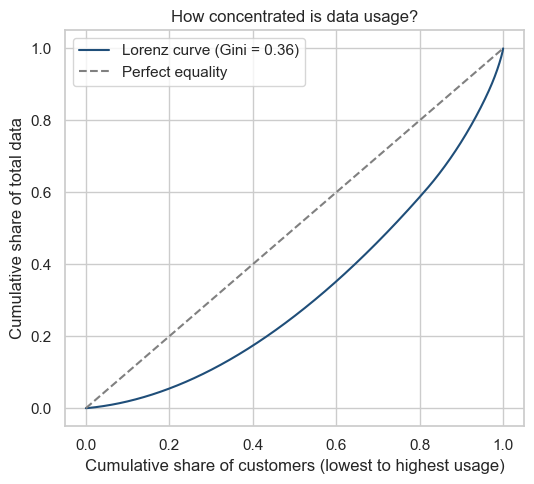

**Analysis: concentration of usage.** The Gini coefficient is **0.36** (0 = everyone uses the same amount, 1 = one customer uses everything). The top 10% of customers use **25.9%** of all data, the top 20% use 41.3% and the bottom half uses 25.6%. Usage is therefore spread fairly evenly across the base. This is partly a result of replacing outliers with the mean in Part 1, which trims the extreme heavy users, so the true concentration is probably higher.

In [57]:
# Concentration of usage: Lorenz curve and Gini coefficient
vol_sorted = np.sort(users["Total Data"].to_numpy(dtype=float)); n_cust = len(vol_sorted)
cum_share = np.cumsum(vol_sorted) / vol_sorted.sum()
gini = (2 * np.sum(np.arange(1, n_cust + 1) * vol_sorted) / (n_cust * vol_sorted.sum())) - (n_cust + 1) / n_cust
share_top = {p: vol_sorted[int(n_cust * (1 - p)):].sum() / vol_sorted.sum() * 100 for p in (0.01, 0.10, 0.20)}
share_bottom50 = vol_sorted[: n_cust // 2].sum() / vol_sorted.sum() * 100
conc = pd.DataFrame({"Share of total data (%)": [share_top[0.01], share_top[0.10], share_top[0.20], share_bottom50]},
                    index=["Top 1% of customers", "Top 10% of customers", "Top 20% of customers", "Bottom 50% of customers"])
display(conc.round(1))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(np.arange(1, n_cust + 1) / n_cust, cum_share, color="#1f4e79", label=f"Lorenz curve (Gini = {gini:.2f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect equality")
ax.set_xlabel("Cumulative share of customers (lowest to highest usage)"); ax.set_ylabel("Cumulative share of total data")
ax.set_title("How concentrated is data usage?"); ax.legend(); plt.tight_layout(); plt.show()
display(Markdown(f"**Analysis: concentration of usage.** The Gini coefficient is **{gini:.2f}** (0 = everyone uses the same amount, 1 = one customer uses everything). "
                 f"The top 10% of customers use **{share_top[0.10]:.1f}%** of all data, the top 20% use {share_top[0.20]:.1f}% and the bottom half uses {share_bottom50:.1f}%. "
                 f"Usage is therefore spread fairly evenly across the base. This is partly a result of replacing outliers with the mean in Part 1, which trims the extreme heavy users, so the true concentration is probably higher."))

### 5B.2 Uncertainty: bootstrap confidence intervals
Each headline figure is recomputed on 1,000 resamples of the customers to give a 95% interval (random seed 42).

In [58]:
# Bootstrap 95% confidence intervals for the headline figures
rng_ci = np.random.default_rng(RANDOM_STATE)
ids_ci = scores.index
persona_a = eng.loc[ids_ci, "Persona"].to_numpy(); group_a = exp_c.loc[ids_ci, "Experience Group"].to_numpy()
segment_a = scores["Segment"].to_numpy(); data_a = users.loc[ids_ci, "Total Data"].to_numpy(dtype=float)
thr_a = exp_c.loc[ids_ci, "Avg Throughput"].to_numpy(dtype=float)
sat_a = scores["Satisfaction Score"].to_numpy(); exs_a = scores["Experience Score"].to_numpy()
is_heavy, is_good, is_less = persona_a == "Heavy Users", group_a == "Good experience", segment_a == "Less satisfied"
metrics_ci = {
    "Mean data per customer (MB)": lambda i: data_a[i].mean() / 1e6,
    "Heavy users (% of customers)": lambda i: is_heavy[i].mean() * 100,
    "Good-experience customers (%)": lambda i: is_good[i].mean() * 100,
    "Less-satisfied customers (%)": lambda i: is_less[i].mean() * 100,
    "Median throughput (kbps)": lambda i: np.median(thr_a[i]),
    "Correlation: satisfaction vs experience score": lambda i: np.corrcoef(sat_a[i], exs_a[i])[0, 1],
}
B_ci = 1000
boot = {k: np.empty(B_ci) for k in metrics_ci}
for b in range(B_ci):
    ii = rng_ci.integers(0, len(ids_ci), len(ids_ci))
    for k, f in metrics_ci.items(): boot[k][b] = f(ii)
all_idx = np.arange(len(ids_ci))
ci_tbl = pd.DataFrame({"Estimate": {k: f(all_idx) for k, f in metrics_ci.items()},
                       "95% CI low": {k: np.percentile(v, 2.5) for k, v in boot.items()},
                       "95% CI high": {k: np.percentile(v, 97.5) for k, v in boot.items()}})
display(ci_tbl.round(3))
display(Markdown(f"**Analysis: uncertainty.** With {len(ids_ci):,} customers and {B_ci:,} bootstrap resamples, the intervals are very narrow: "
                 f"the share of good-experience customers is **{ci_tbl.loc['Good-experience customers (%)', 'Estimate']:.1f}%** "
                 f"(95% CI {ci_tbl.loc['Good-experience customers (%)', '95% CI low']:.1f} to {ci_tbl.loc['Good-experience customers (%)', '95% CI high']:.1f}%) and the less-satisfied share is "
                 f"**{ci_tbl.loc['Less-satisfied customers (%)', 'Estimate']:.1f}%** ({ci_tbl.loc['Less-satisfied customers (%)', '95% CI low']:.1f} to {ci_tbl.loc['Less-satisfied customers (%)', '95% CI high']:.1f}%). "
                 f"Sampling error is not the problem. The bigger uncertainty is **data quality** (imputed TCP and RTT values) and the **one-month window**, which the intervals do not capture."))

,Estimate,95% CI low,95% CI high
Mean data per customer (MB),690.96,688.15,693.85
Heavy users (% of customers),4.06,3.95,4.18
Good-experience customers (%),33.04,32.80,33.31
Less-satisfied customers (%),29.07,28.82,29.37
Median throughput (kbps),105.50,94.00,117.38
Correlation: satisfaction vs experience score,0.97,0.97,0.97


**Analysis: uncertainty.** With 106,856 customers and 1,000 bootstrap resamples, the intervals are very narrow: the share of good-experience customers is **33.0%** (95% CI 32.8 to 33.3%) and the less-satisfied share is **29.1%** (28.8 to 29.4%). Sampling error is not the problem. The bigger uncertainty is **data quality** (imputed TCP and RTT values) and the **one-month window**, which the intervals do not capture.

### 5B.3 Significance tests: do handset brands differ?
Kruskal-Wallis and Mann-Whitney tests are used because throughput is strongly skewed; effect sizes are reported because with about 95,000 customers p-values alone say little.

In [59]:
# Hypothesis tests: do handset brands differ in throughput and in experience group?
from scipy.stats import kruskal, mannwhitneyu, chi2_contingency
brand = exp_c["Handset Type"].str.split().str[0]
three = ["Apple", "Samsung", "Huawei"]; in3 = brand.isin(three)
thr_by = {b: exp_c.loc[in3 & (brand == b), "Avg Throughput"].to_numpy(dtype=float) for b in three}
H_kw, p_kw = kruskal(*thr_by.values())

def pfmt(p): return "< 0.001" if p < 0.001 else f"{p:.3f}"
rows = []
for a, b in [("Apple", "Samsung"), ("Apple", "Huawei"), ("Samsung", "Huawei")]:
    U, p = mannwhitneyu(thr_by[a], thr_by[b], alternative="two-sided")
    rows.append({"Comparison": f"{a} vs {b}", "Median A (kbps)": np.median(thr_by[a]), "Median B (kbps)": np.median(thr_by[b]),
                 "Rank-biserial r": 2 * U / (len(thr_by[a]) * len(thr_by[b])) - 1, "p (Bonferroni x3)": pfmt(min(1, p * 3))})
router = exp_c.loc[exp_c["Handset Type"] == "Huawei B528S-23A", "Avg Throughput"].to_numpy(dtype=float)
iphone = exp_c.loc[exp_c["Handset Type"].str.startswith("Apple iPhone"), "Avg Throughput"].to_numpy(dtype=float)
U, p = mannwhitneyu(router, iphone, alternative="two-sided")
rows.append({"Comparison": "Huawei B528S-23A router vs all iPhones", "Median A (kbps)": np.median(router), "Median B (kbps)": np.median(iphone),
             "Rank-biserial r": 2 * U / (len(router) * len(iphone)) - 1, "p (Bonferroni x3)": pfmt(min(1, p * 3))})
mw_tbl = pd.DataFrame(rows).set_index("Comparison")
print(f"Kruskal-Wallis, throughput across Apple / Samsung / Huawei: H = {H_kw:,.0f}, p {pfmt(p_kw)}")
display(mw_tbl.round(2))

ct_brand = pd.crosstab(brand[in3], exp_c.loc[in3, "Experience Group"])
chi2_b, p_chi_b, dof_b, _ = chi2_contingency(ct_brand)
v_brand = np.sqrt(chi2_b / (ct_brand.to_numpy().sum() * (min(ct_brand.shape) - 1)))
print(f"Chi-square, brand x experience group: chi2 = {chi2_b:,.0f}, dof = {dof_b}, p {pfmt(p_chi_b)}, Cramer's V = {v_brand:.2f}")
display((ct_brand.div(ct_brand.sum(axis=1), axis=0) * 100).round(1).rename_axis("Share of brand's customers (%)"))
share_brand = ct_brand.div(ct_brand.sum(axis=1), axis=0) * 100
hw_mask = (brand == "Huawei") & (exp_c["Handset Type"] != "Huawei B528S-23A")
hw_good_no_router = (exp_c.loc[hw_mask, "Experience Group"] == "Good experience").mean() * 100
display(Markdown(f"**Analysis: handset brands.** Throughput differs significantly between brands (Kruskal-Wallis p {pfmt(p_kw)}), but with about {int(in3.sum()):,} customers almost any difference is significant, so the **effect size** matters more than the p-value. "
                 f"The rank-biserial correlation between Apple and Samsung is {rows[0]['Rank-biserial r']:.2f} and between Apple and Huawei {rows[1]['Rank-biserial r']:.2f} (0 = no difference, +1 = the first group is always higher). "
                 f"The Huawei B528S-23A router against all iPhones has an effect of {rows[3]['Rank-biserial r']:.2f}, a very large gap, which confirms that the device type (fixed-wireless router or phone) matters more than the brand. "
                 f"Brand and experience group are strongly related (Cramer's V = {v_brand:.2f}, where 0.1 is small, 0.3 medium and 0.5 large): "
                 f"**{share_brand.loc['Apple', 'Low throughput (low latency)']:.0f}% of Apple customers sit in the low-throughput group**, **{share_brand.loc['Samsung', 'Poor experience (high latency)']:.0f}% of Samsung customers sit in the high-latency group** and "
                 f"{share_brand.loc['Huawei', 'Good experience']:.0f}% of Huawei customers have a good experience ({hw_good_no_router:.0f}% once the B528S-23A router is left out). Many throughput values are imputed means (Part 1), which creates ties, so read the medians as indicative."))

Kruskal-Wallis, throughput across Apple / Samsung / Huawei: H = 9,216, p < 0.001


,Median A (kbps),Median B (kbps),Rank-biserial r,p (Bonferroni x3)
Comparison,,,,
Apple vs Samsung,57.50,63.50,-0.04,< 0.001
Apple vs Huawei,57.50,"4,607.69",-0.45,< 0.001
Samsung vs Huawei,63.50,"4,607.69",-0.40,< 0.001
Huawei B528S-23A router vs all iPhones,"10,375.56",57.50,0.75,< 0.001


Chi-square, brand x experience group: chi2 = 40,641, dof = 4, p < 0.001, Cramer's V = 0.46


Experience Group,Good experience,Low throughput (low latency),Poor experience (high latency)
Share of brand's customers (%),,,
Apple,20.80,73.00,6.10
Huawei,57.40,29.80,12.80
Samsung,30.20,14.70,55.10


**Analysis: handset brands.** Throughput differs significantly between brands (Kruskal-Wallis p < 0.001), but with about 95,062 customers almost any difference is significant, so the **effect size** matters more than the p-value. The rank-biserial correlation between Apple and Samsung is -0.04 and between Apple and Huawei -0.45 (0 = no difference, +1 = the first group is always higher). The Huawei B528S-23A router against all iPhones has an effect of 0.75, a very large gap, which confirms that the device type (fixed-wireless router or phone) matters more than the brand. Brand and experience group are strongly related (Cramer's V = 0.46, where 0.1 is small, 0.3 medium and 0.5 large): **73% of Apple customers sit in the low-throughput group**, **55% of Samsung customers sit in the high-latency group** and 57% of Huawei customers have a good experience (40% once the B528S-23A router is left out). Many throughput values are imputed means (Part 1), which creates ties, so read the medians as indicative.

### 5B.4 Engagement x experience: who is badly served?
Cross-tabulates the engagement personas (Part 3) with the experience groups (Part 4) to find valuable customers with a weak experience.

Experience Group,Good experience,Low throughput (low latency),Poor experience (high latency)
Customers (count),,,
Light Users,26483,33469,20808
Regular Users,6719,10261,4773
Heavy Users,2107,1398,838


Experience Group,Good experience,Low throughput (low latency),Poor experience (high latency)
Share of persona (%),,,
Light Users,32.80,41.40,25.80
Regular Users,30.90,47.20,21.90
Heavy Users,48.50,32.20,19.30


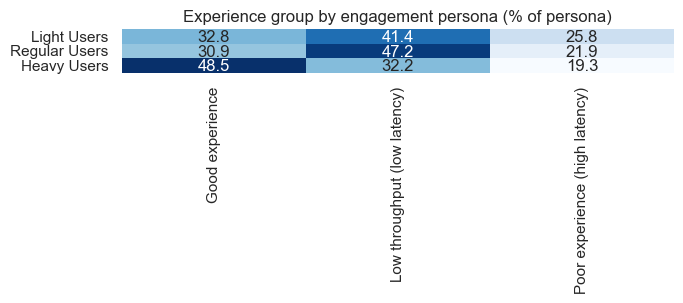

**Analysis: engagement x experience.** Customers in the two weak experience groups are **67.0% of customers and 65.3% of all traffic**, so poor network quality touches a large part of the volume, not only a few light users. Among **Heavy Users, 2,236 of 4,343 (51.5%) are in a weak experience group**; they carry 4.7 TB, the first accounts to protect. Heavy Users are somewhat better served (48.5% have a good experience against 32.8% of Light Users), but the link between persona and experience is weak (Cramer's V = 0.06). Weak experience is spread across all usage levels, so upgrades should be planned by where users are poorly served, not only by how much they use.

In [60]:
# Engagement x experience: who is both valuable and badly served?
weak_groups = ["Low throughput (low latency)", "Poor experience (high latency)"]
grp = exp_c.loc[ids_ci, "Experience Group"]; per = eng.loc[ids_ci, "Persona"]; dat = users.loc[ids_ci, "Total Data"]
ct_pe = pd.crosstab(per, grp).loc[["Light Users", "Regular Users", "Heavy Users"], ["Good experience"] + weak_groups]
row_pct = ct_pe.div(ct_pe.sum(axis=1), axis=0) * 100
display(ct_pe.rename_axis("Customers (count)")); display(row_pct.round(1).rename_axis("Share of persona (%)"))
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.heatmap(row_pct, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Experience group by engagement persona (% of persona)"); ax.set_xlabel(""); ax.set_ylabel(""); plt.tight_layout(); plt.show()
weak_mask = grp.isin(weak_groups)
weak_cust_share = weak_mask.mean() * 100; weak_data_share = dat[weak_mask].sum() / dat.sum() * 100
heavy_weak_n = int(((per == "Heavy Users") & weak_mask).sum()); heavy_n = int((per == "Heavy Users").sum())
heavy_weak_tb = dat[(per == "Heavy Users") & weak_mask].sum() / 1e12
chi2_pe, p_pe, dof_pe, _ = chi2_contingency(ct_pe)
v_pe = np.sqrt(chi2_pe / (ct_pe.to_numpy().sum() * (min(ct_pe.shape) - 1)))
display(Markdown(f"**Analysis: engagement x experience.** Customers in the two weak experience groups are **{weak_cust_share:.1f}% of customers and {weak_data_share:.1f}% of all traffic**, so poor network quality touches a large part of the volume, not only a few light users. "
                 f"Among **Heavy Users, {heavy_weak_n:,} of {heavy_n:,} ({heavy_weak_n / heavy_n * 100:.1f}%) are in a weak experience group**; they carry {heavy_weak_tb:.1f} TB, the first accounts to protect. "
                 f"Heavy Users are somewhat better served ({row_pct.loc['Heavy Users', 'Good experience']:.1f}% have a good experience against {row_pct.loc['Light Users', 'Good experience']:.1f}% of Light Users), but the link between persona and experience is weak (Cramer's V = {v_pe:.2f}). "
                 f"Weak experience is spread across all usage levels, so upgrades should be planned by where users are poorly served, not only by how much they use."))

### 5B.5 When do sessions happen?
The `Start` timestamp gives the hour of day and day of week of each session.

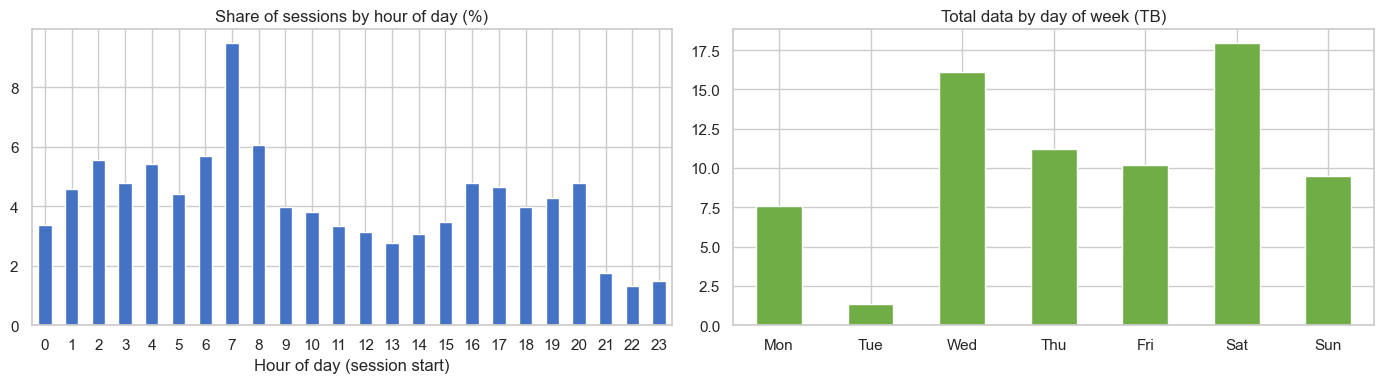

**Analysis: timing.** The data covers **22 distinct days** (04 Apr 2019 to 29 Apr 2019). The busiest hour is **07:00** (9.5% of sessions) and the busiest three-hour block starts at **06:00**, carrying 21.2% of all sessions (an even spread would be 12.5%). Per day with data, a weekend day carries about 4.6 TB against 2.9 TB for a weekday (+57%). Session start is the only time field and its time zone is not documented, so this shows when sessions begin (in recorded time), not when load peaks; it is still a sensible starting point for capacity and maintenance planning.

In [61]:
# When is the network busy? Session timing from the Start column
ts = d["Start"]; vol_s = d["Total DL (Bytes)"] + d["Total UL (Bytes)"]
hourly = pd.DataFrame({"sessions": ts.dt.hour.value_counts().sort_index(), "data_TB": vol_s.groupby(ts.dt.hour).sum() / 1e12}).reindex(range(24), fill_value=0)
hourly["% of sessions"] = hourly["sessions"] / hourly["sessions"].sum() * 100
peak_hour = int(hourly["% of sessions"].idxmax())
roll3 = hourly["% of sessions"].rolling(3).sum().shift(-2); block_start = int(roll3.idxmax()); block_share = float(roll3.max())
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wk = pd.DataFrame({"sessions": ts.dt.dayofweek.value_counts().sort_index(), "data_TB": vol_s.groupby(ts.dt.dayofweek).sum() / 1e12}); wk.index = days
n_days = ts.dt.normalize().nunique()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
hourly["% of sessions"].plot(kind="bar", ax=ax[0], color="#4472c4", rot=0, title="Share of sessions by hour of day (%)"); ax[0].set_xlabel("Hour of day (session start)")
wk["data_TB"].plot(kind="bar", ax=ax[1], color="#70ad47", rot=0, title="Total data by day of week (TB)")
plt.tight_layout(); plt.show()
day_counts = ts.dt.normalize().drop_duplicates().dt.dayofweek.value_counts()
per_day = {k: wk.loc[days[k], "data_TB"] / day_counts[k] for k in day_counts.index}
weekend_avg = np.mean([per_day[k] for k in (5, 6) if k in per_day]); weekday_avg = np.mean([per_day[k] for k in range(5) if k in per_day])
display(Markdown(f"**Analysis: timing.** The data covers **{n_days} distinct days** ({ts.min():%d %b %Y} to {ts.max():%d %b %Y}). "
                 f"The busiest hour is **{peak_hour:02d}:00** ({hourly.loc[peak_hour, '% of sessions']:.1f}% of sessions) and the busiest three-hour block starts at **{block_start:02d}:00**, carrying {block_share:.1f}% of all sessions (an even spread would be 12.5%). "
                 f"Per day with data, a weekend day carries about {weekend_avg:.1f} TB against {weekday_avg:.1f} TB for a weekday ({(weekend_avg / weekday_avg - 1) * 100:+.0f}%). "
                 f"Session start is the only time field and its time zone is not documented, so this shows when sessions begin (in recorded time), not when load peaks; it is still a sensible starting point for capacity and maintenance planning."))

### 5B.6 What drives the satisfaction model?
Permutation importance shuffles one feature at a time on held-out data and measures how much R2 drops.

,R2 lost when shuffled,std
Avg RTT,0.83,0.01
Avg Throughput,0.45,0.00
Avg TCP,0.36,0.00
Sessions,0.02,0.00
Total Data,0.01,0.00
Duration_ms,0.01,0.00


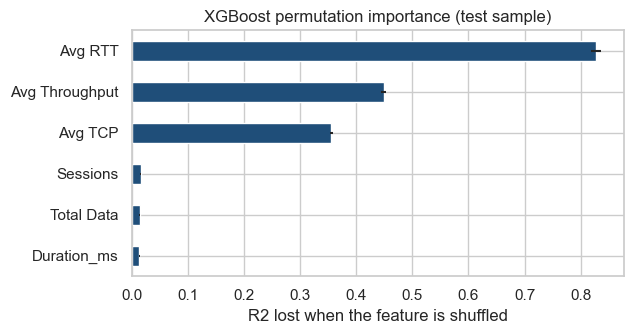

**Analysis: model drivers.** The most important feature is **Avg RTT**. The three experience features (TCP, RTT, throughput) account for **97%** of the total importance, which matches the correlation of 0.97 between satisfaction and the experience score. This is expected, because the score is built from these same features, so the ranking describes the scoring formula rather than real customer behaviour.

In [62]:
# What drives the satisfaction model? Permutation importance on the held-out set
from sklearn.inspection import permutation_importance
xgb_model = fitted["XGBoost"]
samp_x = Xte.sample(5000, random_state=RANDOM_STATE); samp_y = pd.Series(np.asarray(yte), index=Xte.index).loc[samp_x.index]
pi = permutation_importance(xgb_model, samp_x, samp_y, n_repeats=5, random_state=RANDOM_STATE, scoring="r2")
imp = pd.DataFrame({"R2 lost when shuffled": pi.importances_mean, "std": pi.importances_std}, index=samp_x.columns).sort_values("R2 lost when shuffled", ascending=False)
display(imp.round(4))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
imp["R2 lost when shuffled"].iloc[::-1].plot(kind="barh", ax=ax, xerr=imp["std"].iloc[::-1], color="#1f4e79")
ax.set_xlabel("R2 lost when the feature is shuffled"); ax.set_title("XGBoost permutation importance (test sample)"); plt.tight_layout(); plt.show()
top_f = imp.index[0]; exp_feats = ["Avg TCP", "Avg RTT", "Avg Throughput"]
share_exp = imp.loc[exp_feats, "R2 lost when shuffled"].sum() / imp["R2 lost when shuffled"].sum() * 100
display(Markdown(f"**Analysis: model drivers.** The most important feature is **{top_f}**. The three experience features (TCP, RTT, throughput) account for **{share_exp:.0f}%** of the total importance, "
                 f"which matches the correlation of 0.97 between satisfaction and the experience score. This is expected, because the score is built from these same features, so the ranking describes the scoring formula rather than real customer behaviour."))

### 5B.7 Are the k-means segments stable?
The engagement and experience clusterings are repeated with eight other random starts and compared with the main solution.

In [63]:
# Are the k-means groups stable? Adjusted Rand index across random seeds
from sklearn.metrics import adjusted_rand_score
seeds = [1, 2, 3, 4, 5, 6, 7, 8]
ari_eng = [adjusted_rand_score(km_eng.labels_, KMeans(n_clusters=3, n_init=5, random_state=s).fit_predict(X_eng)) for s in seeds]
ari_exp = [adjusted_rand_score(km_exp.labels_, KMeans(n_clusters=3, n_init=5, random_state=s).fit_predict(X_exp)) for s in seeds]
stab = pd.DataFrame({"Engagement clusters (k=3)": ari_eng, "Experience clusters (k=3)": ari_exp}, index=[f"seed {s}" for s in seeds]).T
stab["min"], stab["mean"] = stab.min(axis=1), stab.iloc[:, :len(seeds)].mean(axis=1)
display(stab[["min", "mean"]].round(3))
display(Markdown(f"**Analysis: stability.** The adjusted Rand index compares each re-run with the main solution (1.0 = identical groups). "
                 f"Engagement clusters: minimum **{min(ari_eng):.2f}**, mean {np.mean(ari_eng):.2f}. Experience clusters: minimum **{min(ari_exp):.2f}**, mean {np.mean(ari_exp):.2f}. "
                 f"Values close to 1 mean the personas do not depend on the random start, so the segments used in Parts 3 to 5 are reproducible."))

,min,mean
Engagement clusters (k=3),1.00,1.00
Experience clusters (k=3),1.00,1.00


**Analysis: stability.** The adjusted Rand index compares each re-run with the main solution (1.0 = identical groups). Engagement clusters: minimum **1.00**, mean 1.00. Experience clusters: minimum **1.00**, mean 1.00. Values close to 1 mean the personas do not depend on the random start, so the segments used in Parts 3 to 5 are reproducible.

In [64]:
# Summary of the additional analysis
display(Markdown("### Key takeaways from the additional analysis\n"
    f"- **Usage is fairly evenly spread:** Gini {gini:.2f}; the top 10% of customers use {share_top[0.10]:.1f}% of the data.\n"
    f"- **Headline shares are precise:** good experience {ci_tbl.loc['Good-experience customers (%)', 'Estimate']:.1f}% (95% CI {ci_tbl.loc['Good-experience customers (%)', '95% CI low']:.1f} to {ci_tbl.loc['Good-experience customers (%)', '95% CI high']:.1f}%); the real risk is data quality, not sampling.\n"
    f"- **Device type matters more than brand:** router vs iPhone effect size {rows[3]['Rank-biserial r']:.2f}; Apple vs Samsung only {abs(rows[0]['Rank-biserial r']):.2f}. Brand still predicts the experience group (Cramer's V {v_brand:.2f}).\n"
    f"- **Poor service reaches the volume:** weak-experience customers carry {weak_data_share:.1f}% of traffic and {heavy_weak_n / heavy_n * 100:.1f}% of Heavy Users are in a weak group.\n"
    f"- **Sessions peak early in the day:** the busiest three-hour block starts at {block_start:02d}:00 and holds {block_share:.1f}% of sessions.\n"
    f"- **The segments are reproducible:** adjusted Rand index of at least {min(min(ari_eng), min(ari_exp)):.3f} across random seeds.\n"
    f"- **The satisfaction model learns the experience features:** they make up {share_exp:.0f}% of the permutation importance, as expected for a score built from them."))

### Key takeaways from the additional analysis
- **Usage is fairly evenly spread:** Gini 0.36; the top 10% of customers use 25.9% of the data.
- **Headline shares are precise:** good experience 33.0% (95% CI 32.8 to 33.3%); the real risk is data quality, not sampling.
- **Device type matters more than brand:** router vs iPhone effect size 0.75; Apple vs Samsung only 0.04. Brand still predicts the experience group (Cramer's V 0.46).
- **Poor service reaches the volume:** weak-experience customers carry 65.3% of traffic and 51.5% of Heavy Users are in a weak group.
- **Sessions peak early in the day:** the busiest three-hour block starts at 06:00 and holds 21.2% of sessions.
- **The segments are reproducible:** adjusted Rand index of at least 0.998 across random seeds.
- **The satisfaction model learns the experience features:** they make up 97% of the permutation importance, as expected for a score built from them.

### 5B.8 Save the results for the dashboard and MLflow
The aggregated results (no customer IDs) are saved as small CSV files. The Streamlit page `5 · Extra analysis` reads them, and Part 6 logs them to MLflow.

In [65]:
# Save the additional results as small CSV files (no customer IDs) for the Streamlit dashboard and MLflow
EXTRA_DIR = os.path.join("tellco-analytics", "data", "processed", "dashboard"); os.makedirs(EXTRA_DIR, exist_ok=True)
lz = np.linspace(0, n_cust - 1, 201).astype(int)
pd.DataFrame({"x": (lz + 1) / n_cust, "y": cum_share[lz]}).to_csv(os.path.join(EXTRA_DIR, "extra_lorenz.csv"), index=False)
conc.to_csv(os.path.join(EXTRA_DIR, "extra_concentration.csv"))
ci_tbl.to_csv(os.path.join(EXTRA_DIR, "extra_ci.csv"))
mw_tbl.to_csv(os.path.join(EXTRA_DIR, "extra_brand_tests.csv"))
share_brand.rename_axis("brand").to_csv(os.path.join(EXTRA_DIR, "extra_brand_experience.csv"))
row_pct.rename_axis("persona").to_csv(os.path.join(EXTRA_DIR, "extra_persona_experience.csv"))
hourly.rename_axis("hour").rename(columns={"% of sessions": "pct_sessions"}).to_csv(os.path.join(EXTRA_DIR, "extra_hourly.csv"))
wk_out = wk.rename_axis("day").copy(); wk_out["days_with_data"] = [day_counts.get(i, 0) for i in range(7)]; wk_out["TB_per_day"] = wk_out["data_TB"] / wk_out["days_with_data"].replace(0, np.nan)
wk_out.to_csv(os.path.join(EXTRA_DIR, "extra_weekday.csv"))
imp.rename_axis("feature").rename(columns={"R2 lost when shuffled": "r2_lost"}).to_csv(os.path.join(EXTRA_DIR, "extra_importance.csv"))
stab[["min", "mean"]].rename_axis("clustering").to_csv(os.path.join(EXTRA_DIR, "extra_stability.csv"))
summary_vals = {"gini": gini, "top10_share": share_top[0.10], "weak_traffic_share": weak_data_share, "weak_customer_share": weak_cust_share,
                "heavy_weak_pct": heavy_weak_n / heavy_n * 100, "cramers_v_brand": v_brand, "cramers_v_persona": v_pe,
                "router_vs_iphone_effect": rows[3]["Rank-biserial r"], "busiest_block_start_hour": block_start, "busiest_block_share": block_share,
                "ari_min_engagement": min(ari_eng), "ari_min_experience": min(ari_exp), "experience_importance_share": share_exp,
                "good_experience_ci_low": ci_tbl.loc["Good-experience customers (%)", "95% CI low"], "good_experience_ci_high": ci_tbl.loc["Good-experience customers (%)", "95% CI high"]}
pd.Series(summary_vals, name="value").rename_axis("metric").to_csv(os.path.join(EXTRA_DIR, "extra_summary.csv"))
print("Saved", len(os.listdir(EXTRA_DIR)), "extra_*.csv files in", EXTRA_DIR, "(aggregates only, no customer IDs)")

Saved 11 extra_*.csv files in tellco-analytics\data\processed\dashboard (aggregates only, no customer IDs)


## Part 6: Brief task 4.7, Model deployment and tracking with MLflow
Every model is logged as its own run (parameters, metrics, loss curve where available, model artifact), plus the exported scores as an artifact. After running, open a terminal in the notebook folder, run `python -m mlflow ui --backend-store-uri sqlite:///mlflow_tellco.db`, browse to `http://localhost:5000` and take screenshots of the **Parameters, Metrics and Artifacts**. Use *Download CSV* on the runs table for the CSV the brief asks for.

### 6.1 Deploy the model: save it, call it, serve it
Brief task 4.7 asks to **deploy** the model and track it. The selected model is saved together with its feature list and the **code version** (git commit), wrapped in a `predict_satisfaction` function, and exposed through a small **FastAPI** service in `tellco-analytics/app/predict_api.py`. The Docker image built in Part 9 includes the `api` extra, so the same image can serve the model:

```bash
cd tellco-analytics
docker build -t tellco-analytics .
docker run --rm -p 8000:8000 -v "$PWD/models:/app/models" tellco-analytics uvicorn app.predict_api:app --host 0.0.0.0 --port 8000
# then open http://localhost:8000/docs
```
Tip: run `git init` and `git commit` in the project folder before this part, so the code version below is a real commit hash instead of `not-a-git-repo`.

In [66]:
import joblib, subprocess, datetime

def git_commit():
    """Short commit hash of the project: current folder first, then the tellco-analytics repo folder."""
    for folder in (".", "tellco-analytics"):
        try:
            return subprocess.check_output(["git", "-C", folder, "rev-parse", "--short", "HEAD"], stderr=subprocess.DEVNULL).decode().strip()
        except Exception:
            continue
    return "not-a-git-repo"

commit = git_commit()
MODEL_DIR = os.path.join("tellco-analytics", "models")
os.makedirs(MODEL_DIR, exist_ok=True)
MODEL_PATH = os.path.join(MODEL_DIR, "satisfaction_model.joblib")
joblib.dump({"model": best_model, "name": best_name, "features": list(features.columns),
             "code_version": commit, "trained_at": datetime.datetime.now().isoformat(timespec="seconds")}, MODEL_PATH)
print("Saved", MODEL_PATH, "| model:", best_name, "| code version:", commit)

def predict_satisfaction(sessions, duration_ms, total_data, avg_tcp, avg_rtt, avg_throughput, path=MODEL_PATH):
    """Predict the 0-1 satisfaction score of one customer from raw engagement + experience metrics."""
    b = joblib.load(path)
    row = pd.DataFrame([[sessions, duration_ms, total_data, avg_tcp, avg_rtt, avg_throughput]], columns=b["features"])
    return float(b["model"].predict(row)[0])

r0 = features.iloc[0]
print("Demo customer:", r0.round(1).to_dict())
print("Predicted satisfaction:", round(predict_satisfaction(*r0.values), 4), "| actual score:", round(float(target.iloc[0]), 4))

Saved tellco-analytics\models\satisfaction_model.joblib | model: XGBoost | code version: not-a-git-repo
Demo customer: {'Sessions': 1.0, 'Duration_ms': 116720140.0, 'Total Data': 878690574.0, 'Avg TCP': 10784786.5, 'Avg RTT': 23.0, 'Avg Throughput': 38.0}
Predicted satisfaction: 0.1877 | actual score: 0.1893


In [67]:
API_SOURCE = '"""Prediction API for the satisfaction model.\n\nRun:  uvicorn app.predict_api:app --host 0.0.0.0 --port 8000\nTest: curl -X POST localhost:8000/predict -H "Content-Type: application/json" \\\\\n        -d \'{"Sessions": 2, "Duration_ms": 1.2e8, "Total_Data": 7e8, "Avg_TCP": 5e6, "Avg_RTT": 40, "Avg_Throughput": 3000}\'\n"""\nimport os\n\nimport joblib\nimport pandas as pd\nfrom fastapi import FastAPI\nfrom pydantic import BaseModel\n\nMODEL_PATH = os.environ.get("MODEL_PATH", "models/satisfaction_model.joblib")\nbundle = joblib.load(MODEL_PATH)\napp = FastAPI(title="TellCo satisfaction model")\n\n\nclass Customer(BaseModel):\n    Sessions: float\n    Duration_ms: float\n    Total_Data: float\n    Avg_TCP: float\n    Avg_RTT: float\n    Avg_Throughput: float\n\n\n@app.get("/health")\ndef health():\n    return {"status": "ok", "model": bundle["name"], "code_version": bundle["code_version"]}\n\n\n@app.post("/predict")\ndef predict(c: Customer):\n    row = pd.DataFrame([[c.Sessions, c.Duration_ms, c.Total_Data, c.Avg_TCP, c.Avg_RTT, c.Avg_Throughput]],\n                       columns=bundle["features"])\n    return {"satisfaction_score": float(bundle["model"].predict(row)[0]), "model": bundle["name"]}\n'

os.makedirs(os.path.join("tellco-analytics", "app"), exist_ok=True)
with open(os.path.join("tellco-analytics", "app", "predict_api.py"), "w") as f:
    f.write(API_SOURCE)
print("Wrote tellco-analytics/app/predict_api.py")

Wrote tellco-analytics/app/predict_api.py


### 6.2 Track the models with MLflow

Each model is logged as its own run (parameters, metrics, model, loss curve for XGBoost). Run this cell after Git is installed, or let it fall back to a silent warning if Git is not found.


MLflow 3.17.2 | tracking database: mlflow_tellco.db


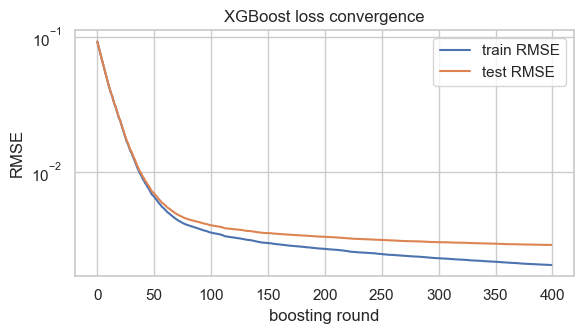

,mlflow.runName,code_version,start_time,end_time,mae,rmse,r2,selected
0,xgboost,not-a-git-repo,2026-11-27 04:35:16.904000+00:00,2026-11-27 04:35:26.092000+00:00,0.00,0.00,1.00,True
1,random_forest,not-a-git-repo,2026-11-27 04:35:14.073000+00:00,2026-11-27 04:35:16.897000+00:00,0.00,0.01,1.00,False
2,linear_regression,not-a-git-repo,2026-11-27 04:35:07.670000+00:00,2026-11-27 04:35:14.060000+00:00,0.03,0.04,0.82,False


Runs table saved to mlflow_runs.csv (code version, start and end time, parameters, metrics).
MLflow runs logged to mlflow_tellco.db. Start the UI with:  python -m mlflow ui --backend-store-uri sqlite:///mlflow_tellco.db


In [68]:
import os, logging

# Point GitPython at Git (must run before mlflow is imported; restart the kernel if mlflow was already imported)
git_exe = r"C:\Program Files\Git\cmd\git.exe"
if os.path.exists(git_exe):
    os.environ["GIT_PYTHON_GIT_EXECUTABLE"] = git_exe
else:
    os.environ["GIT_PYTHON_REFRESH"] = "quiet"      # Git not found there: silence the warning

try:
    import mlflow, mlflow.sklearn, mlflow.xgboost
except ImportError as e:
    raise SystemExit(f"Missing package: {e}. Run: %pip install mlflow xgboost")

logging.getLogger("mlflow").setLevel(logging.WARNING)
logging.getLogger("mlflow.sklearn").setLevel(logging.ERROR)   # hides the pickle/cloudpickle notice

import time

def open_tracking(db="mlflow_tellco.db", experiment="satisfaction-model"):
    """Use a local SQLite store; if the file was written by another MLflow version, switch to a fresh one."""
    try:
        mlflow.set_tracking_uri(f"sqlite:///{db}")
        mlflow.set_experiment(experiment)
        return db
    except Exception as e:                      # e.g. out-of-date database schema
        alt = f"mlflow_tellco_{time.strftime('%Y%m%d_%H%M%S')}.db"
        print(f"{db} cannot be used with MLflow {mlflow.__version__} ({type(e).__name__}); using a fresh database: {alt}")
        mlflow.set_tracking_uri(f"sqlite:///{alt}")
        mlflow.set_experiment(experiment)
        return alt

MLFLOW_DB = open_tracking()
print("MLflow", mlflow.__version__, "| tracking database:", MLFLOW_DB)

import hashlib
def _data_tags():
    """Tags that identify the exact data and software behind each run."""
    tags = {"n_customers": str(len(features)), "mlflow_version": mlflow.__version__}
    for path in ("telcom_data.xlsx", os.path.join("data", "raw", "telcom_data.xlsx")):
        if os.path.exists(path):
            h = hashlib.md5()
            with open(path, "rb") as fh:
                for chunk in iter(lambda: fh.read(1 << 20), b""): h.update(chunk)
            tags.update({"data_file": os.path.basename(path), "data_md5": h.hexdigest()}); break
    return tags
DATA_TAGS = _data_tags()

run_ids = []
for name, mdl in fitted.items():
    with mlflow.start_run(run_name=name.lower().replace(" ", "_")) as run:
        run_ids.append(run.info.run_id)
        mlflow.log_params({"model": name, "test_size": 0.2, "seed": RANDOM_STATE, "n_features": features.shape[1],
                           **{k: v for k, v in mdl.get_params().items()
                              if isinstance(v, (int, float, str, bool)) and v is not None}})
        p = mdl.predict(Xte)
        mlflow.log_metric("mae", float(mean_absolute_error(yte, p)))
        mlflow.log_metric("rmse", float(np.sqrt(mean_squared_error(yte, p))))
        mlflow.log_metric("r2", float(r2_score(yte, p)))
        if name in cv.index: mlflow.log_metric("cv_r2_mean", float(cv.loc[name, "CV R2 mean"]))
        if name == "XGBoost":                      # loss convergence: train and test RMSE per boosting round
            ev = mdl.evals_result()
            tr_loss, te_loss = ev["validation_0"]["rmse"], ev["validation_1"]["rmse"]
            for k, (a, b) in enumerate(zip(tr_loss, te_loss)):
                mlflow.log_metric("train_rmse", float(a), step=k)
                mlflow.log_metric("eval_rmse", float(b), step=k)
            mlflow.log_metric("final_train_rmse", float(tr_loss[-1])); mlflow.log_metric("final_eval_rmse", float(te_loss[-1]))
            fig, ax = plt.subplots(figsize=(6, 3.5))
            ax.plot(tr_loss, label="train RMSE"); ax.plot(te_loss, label="test RMSE")
            ax.set_xlabel("boosting round"); ax.set_ylabel("RMSE"); ax.set_yscale("log"); ax.legend(); ax.set_title("XGBoost loss convergence")
            fig.tight_layout(); fig.savefig("xgboost_loss_convergence.png", dpi=150); plt.show()
            mlflow.log_artifact("xgboost_loss_convergence.png")
            mlflow.xgboost.log_model(mdl, name="model")
        else:
            mlflow.sklearn.log_model(mdl, name="model", serialization_format="cloudpickle")
        mlflow.log_artifact("final_scores.csv")
        if name == best_name:                      # attach the deployed model file only to the selected run
            mlflow.log_artifact(MODEL_PATH)
        mlflow.set_tags({"code_version": commit, "source": "notebook", **DATA_TAGS})
        mlflow.set_tag("selected", str(name == best_name))

runs = mlflow.search_runs(experiment_names=["satisfaction-model"])
runs = runs[runs["run_id"].isin(run_ids)]          # only this execution, not earlier re-runs
display(runs[["tags.mlflow.runName", "tags.code_version", "start_time", "end_time",
              "metrics.mae", "metrics.rmse", "metrics.r2", "tags.selected"]]
        .rename(columns=lambda c: c.split(".", 1)[-1]))
runs.to_csv("mlflow_runs.csv", index=False)
print("Runs table saved to mlflow_runs.csv (code version, start and end time, parameters, metrics).")
print(f"MLflow runs logged to {MLFLOW_DB}. Start the UI with:  python -m mlflow ui --backend-store-uri sqlite:///{MLFLOW_DB}")

**Analysis: MLflow tracking.** Each model is one run in the `satisfaction-model` experiment with parameters, MAE/RMSE/R², the model artifact and `final_scores.csv`; XGBoost also logs its train and test loss per boosting round (the loss curve, saved as `xgboost_loss_convergence.png` and attached as an artifact), and every run logs its 5-fold cross-validation R². The runs table above shows the three runs side by side, and the run that matches the selected model is tagged `selected=True`. Start `python -m mlflow ui --backend-store-uri sqlite:///mlflow_tellco.db`, open `http://localhost:5000`, and take screenshots of Parameters, Metrics and Artifacts for the report.

### 6.3 Track the additional analysis as its own run
The results of Part 5B are logged as one MLflow run in a separate experiment (`tellco-extra-analysis`): parameters, 15 metrics and the `extra_*.csv` artifacts, tagged with the code version and a hash of the data file. The three model runs above stay in `satisfaction-model`.

In [69]:
# Track the additional analysis as its own MLflow run (separate experiment, so the three model runs stay clean)
import glob
open_tracking(experiment="tellco-extra-analysis")
with mlflow.start_run(run_name="extra_analysis") as run_extra:
    mlflow.log_params({"bootstrap_resamples": B_ci, "stability_seeds": len(seeds), "seed": RANDOM_STATE})
    mlflow.log_metrics({k: float(v) for k, v in summary_vals.items()})
    for f in sorted(glob.glob(os.path.join(EXTRA_DIR, "extra_*.csv"))):
        mlflow.log_artifact(f, artifact_path="extra_analysis")
    mlflow.set_tags({"code_version": commit, "source": "notebook part 5B", **DATA_TAGS})
open_tracking()                                    # back to the model experiment
print("Logged run 'extra_analysis' with", len(summary_vals), "metrics and", len(glob.glob(os.path.join(EXTRA_DIR, "extra_*.csv"))), "artifact files; code version:", commit)

Logged run 'extra_analysis' with 15 metrics and 11 artifact files; code version: not-a-git-repo


## Part 7: Executive summary, recommendations and limitations

### Executive summary
| Area | Finding |
|---|---|
| Customer base | **106,856 customers** in one month; Apple is the top manufacturer (44% of top-3 sessions), and a Huawei home router is the top single device |
| Usage | Average **691 MB** per customer; Gaming is the main traffic driver, followed by YouTube and Netflix |
| Engagement | **4.1% Heavy Users generate 12.8% of traffic**; 75.6% are Light Users (about 0.5 GB) |
| Experience | Only **33%** of customers have a good experience; about **58%** average under 1 Mbps |
| Satisfaction | **29%** of customers are in the low-satisfaction segment; satisfaction is driven by network experience, not by usage |
| Extra analysis | Weak experience reaches **65%** of traffic; handset brand predicts the experience group (Cramer's V 0.46) while device type matters more than brand; the segments are stable across random seeds (Part 5B) |
| Model | Tree models (Random Forest, XGBoost) recover the satisfaction score far better than Linear Regression (see Part 5.3) |

### Business recommendations
1. **Prioritise network quality over acquisition.** Satisfaction tracks experience (0.97), and about two thirds of customers sit in weak-experience clusters, so capacity and coverage upgrades protect more value than marketing.
2. **Protect and monetise heavy users.** 4.1% of customers produce 12.8% of traffic; offer premium or low-latency plans and monitor their quality closely.
3. **Upsell light users** with data bundles (75.6% of customers use about 0.5 GB).
4. **Target campaigns by device.** Apple upgrade/trade-in offers, value bundles for Samsung mid-range models, and a dedicated fixed-wireless plan for the Huawei router base.
5. **Fix the weakest large device groups** (iPhone 6S/6/SE, Galaxy J5/J3) with device-specific tuning and upgrade offers.

### Investment decision
**Conditional buy.** TellCo has a large, active customer base (106,856 customers at about 691 MB each, concentrated in gaming and video) and real upside from fixing network quality, since fixed-wireless devices prove the network can deliver about 10 Mbps. The risk is that only 33% of customers have a good experience and 29% are likely to be dissatisfied. The purchase makes sense **if the price leaves room for the network investment** required to lift throughput. Revenue, ARPU and churn are not in this dataset, so the final valuation needs those figures.

<div style="border-left:6px solid #b71c1c;background:#fdecea;padding:10px 14px;border-radius:4px;color:#111"><b>INVESTMENT DECISION: conditional buy</b><br>Large, active customer base (106,856 customers, about 691 MB each) and a network that can reach about 10 Mbps, <b>but</b> only 33% of customers have a good experience and 29% are in the low-satisfaction segment. Buy <b>only if</b> the price leaves room for network investment. Revenue, ARPU and churn are not in this data, so valuation needs those figures.</div>

### Limitations
- **One month of data:** no seasonality, growth trend or churn information.
- **Imputation:** over half of the TCP values (and 18.5% of RTT) are replaced by the mean, which creates artificial spikes and weakens the handset comparison. Section 4.7 shows the effect: using only real TCP and RTT values, the good-experience share is 29% instead of 33% and only 34% of customers keep the same experience group, so individual group labels are less reliable than the overall picture. Outlier replacement lowers variance.
- **No revenue, price or churn field,** so profitability is inferred from usage.
- **Satisfaction is a distance-based score, not a survey,** and the model recovers the formula that built it rather than real customer sentiment.
- **App split looks inconsistent:** Gaming and Other have almost the same total volume, and the seven app totals (136.6 TB) exceed Total Data (73.8 TB); check with the data owner.
- **`undefined` handsets** (about 6,670 customers) are excluded from handset rankings; 1,066 sessions have no customer id.

## Part 8: Dashboard that shows the findings

An interactive Plotly dashboard that runs **inside this notebook** (no other site or app needed). It has one tab per task: Summary, Overview, Engagement, Experience, Satisfaction and Verdict. Charts are interactive (hover, zoom, dropdown).

It reads the variables computed above (`users`, `eng`, `exp`, `scores`, `prof_eng`, `prof`, `seg`, `res`, ...), so run Parts 1 to 5 first, then the cells below. The last cell calls `show_dashboard()`.

In [70]:
# %pip install -q plotly ipywidgets      # uncomment on a fresh machine / Colab
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import HTML, display
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

BLUE, ORANGE, GREEN, RED, GREY = "#2b6cb0", "#ed8936", "#38a169", "#e53e3e", "#a0aec0"
PERSONA_COLORS = {"Light Users": "#90cdf4", "Regular Users": BLUE, "Heavy Users": RED}
EXP_COLORS = {"Good experience": GREEN, "Low throughput (low latency)": ORANGE, "Poor experience (high latency)": RED}
SEG_COLORS = {"Less satisfied": RED, "More satisfied": BLUE}

def _style(fig, h=380):
    fig.update_layout(height=h, margin=dict(l=10, r=10, t=50, b=10), legend_title_text="", template="plotly_white")
    return fig

def _show(fig, h=380):
    _style(fig, h).show()

def _kpi(label, value, sub=""):
    return (f'<div style="flex:1;min-width:150px;padding:12px 16px;border:1px solid #e2e8f0;border-radius:8px;background:#f7fafc">'
            f'<div style="font-size:12px;color:#718096">{label}</div>'
            f'<div style="font-size:26px;font-weight:600;color:#1a202c">{value}</div>'
            f'<div style="font-size:12px;color:#718096">{sub}</div></div>')

def _note(text, color="#2b6cb0"):
    return HTML(f'<div style="border-left:5px solid {color};background:#f0f6ff;padding:8px 12px;border-radius:4px;color:#111;margin:6px 0">{text}</div>')

### Dashboard code

Each function below builds one tab of the dashboard (executive summary, overview, engagement, experience, satisfaction, verdict). `show_dashboard()` puts them in tabs if `ipywidgets` is installed, otherwise it prints them one after another.

In [71]:
# ---------- Tab 0: executive summary ----------
def tab_summary():
    heavy = prof_eng.loc["Heavy Users"]
    good = prof.loc["Good experience"]
    less = seg.loc["Less satisfied"]
    cards = "".join([
        _kpi("Customers", f"{len(users):,}", f"{len(df):,} sessions"),
        _kpi("Avg data / customer", f"{users['Total Data'].mean() / 1e9:.2f} GB"),
        _kpi("Heavy users: share of traffic", f"{heavy['% of traffic']:.1f}%", f"{heavy['% users']:.1f}% of users"),
        _kpi("Good experience", f"{good['share %']:.0f}%", "of customers"),
        _kpi("Less satisfied", f"{less['share %']:.0f}%", "of customers"),
    ])
    display(HTML(f'<div style="display:flex;gap:10px;flex-wrap:wrap">{cards}</div>'))
    pe = prof_eng.reset_index()
    pr = prof.reset_index()
    from plotly.subplots import make_subplots
    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "domain"}, {"type": "domain"}]],
                        subplot_titles=["Engagement persona", "Network experience"])
    fig.add_trace(go.Pie(labels=pe["Persona"], values=pe["users"], hole=0.5,
                         marker_colors=[PERSONA_COLORS[p] for p in pe["Persona"]]), 1, 1)
    fig.add_trace(go.Pie(labels=pr["Experience Group"], values=pr["users"], hole=0.5,
                         marker_colors=[EXP_COLORS[g] for g in pr["Experience Group"]]), 1, 2)
    _style(fig, 360).show()
    display(_note("<b>Verdict: conditional buy.</b> Large, active base and a network that can reach about 10 Mbps, "
                  "but only a third of customers get a good experience. Buy only if the price leaves room for network investment. "
                  "Revenue, ARPU and churn are not in this data.", GREEN))

# ---------- Tab 1: user overview ----------
def tab_overview():
    l = top10_handsets.sort_values().rename_axis("Handset").reset_index(name="Sessions")
    _show(px.bar(l, x="Sessions", y="Handset", orientation="h", title="Top 10 handsets", color_discrete_sequence=[BLUE]))
    # top-5 handsets per top-3 manufacturer, with a dropdown
    fig = go.Figure()
    for i, (m, s) in enumerate(top5_per_manu.items()):
        s = s.sort_values()
        fig.add_bar(x=s.values, y=s.index, orientation="h", name=m, visible=(i == 0), marker_color=GREEN)
    n = len(top5_per_manu)
    fig.update_layout(title="Top 5 handsets per manufacturer (use the menu)",
                      updatemenus=[dict(buttons=[dict(label=m, method="update", args=[{"visible": [j == i for j in range(n)]}])
                                                 for i, m in enumerate(top5_per_manu)], x=1.0, xanchor="right", y=1.15)])
    _style(fig, 320).show()
    at = (app_tot / 1e12).rename(lambda c: c.replace(" Total", "")).rename_axis("Application").reset_index(name="TB")
    _show(px.bar(at, x="Application", y="TB", title="Total traffic per application (TB)", color_discrete_sequence=[BLUE]))
    d = dec_all.reset_index()
    fig = px.bar(d, x="Decile", y=d["total_data"] / 1e12, labels={"y": "TB"}, color=d["Decile"] > 5,
                 color_discrete_map={True: BLUE, False: GREY}, title="Total data (TB) by duration decile (blue = top 5 deciles)")
    fig.update_layout(showlegend=False); _show(fig, 320)
    cm = users[app_cols + ["Total Data"]].corr(); cm.index = cm.columns = [c.replace(" Total", "") for c in cm.index]
    _show(px.imshow(cm, text_auto=".2f", zmin=-1, zmax=1, color_continuous_scale="RdBu_r", title="Correlation of application volumes"), 450)
    display(_note("Apple leads the handset base, a Huawei home router is the single biggest device, and Gaming plus 'Other' dominate traffic. "
                  "The real top 3 apps are Gaming, YouTube and Netflix ('Other' is a catch-all)."))

# ---------- Tab 2: engagement ----------
def tab_engagement():
    pe = prof_eng.reset_index()
    _show(px.bar(pe, x="Persona", y="data_GB_mean", color="Persona", color_discrete_map=PERSONA_COLORS,
           title="Average data per user (GB)"), 320)
    long = pe.melt(id_vars="Persona", value_vars=["% users", "% of traffic"])
    _show(px.bar(long, x="Persona", y="value", color="variable", barmode="group",
           title="Share of users vs share of traffic (%)"), 320)
    samp = eng.sample(15000, random_state=1)
    _show(px.scatter(samp, x="Duration_ms", y="Total Data", color="Persona", color_discrete_map=PERSONA_COLORS, opacity=0.4, log_y=True,
               title="Customers by duration and data (15k sample, log y)"), 420)
    fig = px.line(pd.DataFrame({"k": ks, "inertia": inertia}), x="k", y="inertia", markers=True, title="Elbow method (bend at k = 3)")
    fig.add_vline(x=3, line_dash="dash", line_color=GREY); _style(fig, 320).show()
    display(_note("Heavy users are about 4% of customers but about 13% of traffic. Light users are three in four customers: the main upsell pool."))
    for m in ENG[:3]:
        print(f"\nTop 10 customers by {m}"); display(users[m].nlargest(10).to_frame(m))

# ---------- Tab 3: experience ----------
def tab_experience():
    pr = prof.reset_index()
    _show(px.bar(pr, x="Experience Group", y="Avg Throughput", color="Experience Group", color_discrete_map=EXP_COLORS,
           title="Average throughput per experience group (kbps)"), 320)
    _show(px.bar(pr, x="Experience Group", y="Avg RTT", color="Experience Group", color_discrete_map=EXP_COLORS,
           title="Average RTT per experience group (ms)"), 320)
    t = tbl.reset_index()
    _show(px.scatter(t, x="avg_RTT_ms", y="avg_throughput_kbps", size="users", color="avg_TCP_MB", hover_name="Handset Type",
               title="Handsets: RTT vs throughput (bubble = users, colour = TCP MB)"), 450)
    d = t.sort_values("users", ascending=False).head(10).sort_values("avg_throughput_kbps")
    _show(px.bar(d, x="avg_throughput_kbps", y="Handset Type", orientation="h", color_discrete_sequence=[BLUE],
           title="Average throughput: 10 most common handsets (kbps)"), 400)
    _show(px.histogram(exp, x="Avg Throughput", nbins=60, title="Average throughput per customer (kbps)",
                 color_discrete_sequence=[ORANGE]), 320)
    display(_note("Only about one customer in three has a good experience. Router-type devices reach about 10 Mbps while popular iPhones sit at 1.7 to 2.4 Mbps. "
                  "Spikes at 10.8 MB (TCP), 63.7 ms (RTT) and 3,896 kbps (throughput) are imputed means, not measurements.", ORANGE))

# ---------- Tab 4: satisfaction ----------
def tab_satisfaction():
    samp = scores.sample(20000, random_state=1)
    _show(px.scatter(samp, x="Engagement Score", y="Experience Score", color="Segment", color_discrete_map=SEG_COLORS, opacity=0.5,
               title="Satisfaction segments, k = 2 (20k sample)"), 430)
    _show(px.histogram(scores, x="Satisfaction Score", color="Segment", color_discrete_map=SEG_COLORS, nbins=50, barmode="overlay",
                 opacity=0.7, title="Satisfaction score distribution"), 320)
    print("Average scores per segment"); display(seg.round(3))
    print("Top 10 satisfied customers"); display(top10_sat.round(3))
    mm = res.reset_index().melt(id_vars="Model", value_vars=["R2"])
    _show(px.bar(mm, x="Model", y="value", color="Model", title="Model comparison: R2 on held-out 20%"), 320)
    display(_note("29% of customers are in the less-satisfied segment, and both segments use the same amount of data. "
                  "Satisfaction tracks experience (r = 0.97), not usage (0.21).", RED))

# ---------- Tab 5: verdict ----------
def tab_verdict():
    n_cust   = len(users)
    avg_mb   = users["Total Data"].mean() / 1e6
    heavy    = prof_eng.loc["Heavy Users"]
    light    = prof_eng.loc["Light Users"]
    good     = prof.loc["Good experience", "share %"]
    less     = seg.loc["Less satisfied", "share %"]
    under1   = (exp["Avg Throughput"] < 1000).mean() * 100
    router   = tbl.loc["Huawei B528S-23A", "avg_throughput_kbps"] / 1000     # Mbps

    card = ("flex:1;min-width:260px;background:#f7f9fb;color:#111;border:1px solid #d0d7de;"
            "border-radius:6px;padding:4px 16px 8px 16px")

    display(HTML(f'''<div style="display:flex;gap:16px;flex-wrap:wrap">
<div style="{card};border-top:4px solid #2e7d32"><h4>Why it can work</h4><ul>
<li><b>{n_cust:,} customers</b> averaging about {avg_mb:.0f} MB a month</li>
<li>Gaming, YouTube and Netflix drive traffic</li>
<li>Fixed-wireless devices reach <b>about {router:.0f} Mbps</b>: the network can deliver</li>
<li>Heavy users ({heavy["% users"]:.0f}%) carry {heavy["% of traffic"]:.0f}% of traffic: premium-plan opportunity</li>
<li>Light users ({light["% users"]:.0f}%) are a large upsell pool</li></ul></div>

<div style="{card};border-top:4px solid #b71c1c"><h4>Risks</h4><ul>
<li>Only <b>{good:.0f}%</b> have a good experience</li>
<li><b>{less:.0f}%</b> are less satisfied</li>
<li>About {under1:.0f}% average under 1 Mbps</li></ul>
<h4>Limitations</h4><ul>
<li>One month of data: no seasonality or churn</li>
<li>Over half of TCP values are imputed</li>
<li>No revenue, price or churn field</li>
<li>Satisfaction is a distance score, not a survey</li>
<li>Gaming and Other totals look suspiciously alike</li></ul></div>

<div style="{card};border-top:4px solid #1f4e79"><h4>Recommended actions</h4><ol>
<li>Prioritise network quality over acquisition</li>
<li>Protect and monetise heavy users</li>
<li>Upsell light users</li>
<li>Target campaigns by device</li>
<li>Fix weak large handset groups</li></ol></div>
</div>'''))
    display(_note("<b>Conditional buy:</b> only if the price leaves room for the network investment required to lift throughput.", GREEN))

In [72]:
TABS = [("Summary", tab_summary), ("1 Overview", tab_overview), ("2 Engagement", tab_engagement),
        ("3 Experience", tab_experience), ("4 Satisfaction", tab_satisfaction), ("Verdict", tab_verdict)]

def show_dashboard():
    if widgets is None:                       # fallback: print every tab in order
        for name, fn in TABS:
            display(HTML(f"<h3>{name}</h3>")); fn()
        return
    outs = [widgets.Output() for _ in TABS]
    tab = widgets.Tab(children=outs)
    for i, (name, _) in enumerate(TABS):
        tab.set_title(i, name)
    done = set()
    def render(change=None):
        i = tab.selected_index
        if i in done: return
        done.add(i)
        with outs[i]:
            TABS[i][1]()
    tab.observe(render, names="selected_index")
    display(tab); render()

show_dashboard()

## Part 9: Engineering deliverables (all inside this notebook)

The brief also asks for **reusable code, an installable package, unit tests, CI/CD, a Dockerfile, a dashboard app and model tracking**. This part creates all of them from the notebook, then runs them.

Everything is written to a folder called `tellco-analytics/` next to this notebook:

| Step | What it does |
|---|---|
| 9.1 | Creates the folders and writes the **pip-installable package** (`src/tellco`): cleaning, features + feature store, engagement, experience, satisfaction, pipeline |
| 9.2 | Writes the **unit tests** |
| 9.3 | Writes the **Streamlit dashboard**, `pyproject.toml`, **Dockerfile**, **GitHub Actions CI**, README |
| 9.4 | Installs the package and runs the **tests with coverage** |
| 9.5 | Runs the **whole pipeline** on `telcom_data.xlsx` and tracks the models with **MLflow** |
| 9.6 | Shows the results: final scores table, model runs, feature store |
| 9.7 | How to launch the dashboard, MLflow UI and Docker, and a checklist against the brief |
| 9.8 | Explains how to host the dashboard on **Streamlit Community Cloud** (nothing is run here) |

Run the cells in order. 9.5 takes a few minutes because it reads the Excel file again.

### 9.1 Project folders and the installable package

In [73]:
import os
PROJECT = "tellco-analytics"
for d in ["src/tellco", "tests", "app", ".github/workflows", "data/raw", "data/processed", "reports"]:
    os.makedirs(os.path.join(PROJECT, d), exist_ok=True)
print("Created", PROJECT, "with:", sorted(os.listdir(PROJECT)))

Created tellco-analytics with: ['.github', 'app', 'data', 'models', 'reports', 'src', 'tests']


In [74]:
%%writefile tellco-analytics/src/tellco/__init__.py
"""TellCo user analytics: cleaning, features, engagement, experience, satisfaction."""
__version__ = "0.1.0"

Writing tellco-analytics/src/tellco/__init__.py


In [75]:
%%writefile tellco-analytics/src/tellco/config.py
RANDOM_STATE = 42
APPS = ["Social Media", "Google", "Email", "Youtube", "Netflix", "Gaming", "Other"]
APP_COLS = [f"{a} Total" for a in APPS]
ID_COLS = ["Bearer Id", "IMSI", "MSISDN", "IMEI"]
ENG = ["Sessions", "Duration_ms", "Total Data"]
EXP = ["Avg TCP", "Avg RTT", "Avg Throughput"]
PERSONAS = ["Light Users", "Regular Users", "Heavy Users"]

Writing tellco-analytics/src/tellco/config.py


In [76]:
%%writefile tellco-analytics/src/tellco/data.py
"""Loading and cleaning (missing values -> mean/mode, outliers -> mean of non-outliers)."""
import pandas as pd
from .config import APPS, ID_COLS


def load_raw(path: str) -> pd.DataFrame:
    """Read the xDR file (.xlsx or .csv) and normalise the duplicated duration/ID columns."""
    df = pd.read_excel(path) if str(path).endswith((".xlsx", ".xls")) else pd.read_csv(path)
    df = df.rename(columns={"MSISDN/Number": "MSISDN", "Dur. (ms).1": "Duration_ms"})
    return df.drop(columns=["Dur. (ms)"], errors="ignore")


def outlier_mask(s: pd.Series, k: float = 1.5) -> pd.Series:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


def replace_outliers_with_mean(s: pd.Series, k: float = 1.5) -> pd.Series:
    is_out = outlier_mask(s, k)
    return s.mask(is_out, s[~is_out].mean())


def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for c in ["Handset Manufacturer", "Handset Type"]:
        if c in df:
            df[c] = df[c].fillna("undefined")
    num_cols = [c for c in df.select_dtypes("number").columns if c not in ID_COLS]
    for c in num_cols:
        df[c] = df[c].fillna(df[c].mean()).fillna(0)
        df[c] = replace_outliers_with_mean(df[c])
    for c in df.select_dtypes(exclude="number").columns:
        if df[c].isna().any():
            df[c] = df[c].fillna(df[c].mode().iloc[0])
    return df


def add_totals(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for a in APPS:
        df[f"{a} Total"] = df[f"{a} DL (Bytes)"] + df[f"{a} UL (Bytes)"]
    df["Total Data"] = df["Total DL (Bytes)"] + df["Total UL (Bytes)"]
    return df

Writing tellco-analytics/src/tellco/data.py


In [77]:
%%writefile tellco-analytics/src/tellco/features.py
"""Per-user aggregation (Task 1 and Task 3) and a tiny reusable feature store."""
import os
import pandas as pd
from .config import APPS


def user_aggregate(df: pd.DataFrame) -> pd.DataFrame:
    g = df.dropna(subset=["MSISDN"]).groupby("MSISDN")
    agg = {"Duration_ms": "sum", "Total DL (Bytes)": "sum", "Total UL (Bytes)": "sum"}
    for a in APPS:
        agg[f"{a} Total"] = "sum"
    out = g.agg(agg)
    out.insert(0, "Sessions", g.size())
    out["Total Data"] = out["Total DL (Bytes)"] + out["Total UL (Bytes)"]
    return out


def experience_aggregate(df: pd.DataFrame) -> pd.DataFrame:
    d = df.dropna(subset=["MSISDN"]).copy()
    d["Avg TCP"] = (d["TCP DL Retrans. Vol (Bytes)"] + d["TCP UL Retrans. Vol (Bytes)"]) / 2
    d["Avg RTT"] = (d["Avg RTT DL (ms)"] + d["Avg RTT UL (ms)"]) / 2
    d["Avg Throughput"] = (d["Avg Bearer TP DL (kbps)"] + d["Avg Bearer TP UL (kbps)"]) / 2
    exp = d.groupby("MSISDN")[["Avg TCP", "Avg RTT", "Avg Throughput"]].mean()
    handset = (d.groupby(["MSISDN", "Handset Type"]).size().reset_index(name="n")
               .sort_values("n", ascending=False).drop_duplicates("MSISDN")
               .set_index("MSISDN")["Handset Type"])
    exp["Handset Type"] = handset
    return exp


def top_handsets(df: pd.DataFrame, n_handsets=10, n_manu=3, n_per_manu=5):
    known = df[(df["Handset Type"] != "undefined") & (df["Handset Manufacturer"] != "undefined")]
    top_h = known["Handset Type"].value_counts().head(n_handsets)
    top_m = known["Handset Manufacturer"].value_counts().head(n_manu)
    per_m = {m: known.loc[known["Handset Manufacturer"] == m, "Handset Type"].value_counts().head(n_per_manu)
             for m in top_m.index}
    return top_h, top_m, per_m


DEFAULT_STORE = "data/processed/feature_store/features.csv"


def save_features(frame: pd.DataFrame, path: str = DEFAULT_STORE) -> None:
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    frame.to_csv(path)


def load_features(path: str = DEFAULT_STORE) -> pd.DataFrame:
    return pd.read_csv(path, index_col=0)

Writing tellco-analytics/src/tellco/features.py


In [78]:
%%writefile tellco-analytics/src/tellco/engagement.py
"""Task 2: engagement clustering."""
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MinMaxScaler
from .config import ENG, PERSONAS, RANDOM_STATE


def top_n_per_metric(users: pd.DataFrame, n: int = 10) -> dict:
    return {m: users[m].nlargest(n) for m in ENG}


def cluster_engagement(users: pd.DataFrame, k: int = 3):
    scaler = MinMaxScaler()
    X = scaler.fit_transform(users[ENG])
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    eng = users[ENG].copy()
    eng["Cluster"] = km.labels_
    if k == 3:
        order = eng.groupby("Cluster")["Total Data"].mean().sort_values().index.tolist()
        persona = dict(zip(order, PERSONAS))
        eng["Persona"] = eng["Cluster"].map(persona)
    return eng, km, scaler, X


def cluster_summary(eng: pd.DataFrame) -> pd.DataFrame:
    return eng.groupby("Persona")[ENG].agg(["min", "max", "mean", "sum"]).loc[PERSONAS]


def elbow(X, ks=range(1, 11)) -> pd.DataFrame:
    return pd.DataFrame({"k": list(ks),
                         "inertia": [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X).inertia_
                                     for k in ks]})


def silhouette_by_k(X, ks=range(2, 9), sample=15000):
    rng = np.random.RandomState(RANDOM_STATE)
    idx = rng.choice(len(X), min(sample, len(X)), replace=False)
    out = []
    for k in ks:
        lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
        out.append((k, silhouette_score(X[idx], lab[idx])))
    return pd.DataFrame(out, columns=["k", "silhouette"])

Writing tellco-analytics/src/tellco/engagement.py


In [79]:
%%writefile tellco-analytics/src/tellco/experience.py
"""Task 3: experience clustering."""
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from .config import EXP, RANDOM_STATE

GOOD, LOWTP, POOR = "Good experience", "Low throughput (low latency)", "Poor experience (high latency)"


def top_bottom_frequent(exp: pd.DataFrame, col: str, n: int = 10) -> pd.DataFrame:
    freq = exp[col].round(2).value_counts().head(n)
    return pd.DataFrame({"top": exp[col].nlargest(n).values, "bottom": exp[col].nsmallest(n).values,
                         "most_frequent": freq.index.values[:n], "count": freq.values[:n]})


def handset_means(exp: pd.DataFrame, col: str, min_users: int = 100) -> pd.DataFrame:
    t = exp.groupby("Handset Type")[col].agg(["mean", "median", "count"])
    return t[(t["count"] >= min_users) & (t.index != "undefined")].sort_values("mean", ascending=False)


def cluster_experience(exp: pd.DataFrame, k: int = 3):
    scaler = StandardScaler()
    X = scaler.fit_transform(exp[EXP])
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    exp = exp.copy()
    exp["Cluster"] = km.labels_
    c = km.cluster_centers_
    badness = c[:, 0] + c[:, 1] - c[:, 2]          # more retrans + more latency - more throughput
    worst, best = int(np.argmax(badness)), int(np.argmin(badness))
    names = {i: LOWTP for i in range(k)}
    names[best], names[worst] = GOOD, POOR
    exp["Experience Group"] = exp["Cluster"].map(names)
    return exp, km, scaler, worst

Writing tellco-analytics/src/tellco/experience.py


In [80]:
%%writefile tellco-analytics/src/tellco/satisfaction.py
"""Task 4: scores, regression, segmentation."""
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from .config import ENG, EXP, RANDOM_STATE


def compute_scores(users, exp, km_eng, eng_scaler, km_exp, exp_scaler, worst_exp_cluster):
    common = users.index.intersection(exp.index)
    Xe = eng_scaler.transform(users.loc[common, ENG])
    Xx = exp_scaler.transform(exp.loc[common, EXP])
    less_engaged = int(np.argmin(km_eng.cluster_centers_.sum(axis=1)))
    s = pd.DataFrame(index=common)
    s["Engagement Distance"] = np.linalg.norm(Xe - km_eng.cluster_centers_[less_engaged], axis=1)
    s["Experience Distance"] = np.linalg.norm(Xx - km_exp.cluster_centers_[worst_exp_cluster], axis=1)
    s[["Engagement Score", "Experience Score"]] = MinMaxScaler().fit_transform(
        s[["Engagement Distance", "Experience Distance"]])
    s["Satisfaction Score"] = s[["Engagement Score", "Experience Score"]].mean(axis=1)
    return s


def top_satisfied(scores: pd.DataFrame, n: int = 10) -> pd.DataFrame:
    return scores.nlargest(n, "Satisfaction Score")[["Engagement Score", "Experience Score", "Satisfaction Score"]]


def build_models():
    models = {"Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
              "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=18, min_samples_leaf=3,
                                                     n_jobs=-1, random_state=RANDOM_STATE)}
    try:
        from xgboost import XGBRegressor
        models["XGBoost"] = XGBRegressor(n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.9,
                                         colsample_bytree=0.9, n_jobs=-1, random_state=RANDOM_STATE)
    except ImportError:
        pass
    return models


def train_models(features: pd.DataFrame, target: pd.Series, test_size=0.2):
    Xtr, Xte, ytr, yte = train_test_split(features, target, test_size=test_size, random_state=RANDOM_STATE)
    rows, fitted = [], {}
    for name, mdl in build_models().items():
        if name == "XGBoost":
            mdl.fit(Xtr, ytr, eval_set=[(Xte, yte)], verbose=False)
        else:
            mdl.fit(Xtr, ytr)
        p = mdl.predict(Xte)
        fitted[name] = mdl
        rows.append({"Model": name, "MAE": mean_absolute_error(yte, p),
                     "RMSE": float(np.sqrt(mean_squared_error(yte, p))), "R2": r2_score(yte, p)})
    res = pd.DataFrame(rows).set_index("Model")
    return res, fitted, (Xte, yte)


def segment_users(scores: pd.DataFrame, k: int = 2):
    S = scores[["Engagement Score", "Experience Score"]]
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(S)
    scores = scores.copy()
    scores["Cluster"] = km.labels_
    lo = scores.groupby("Cluster")["Satisfaction Score"].mean().idxmin()
    scores["Segment"] = np.where(scores["Cluster"] == lo, "Less satisfied", "More satisfied")
    return scores, km


def segment_summary(scores: pd.DataFrame) -> pd.DataFrame:
    seg = scores.groupby("Segment").agg(users=("Satisfaction Score", "size"),
                                        engagement=("Engagement Score", "mean"),
                                        experience=("Experience Score", "mean"),
                                        satisfaction=("Satisfaction Score", "mean"))
    seg["share %"] = seg["users"] / seg["users"].sum() * 100
    return seg

Writing tellco-analytics/src/tellco/satisfaction.py


In [81]:
%%writefile tellco-analytics/src/tellco/pipeline.py
"""End-to-end run: clean -> features -> clusters -> scores -> models -> exports (+ MLflow tracking)."""
import argparse
import json
import os
import subprocess
import time

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from . import data, engagement, experience, features, satisfaction
from .config import ENG, EXP, RANDOM_STATE


def git_sha() -> str:
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], stderr=subprocess.DEVNULL).decode().strip()
    except Exception:
        return "unknown"


def track_runs(fitted, best_name, Xte, yte, final_csv, n_features, tracking_uri="sqlite:///mlflow_tellco.db"):
    """Task 4.7: one MLflow run per model (code version, start/end time, params, metrics, artifacts)."""
    import mlflow
    import mlflow.sklearn
    mlflow.set_tracking_uri(tracking_uri)
    mlflow.set_experiment("satisfaction-model")
    for name, mdl in fitted.items():
        t0 = time.time()
        with mlflow.start_run(run_name=name.lower().replace(" ", "_")):
            mlflow.set_tags({"code_version": git_sha(), "source": "tellco.pipeline",
                             "selected": str(name == best_name)})
            mlflow.log_params({"model": name, "test_size": 0.2, "seed": RANDOM_STATE, "n_features": n_features,
                               **{k: v for k, v in mdl.get_params().items()
                                  if isinstance(v, (int, float, str, bool)) and v is not None}})
            p = mdl.predict(Xte)
            mlflow.log_metric("mae", float(mean_absolute_error(yte, p)))
            mlflow.log_metric("rmse", float(np.sqrt(mean_squared_error(yte, p))))
            mlflow.log_metric("r2", float(r2_score(yte, p)))
            if name == "XGBoost":
                for i, v in enumerate(mdl.evals_result().get("validation_0", {}).get("rmse", [])):
                    mlflow.log_metric("eval_rmse", float(v), step=i)
            mlflow.sklearn.log_model(mdl, "model", serialization_format="cloudpickle")
            mlflow.log_artifact(final_csv)
            mlflow.set_tag("duration_s", f"{time.time() - t0:.1f}")
    return mlflow.search_runs(experiment_names=["satisfaction-model"])


def export_dashboard_tables(df, users, exp_c, eng, X_eng, scores, out_dir):
    """Small summary tables consumed by the Streamlit dashboard."""
    from sklearn.decomposition import PCA
    from sklearn.preprocessing import StandardScaler
    from .config import APPS, APP_COLS, PERSONAS
    d = os.path.join(out_dir, "dashboard")
    os.makedirs(d, exist_ok=True)
    top_h, top_m, per_m = features.top_handsets(df)
    top_h.rename("sessions").to_csv(os.path.join(d, "top_handsets.csv"))
    top_m.rename("sessions").to_csv(os.path.join(d, "top_manufacturers.csv"))
    pd.concat({m: s for m, s in per_m.items()}, names=["manufacturer", "handset"]).rename("sessions") \
        .to_csv(os.path.join(d, "top_handsets_per_manufacturer.csv"))
    users[APP_COLS].sum().rename("bytes").to_csv(os.path.join(d, "app_totals.csv"))
    users[APP_COLS + ["Total Data"]].corr().to_csv(os.path.join(d, "app_correlation.csv"))
    pca = PCA().fit(StandardScaler().fit_transform(users[APP_COLS]))
    pd.DataFrame({"component": [f"PC{i + 1}" for i in range(len(APPS))],
                  "explained": pca.explained_variance_ratio_}).to_csv(os.path.join(d, "pca.csv"), index=False)
    u = users.copy()
    u["Decile"] = pd.qcut(u["Duration_ms"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
    u.groupby("Decile").agg(users=("Total Data", "size"), total_data=("Total Data", "sum")) \
        .to_csv(os.path.join(d, "deciles.csv"))
    engagement.elbow(X_eng).to_csv(os.path.join(d, "elbow.csv"), index=False)
    eng.groupby("Persona").agg(users=("Sessions", "size"), sessions=("Sessions", "mean"),
                               duration_h=("Duration_ms", lambda s: s.mean() / 3.6e6),
                               data_GB=("Total Data", lambda s: s.mean() / 1e9),
                               total_TB=("Total Data", lambda s: s.sum() / 1e12)).loc[PERSONAS] \
        .to_csv(os.path.join(d, "engagement_clusters.csv"))
    exp_c.groupby("Experience Group").agg(users=("Avg RTT", "size"), avg_tcp_MB=("Avg TCP", lambda s: s.mean() / 1e6),
                                          avg_rtt=("Avg RTT", "mean"), avg_throughput=("Avg Throughput", "mean")) \
        .to_csv(os.path.join(d, "experience_clusters.csv"))
    ex = exp_c[exp_c["Handset Type"] != "undefined"].groupby("Handset Type").agg(
        users=("Avg RTT", "size"), avg_rtt=("Avg RTT", "mean"), avg_throughput=("Avg Throughput", "mean"),
        avg_tcp_MB=("Avg TCP", lambda s: s.mean() / 1e6))
    ex[ex["users"] >= 100].to_csv(os.path.join(d, "handset_experience.csv"))
    satisfaction.segment_summary(scores).to_csv(os.path.join(d, "segments.csv"))
    satisfaction.top_satisfied(scores).to_csv(os.path.join(d, "top10_satisfied.csv"))


def run(input_path: str, out_dir: str = "data/processed", track: bool = True) -> dict:
    os.makedirs(out_dir, exist_ok=True)
    raw = data.load_raw(input_path)
    df = data.add_totals(data.clean_data(raw))

    users = features.user_aggregate(df)
    exp = features.experience_aggregate(df)

    eng, km_eng, eng_scaler, X_eng = engagement.cluster_engagement(users)
    exp_c, km_exp, exp_scaler, worst = experience.cluster_experience(exp)

    scores = satisfaction.compute_scores(users, exp_c, km_eng, eng_scaler, km_exp, exp_scaler, worst)
    users_c, exp_cc = users.loc[scores.index], exp_c.loc[scores.index]
    X = pd.concat([users_c[ENG], exp_cc[EXP]], axis=1)
    res, fitted, (Xte, yte) = satisfaction.train_models(X, scores["Satisfaction Score"])
    best = res["R2"].idxmax()
    scores, km2 = satisfaction.segment_users(scores)

    final = scores[["Engagement Score", "Experience Score", "Satisfaction Score", "Segment"]].reset_index()
    final["MSISDN"] = final["MSISDN"].astype("int64")
    final_csv = os.path.join(out_dir, "final_scores.csv")
    final.to_csv(final_csv, index=False)

    store = pd.concat([users_c, exp_cc[EXP + ["Handset Type", "Experience Group"]],
                       scores[["Engagement Score", "Experience Score", "Satisfaction Score", "Segment"]]], axis=1)
    store["Persona"] = eng.loc[store.index, "Persona"]
    features.save_features(store, os.path.join(out_dir, "feature_store", "features.csv"))
    res.to_csv(os.path.join(out_dir, "model_comparison.csv"))

    export_dashboard_tables(df, users, exp_c, eng, X_eng, scores, out_dir)

    runs = None
    if track:
        runs = track_runs(fitted, best, Xte, yte, final_csv, X.shape[1])
        runs.to_csv(os.path.join(out_dir, "mlflow_runs.csv"), index=False)

    summary = {"customers": int(len(users)), "scored_customers": int(len(scores)), "best_model": best,
               "metrics": res.round(4).to_dict(orient="index")}
    json.dump(summary, open(os.path.join(out_dir, "summary.json"), "w"), indent=2)
    return summary


def main():
    ap = argparse.ArgumentParser(description="Run the TellCo analytics pipeline")
    ap.add_argument("--input", required=True, help="telcom_data.xlsx or .csv")
    ap.add_argument("--out", default="data/processed")
    ap.add_argument("--no-track", action="store_true", help="skip MLflow logging")
    a = ap.parse_args()
    print(json.dumps(run(a.input, a.out, track=not a.no_track), indent=2))


if __name__ == "__main__":
    main()

Writing tellco-analytics/src/tellco/pipeline.py


### 9.2 Unit tests

In [82]:
%%writefile tellco-analytics/tests/conftest.py
import numpy as np
import pandas as pd
import pytest

from tellco.config import APPS


@pytest.fixture(scope="session")
def raw():
    rng = np.random.RandomState(0)
    n = 600
    d = {"Bearer Id": np.arange(n).astype(float), "IMSI": rng.randint(1, 10**6, n).astype(float),
         "MSISDN": rng.randint(1000, 1000 + 120, n).astype(float), "IMEI": rng.randint(1, 10**6, n).astype(float),
         "Duration_ms": rng.gamma(2, 3e6, n),
         "Handset Manufacturer": rng.choice(["Apple", "Samsung", "Huawei", "Nokia"], n, p=[.4, .3, .2, .1]),
         "Handset Type": rng.choice(["A1", "A2", "S1", "S2", "H1", "N1"], n),
         "Total DL (Bytes)": rng.gamma(2, 3e7, n), "Total UL (Bytes)": rng.gamma(2, 3e6, n),
         "TCP DL Retrans. Vol (Bytes)": rng.gamma(1, 1e6, n), "TCP UL Retrans. Vol (Bytes)": rng.gamma(1, 1e5, n),
         "Avg RTT DL (ms)": rng.gamma(3, 15, n), "Avg RTT UL (ms)": rng.gamma(2, 5, n),
         "Avg Bearer TP DL (kbps)": rng.gamma(1, 2000, n), "Avg Bearer TP UL (kbps)": rng.gamma(1, 300, n)}
    for a in APPS:
        d[f"{a} DL (Bytes)"] = rng.gamma(2, 1e6, n)
        d[f"{a} UL (Bytes)"] = rng.gamma(2, 1e5, n)
    df = pd.DataFrame(d)
    df.loc[rng.choice(n, 30, replace=False), "Avg RTT DL (ms)"] = np.nan
    df.loc[rng.choice(n, 20, replace=False), "Handset Type"] = np.nan
    df.loc[rng.choice(n, 20, replace=False), "Handset Manufacturer"] = np.nan
    df.loc[rng.choice(n, 5, replace=False), "MSISDN"] = np.nan
    df.loc[0, "Total DL (Bytes)"] = 1e12      # obvious outlier
    return df


@pytest.fixture(scope="session")
def clean(raw):
    from tellco import data
    return data.add_totals(data.clean_data(raw))

Writing tellco-analytics/tests/conftest.py


In [83]:
%%writefile tellco-analytics/tests/test_data.py
import pandas as pd
from tellco import data
from tellco.config import ID_COLS


def test_outlier_mask_flags_extreme_value():
    s = pd.Series([1, 2, 3, 2, 1, 2, 3, 100.0])
    m = data.outlier_mask(s)
    assert m.iloc[-1] and m.sum() == 1


def test_replace_outliers_uses_mean_of_non_outliers():
    s = pd.Series([1, 2, 3, 2, 1, 2, 3, 100.0])
    out = data.replace_outliers_with_mean(s)
    assert out.iloc[-1] == s.iloc[:-1].mean()
    assert out.iloc[:-1].equals(s.iloc[:-1])


def test_clean_data_fills_missing_and_keeps_ids(raw):
    c = data.clean_data(raw)
    assert c.drop(columns=ID_COLS).isna().sum().sum() == 0
    assert c["MSISDN"].isna().sum() == raw["MSISDN"].isna().sum()   # IDs never imputed
    assert (c["Handset Type"] == "undefined").sum() == raw["Handset Type"].isna().sum()


def test_clean_data_removes_outlier(raw):
    c = data.clean_data(raw)
    assert c["Total DL (Bytes)"].max() < 1e11


def test_clean_data_does_not_mutate_input(raw):
    before = raw.copy()
    data.clean_data(raw)
    pd.testing.assert_frame_equal(raw, before)


def test_add_totals_consistent(clean):
    assert (clean["Total Data"] == clean["Total DL (Bytes)"] + clean["Total UL (Bytes)"]).all()
    assert (clean["Gaming Total"] == clean["Gaming DL (Bytes)"] + clean["Gaming UL (Bytes)"]).all()


def test_load_raw_csv_renames(tmp_path):
    p = tmp_path / "x.csv"
    pd.DataFrame({"MSISDN/Number": [1], "Dur. (ms)": [5], "Dur. (ms).1": [9]}).to_csv(p, index=False)
    df = data.load_raw(str(p))
    assert list(df.columns) == ["MSISDN", "Duration_ms"] and df["Duration_ms"].iloc[0] == 9

Writing tellco-analytics/tests/test_data.py


In [84]:
%%writefile tellco-analytics/tests/test_features.py
from tellco import features
from tellco.config import ENG, EXP


def test_user_aggregate(clean):
    u = features.user_aggregate(clean)
    assert u.index.is_unique and u.index.notna().all()
    assert u["Sessions"].sum() == clean["MSISDN"].notna().sum()
    assert (u["Total Data"] == u["Total DL (Bytes)"] + u["Total UL (Bytes)"]).all()
    assert set(ENG) <= set(u.columns)


def test_experience_aggregate(clean):
    e = features.experience_aggregate(clean)
    assert set(EXP + ["Handset Type"]) <= set(e.columns)
    assert e["Handset Type"].notna().all()


def test_top_handsets_sizes_and_exclusion(clean):
    h, m, per = features.top_handsets(clean)
    assert len(m) == 3 and len(per) == 3 and all(len(s) <= 5 for s in per.values())
    assert "undefined" not in h.index and "undefined" not in m.index


def test_feature_store_roundtrip(tmp_path, clean):
    u = features.user_aggregate(clean)
    p = str(tmp_path / "fs" / "f.csv")
    features.save_features(u, p)
    back = features.load_features(p)
    assert back.shape == u.shape

Writing tellco-analytics/tests/test_features.py


In [85]:
%%writefile tellco-analytics/tests/test_models.py
import numpy as np
from tellco import engagement, experience, features, satisfaction
from tellco.config import ENG, EXP, PERSONAS


def _prep(clean):
    users = features.user_aggregate(clean)
    exp = features.experience_aggregate(clean)
    return users, exp


def test_top_n_per_metric(clean):
    users, _ = _prep(clean)
    t = engagement.top_n_per_metric(users, 5)
    assert set(t) == set(ENG) and all(len(v) == 5 for v in t.values())


def test_cluster_engagement_personas(clean):
    users, _ = _prep(clean)
    eng, km, scaler, X = engagement.cluster_engagement(users)
    assert set(eng["Persona"]) == set(PERSONAS)
    means = eng.groupby("Persona")["Total Data"].mean()
    assert means["Light Users"] < means["Regular Users"] < means["Heavy Users"]
    s = engagement.cluster_summary(eng)
    assert list(s.index) == PERSONAS


def test_elbow_is_decreasing_and_silhouette_range(clean):
    users, _ = _prep(clean)
    *_, X = engagement.cluster_engagement(users)
    el = engagement.elbow(X, range(1, 6))
    assert (el["inertia"].diff().dropna() <= 1e-9).all()
    sil = engagement.silhouette_by_k(X, range(2, 4), sample=100)
    assert sil["silhouette"].between(-1, 1).all()


def test_experience_helpers(clean):
    _, exp = _prep(clean)
    t = experience.top_bottom_frequent(exp, "Avg RTT")
    assert len(t) == 10 and (t["top"].iloc[0] >= t["bottom"].iloc[0])
    hm = experience.handset_means(exp, "Avg Throughput", min_users=1)
    assert hm["mean"].is_monotonic_decreasing


def test_cluster_experience_labels(clean):
    _, exp = _prep(clean)
    out, km, scaler, worst = experience.cluster_experience(exp)
    assert experience.POOR in set(out["Experience Group"]) and experience.GOOD in set(out["Experience Group"])
    assert 0 <= worst < 3


def test_scores_and_segments(clean):
    users, exp = _prep(clean)
    eng, km_e, sc_e, _ = engagement.cluster_engagement(users)
    exp_c, km_x, sc_x, worst = experience.cluster_experience(exp)
    s = satisfaction.compute_scores(users, exp_c, km_e, sc_e, km_x, sc_x, worst)
    for c in ["Engagement Score", "Experience Score", "Satisfaction Score"]:
        assert s[c].between(0, 1).all()
    assert np.allclose(s["Satisfaction Score"], (s["Engagement Score"] + s["Experience Score"]) / 2)
    top = satisfaction.top_satisfied(s, 10)
    assert len(top) == 10 and top["Satisfaction Score"].is_monotonic_decreasing
    seg, km2 = satisfaction.segment_users(s)
    assert set(seg["Segment"]) == {"Less satisfied", "More satisfied"}
    summ = satisfaction.segment_summary(seg)
    assert summ.loc["More satisfied", "satisfaction"] > summ.loc["Less satisfied", "satisfaction"]
    assert abs(summ["share %"].sum() - 100) < 1e-6


def test_train_models_reports_metrics(clean):
    users, exp = _prep(clean)
    eng, km_e, sc_e, _ = engagement.cluster_engagement(users)
    exp_c, km_x, sc_x, worst = experience.cluster_experience(exp)
    s = satisfaction.compute_scores(users, exp_c, km_e, sc_e, km_x, sc_x, worst)
    import pandas as pd
    X = pd.concat([users.loc[s.index, ENG], exp_c.loc[s.index, EXP]], axis=1)
    res, fitted, (Xte, yte) = satisfaction.train_models(X, s["Satisfaction Score"])
    assert {"MAE", "RMSE", "R2"} <= set(res.columns) and "Random Forest" in fitted
    assert res["R2"].max() > 0.5   # tiny synthetic set: just beats the mean baseline

Writing tellco-analytics/tests/test_models.py


In [86]:
%%writefile tellco-analytics/tests/test_pipeline.py
import json
import pandas as pd
from tellco import pipeline


def test_pipeline_end_to_end(tmp_path, raw):
    src = tmp_path / "in.csv"
    raw.rename(columns={"MSISDN": "MSISDN/Number"}).to_csv(src, index=False)
    out = tmp_path / "out"
    summary = pipeline.run(str(src), str(out), track=False)
    assert summary["scored_customers"] > 0
    final = pd.read_csv(out / "final_scores.csv")
    assert list(final.columns) == ["MSISDN", "Engagement Score", "Experience Score", "Satisfaction Score", "Segment"]
    assert (out / "feature_store" / "features.csv").exists()
    assert json.load(open(out / "summary.json"))["best_model"]


def test_pipeline_with_mlflow_tracking(tmp_path, raw, monkeypatch):
    monkeypatch.chdir(tmp_path)
    src = tmp_path / "in.csv"
    raw.rename(columns={"MSISDN": "MSISDN/Number"}).to_csv(src, index=False)
    pipeline.run(str(src), str(tmp_path / "out"), track=True)
    runs = pd.read_csv(tmp_path / "out" / "mlflow_runs.csv")
    assert len(runs) >= 2 and "metrics.r2" in runs.columns

Writing tellco-analytics/tests/test_pipeline.py


### 9.3 Dashboard app, packaging, Dockerfile and CI/CD

In [87]:
%%writefile tellco-analytics/app/dashboard.py
"""TellCo dashboard.  Run:  streamlit run app/dashboard.py   (after `tellco-run --input telcom_data.xlsx`)"""
import os
import pandas as pd
import plotly.express as px
import streamlit as st

DATA = os.environ.get("TELLCO_DATA", "data/processed")
D = os.path.join(DATA, "dashboard")
st.set_page_config(page_title="TellCo Analytics", layout="wide")


@st.cache_data
def read(name, **kw):
    return pd.read_csv(os.path.join(D, name), **kw)


@st.cache_data
def features_table():
    return pd.read_csv(os.path.join(DATA, "feature_store", "features.csv"), index_col=0)


if not os.path.exists(os.path.join(DATA, "feature_store", "features.csv")):
    st.error("No processed data found. Run `tellco-run --input telcom_data.xlsx` first.")
    st.stop()

feat = features_table()
st.title("TellCo user analytics")
page = st.sidebar.radio("Section", ["Summary", "1 · User overview", "2 · Engagement", "3 · Experience",
                                    "4 · Satisfaction", "5 · Extra analysis", "Verdict"])

if page == "Summary":
    c = st.columns(4)
    c[0].metric("Customers", f"{len(feat):,}")
    c[1].metric("Avg data / customer", f"{feat['Total Data'].mean() / 1e6:,.0f} MB")
    c[2].metric("Good experience", f"{(feat['Experience Group'] == 'Good experience').mean():.0%}")
    c[3].metric("Less satisfied", f"{(feat['Segment'] == 'Less satisfied').mean():.0%}")
    seg = feat.groupby("Segment")[["Engagement Score", "Experience Score", "Satisfaction Score"]].mean()
    st.subheader("Average scores by satisfaction segment")
    st.dataframe(seg.style.format("{:.3f}"))

elif page == "1 · User overview":
    c1, c2 = st.columns(2)
    th = read("top_handsets.csv", index_col=0).reset_index()
    th.columns = ["Handset", "Sessions"]
    c1.plotly_chart(px.bar(th.iloc[::-1], x="Sessions", y="Handset", orientation="h", title="Top 10 handsets"),
                    width="stretch")
    tm = read("top_manufacturers.csv", index_col=0).reset_index()
    tm.columns = ["Manufacturer", "Sessions"]
    c2.plotly_chart(px.bar(tm, x="Manufacturer", y="Sessions", title="Top 3 manufacturers"), width="stretch")
    per = read("top_handsets_per_manufacturer.csv")
    m = st.selectbox("Manufacturer", per["manufacturer"].unique())
    st.plotly_chart(px.bar(per[per["manufacturer"] == m].iloc[::-1], x="sessions", y="handset", orientation="h",
                           title=f"Top 5 {m} handsets"), width="stretch")
    apps = read("app_totals.csv", index_col=0).reset_index()
    apps.columns = ["App", "Bytes"]
    apps["TB"] = apps["Bytes"] / 1e12
    c3, c4 = st.columns(2)
    c3.plotly_chart(px.bar(apps.sort_values("TB", ascending=False), x="App", y="TB", title="Data by application (TB)"),
                    width="stretch")
    dec = read("deciles.csv")
    dec["TB"] = dec["total_data"] / 1e12
    c4.plotly_chart(px.bar(dec, x="Decile", y="TB", title="Total data by duration decile (1 = shortest)"),
                    width="stretch")
    corr = read("app_correlation.csv", index_col=0)
    st.plotly_chart(px.imshow(corr, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                              title="Correlation of application volumes"), width="stretch")
    pca = read("pca.csv")
    pca["cumulative"] = pca["explained"].cumsum()
    st.plotly_chart(px.line(pca, x="component", y=["explained", "cumulative"], markers=True, title="PCA"),
                    width="stretch")

elif page == "2 · Engagement":
    cl = read("engagement_clusters.csv")
    st.dataframe(cl.style.format({"sessions": "{:.1f}", "duration_h": "{:.1f}", "data_GB": "{:.2f}", "total_TB": "{:.1f}"}))
    c1, c2 = st.columns(2)
    c1.plotly_chart(px.bar(cl, x="Persona", y="users", title="Users per engagement cluster"), width="stretch")
    c2.plotly_chart(px.bar(cl, x="Persona", y="total_TB", title="Total traffic (TB) per cluster"), width="stretch")
    st.plotly_chart(px.line(read("elbow.csv"), x="k", y="inertia", markers=True, title="Elbow method"),
                    width="stretch")
    metric = st.selectbox("Top 10 customers by", ["Sessions", "Duration_ms", "Total Data"])
    st.dataframe(feat[metric].nlargest(10).to_frame())

elif page == "3 · Experience":
    st.dataframe(read("experience_clusters.csv"))
    he = read("handset_experience.csv")
    st.plotly_chart(px.scatter(he, x="avg_rtt", y="avg_throughput", size="users", color="avg_tcp_MB", hover_name="Handset Type",
                               title="Handsets: RTT vs throughput (bubble = customers, colour = TCP retrans MB)"),
                    width="stretch")
    c1, c2 = st.columns(2)
    c1.plotly_chart(px.bar(he.nlargest(10, "avg_throughput"), x="Handset Type", y="avg_throughput", title="Best throughput (kbps)"),
                    width="stretch")
    c2.plotly_chart(px.bar(he.nlargest(10, "avg_tcp_MB"), x="Handset Type", y="avg_tcp_MB", title="Highest TCP retransmission (MB)"),
                    width="stretch")

elif page == "4 · Satisfaction":
    st.dataframe(read("segments.csv", index_col=0).style.format("{:.3f}"))
    sample = feat.sample(min(20000, len(feat)), random_state=1)
    st.plotly_chart(px.scatter(sample, x="Engagement Score", y="Experience Score", color="Segment", opacity=0.5,
                               title="Satisfaction segments (k = 2)"), width="stretch")
    st.subheader("Top 10 satisfied customers")
    st.dataframe(read("top10_satisfied.csv"))
    path = os.path.join(DATA, "model_comparison.csv")
    if os.path.exists(path):
        st.subheader("Regression models (held-out 20%)")
        st.dataframe(pd.read_csv(path, index_col=0).style.format("{:.4f}"))
    st.download_button("Download final scores (CSV)", open(os.path.join(DATA, "final_scores.csv"), "rb"),
                       file_name="final_scores.csv")

elif page == "5 · Extra analysis":
    def extra(name, **kw):
        path = os.path.join(D, name)
        return pd.read_csv(path, **kw) if os.path.exists(path) else None

    summ = extra("extra_summary.csv", index_col=0)
    if summ is None:
        st.info("Extra-analysis files not found. Run Part 5B of the notebook: it writes data/processed/dashboard/extra_*.csv.")
        st.stop()
    s = summ["value"]
    c = st.columns(4)
    c[0].metric("Gini of data usage", f"{s['gini']:.2f}")
    c[1].metric("Data used by top 10% of customers", f"{s['top10_share']:.1f}%")
    c[2].metric("Traffic in weak-experience groups", f"{s['weak_traffic_share']:.1f}%")
    c[3].metric("Brand vs experience (Cramér's V)", f"{s['cramers_v_brand']:.2f}")

    st.subheader("Concentration of usage")
    lz = extra("extra_lorenz.csv")
    fig = px.line(lz, x="x", y="y", title="Lorenz curve of total data per customer",
                  labels={"x": "Cumulative share of customers", "y": "Cumulative share of data"})
    fig.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line=dict(dash="dash", color="grey"))
    st.plotly_chart(fig, width="stretch")

    st.subheader("How precise are the headline figures? (bootstrap 95% intervals)")
    ci = extra("extra_ci.csv", index_col=0)
    st.dataframe(ci.style.format("{:.2f}"))

    st.subheader("Handset brand and experience")
    be = extra("extra_brand_experience.csv", index_col=0)
    long = be.reset_index().melt(id_vars="brand", var_name="Experience group", value_name="Share of brand's customers (%)")
    c1, c2 = st.columns(2)
    c1.plotly_chart(px.bar(long, x="brand", y="Share of brand's customers (%)", color="Experience group", barmode="stack",
                           title="Experience group by handset brand"), width="stretch")
    pe = extra("extra_persona_experience.csv", index_col=0)
    c2.plotly_chart(px.imshow(pe, text_auto=".1f", color_continuous_scale="Blues",
                              title="Experience group by engagement persona (% of persona)"), width="stretch")
    st.caption("Effect sizes (rank-biserial r) from Mann-Whitney tests on average throughput; 0 = no difference.")
    st.dataframe(extra("extra_brand_tests.csv", index_col=0).style.format({"Median A (kbps)": "{:,.0f}", "Median B (kbps)": "{:,.0f}", "Rank-biserial r": "{:.2f}"}))

    st.subheader("When do sessions happen?")
    hr, wk = extra("extra_hourly.csv"), extra("extra_weekday.csv")
    c3, c4 = st.columns(2)
    c3.plotly_chart(px.bar(hr, x="hour", y="pct_sessions", title="Share of sessions by hour of day (%)"), width="stretch")
    c4.plotly_chart(px.bar(wk, x="day", y="TB_per_day", title="Average data per day with data (TB)"), width="stretch")

    st.subheader("Model drivers and segment stability")
    imp, stab = extra("extra_importance.csv"), extra("extra_stability.csv", index_col=0)
    c5, c6 = st.columns(2)
    c5.plotly_chart(px.bar(imp.iloc[::-1], x="r2_lost", y="feature", orientation="h",
                           title="Permutation importance (R2 lost when shuffled)"), width="stretch")
    c6.markdown("**Adjusted Rand index across eight random starts** (1.0 = identical groups)")
    c6.dataframe(stab.style.format("{:.3f}"))

else:
    st.subheader("Recommendation: conditional buy")
    st.markdown("""
- Large, active base with real upside from fixing network quality: fixed-wireless devices show the network can deliver about 10 Mbps.
- Only about a third of customers have a good experience, and weak experience reaches about two thirds of traffic (see 5 · Extra analysis); satisfaction tracks experience far more than usage.
- Buy only if the price leaves room for network investment. Revenue, ARPU and churn are not in this dataset, so the final valuation needs them.
""")

Writing tellco-analytics/app/dashboard.py


In [88]:
%%writefile tellco-analytics/pyproject.toml
[build-system]
requires = ["setuptools>=61"]
build-backend = "setuptools.build_meta"

[project]
name = "tellco-analytics"
version = "0.1.0"
description = "User overview, engagement, experience and satisfaction analytics for TellCo"
readme = "README.md"
requires-python = ">=3.9"
dependencies = ["pandas", "numpy", "scikit-learn", "openpyxl", "xgboost", "mlflow"]

[project.optional-dependencies]
dashboard = ["streamlit>=1.50", "plotly"]
api = ["fastapi", "uvicorn"]
dev = ["pytest", "pytest-cov", "flake8"]

[project.scripts]
tellco-run = "tellco.pipeline:main"

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]
addopts = "--cov=tellco --cov-report=term-missing"

Writing tellco-analytics/pyproject.toml


In [89]:
%%writefile tellco-analytics/requirements.txt
pandas
numpy
scikit-learn
openpyxl
xgboost
mlflow
streamlit>=1.50
plotly

Writing tellco-analytics/requirements.txt


In [90]:
%%writefile tellco-analytics/Dockerfile
FROM python:3.11-slim
WORKDIR /app
RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 && rm -rf /var/lib/apt/lists/*
COPY pyproject.toml README.md ./
COPY src ./src
COPY app ./app
RUN pip install --no-cache-dir ".[dashboard,api]"
# data/processed is produced by:  docker run -v $PWD/data:/app/data tellco tellco-run --input data/raw/telcom_data.xlsx
EXPOSE 8501 8000
# model API:  docker run -p 8000:8000 -v $PWD/models:/app/models tellco uvicorn app.predict_api:app --host 0.0.0.0 --port 8000
CMD ["streamlit", "run", "app/dashboard.py", "--server.address=0.0.0.0", "--server.port=8501"]

Writing tellco-analytics/Dockerfile


In [91]:
%%writefile tellco-analytics/.dockerignore
data/raw
mlruns
mlflow*.db
__pycache__
.git

Writing tellco-analytics/.dockerignore


In [92]:
%%writefile tellco-analytics/.gitignore
__pycache__/
*.egg-info/
.coverage
.pytest_cache/
mlruns/
mlflow*.db
data/raw/

Writing tellco-analytics/.gitignore


In [93]:
%%writefile tellco-analytics/.github/workflows/ci.yml
name: CI
on:
  push:
    branches: [main]
  pull_request:
jobs:
  test:
    runs-on: ubuntu-latest
    strategy:
      matrix:
        python-version: ["3.10", "3.11"]
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: ${{ matrix.python-version }}
      - name: Install
        run: pip install -e ".[dev]"
      - name: Lint
        run: flake8 src --max-line-length=130
      - name: Test
        run: pytest
  docker:
    runs-on: ubuntu-latest
    needs: test
    steps:
      - uses: actions/checkout@v4
      - name: Build image
        run: docker build -t tellco-analytics .

Writing tellco-analytics/.github/workflows/ci.yml


In [94]:
%%writefile tellco-analytics/README.md
# TellCo Analytics

[![CI](https://github.com/sskanji2011-max/tellco-analytics/actions/workflows/ci.yml/badge.svg)](https://github.com/sskanji2011-max/tellco-analytics/actions)

Live dashboard: https://tellco-analytics-sk.streamlit.app

User overview, engagement, experience and satisfaction analytics for the TellCo xDR dataset
(Nexthikes IT Solutions brief).

## Layout
| Path | Purpose |
|---|---|
| `src/tellco/` | Installable package: `data` (cleaning), `features` (aggregation + feature store), `engagement`, `experience`, `satisfaction`, `pipeline` (end-to-end + MLflow) |
| `app/dashboard.py` | Streamlit dashboard |
| `tests/` | pytest suite (synthetic data, ~96 % coverage) |
| `Dockerfile` | Builds the dashboard image |
| `.github/workflows/ci.yml` | Lint, tests (Py 3.10/3.11) and Docker build on every push |
| `reports/` | Slide deck and exported results |

## Quick start
```bash
pip install -e ".[dashboard,dev]"
tellco-run --input data/raw/telcom_data.xlsx          # writes data/processed/* and logs MLflow runs
streamlit run app/dashboard.py                        # dashboard on http://localhost:8501
python -m mlflow ui --backend-store-uri sqlite:///mlflow_tellco.db     # model tracking UI on http://localhost:5000
pytest                                                # unit tests + coverage
```

## Docker
```bash
docker build -t tellco-analytics .
docker run --rm -v $PWD/data:/app/data tellco-analytics tellco-run --input data/raw/telcom_data.xlsx
docker run --rm -p 8501:8501 -v $PWD/data:/app/data tellco-analytics
```

## Method notes
* Missing numerics: column mean; text: mode; handsets: `undefined`. Outliers (IQR rule) are replaced with the mean of non-outliers.
* Engagement score = Euclidean distance to the least engaged k-means cluster (min-max scaled metrics).
* Experience score = Euclidean distance to the worst experience cluster (standardised metrics).
* Both distances are rescaled to 0-1; satisfaction = their average.
* Feature store: `tellco.features.save_features / load_features` (`data/processed/feature_store/features.csv`).

Writing tellco-analytics/README.md


### 9.4 Install the package and run the tests (with coverage)

In [95]:
import subprocess, sys

def sh(cmd, cwd=None):
    """Run a shell command, stream its output into the notebook."""
    r = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True)
    print(r.stdout[-6000:] + (r.stderr[-2000:] if r.returncode else ""))
    return r.returncode

sh(f'{sys.executable} -m pip install -q -e "{PROJECT}[dev,dashboard]"')
sh(f"{sys.executable} -m pytest -q", cwd=PROJECT)
sh(f"{sys.executable} -m flake8 src --max-line-length=130 && echo LINT_OK", cwd=PROJECT)


....................                                                     [100%]
============================== warnings summary ===============================
tests/test_models.py: 15 warnings
tests/test_pipeline.py: 26 warnings
  C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
=============================== tests coverage ================================
_______________ coverage: platform win32, python 3.13.9-final-0 _______________

Name                         Stmts   Miss  Cover   Missing
----------------------------------------------------------
src\tellco\__init__.py           1      0   100%
src\tellco\config.py             7      0   100%
src\tellco\data.py            

0

### 9.5 Run the full pipeline and track the models with MLflow

`tellco-run` is the command installed by the package. It cleans the data, builds the per-user features, clusters (engagement, experience), computes the scores, trains Linear Regression / Random Forest / XGBoost, segments users (k = 2), writes `final_scores.csv`, saves the feature store and logs **one MLflow run per model** (code version, start and end time, parameters, metrics, loss curve, artifacts).

In [96]:
import glob
candidates = ["telcom_data.xlsx", "telcom_data.csv", "data/raw/telcom_data.xlsx", "data/raw/telcom_data.csv"]
DATA_FILE = next((os.path.abspath(p) for p in candidates if os.path.exists(p)), None)
assert DATA_FILE, "Put telcom_data.xlsx next to this notebook"
print("Input:", DATA_FILE)
rc = sh(f'{sys.executable} -m tellco.pipeline --input "{DATA_FILE}"', cwd=PROJECT)
print("Pipeline finished" if rc == 0 else "Pipeline failed: see the message above")

Input: C:\Users\HP\Desktop\Project 5-final 18.11.2026\Test 30\telcom_data.xlsx
{
  "customers": 106856,
  "scored_customers": 106856,
  "best_model": "XGBoost",
  "metrics": {
    "Linear Regression": {
      "MAE": 0.0297,
      "RMSE": 0.0425,
      "R2": 0.8187
    },
    "Random Forest": {
      "MAE": 0.0024,
      "RMSE": 0.0051,
      "R2": 0.9974
    },
    "XGBoost": {
      "MAE": 0.0015,
      "RMSE": 0.0029,
      "R2": 0.9992
    }
  }
}

Pipeline finished


### 9.6 Results produced by the package

In [97]:
import pandas as pd
OUT = os.path.join(PROJECT, "data", "processed")

final_pkg = pd.read_csv(os.path.join(OUT, "final_scores.csv"))
print("Task 4.6: final table (user id + engagement, experience, satisfaction):", final_pkg.shape)
display(final_pkg.head())

print("Task 4.3: model comparison")
display(pd.read_csv(os.path.join(OUT, "model_comparison.csv"), index_col=0))

print("Task 4.7: MLflow runs (one row per model)")
runs_pkg = pd.read_csv(os.path.join(OUT, "mlflow_runs.csv"))
cols = [c for c in ["tags.mlflow.runName", "tags.code_version", "start_time", "end_time", "metrics.mae", "metrics.rmse", "metrics.r2", "tags.selected"] if c in runs_pkg.columns]
display(runs_pkg[cols])

Task 4.6: final table (user id + engagement, experience, satisfaction): (106856, 5)


,MSISDN,Engagement Score,Experience Score,Satisfaction Score,Segment
0,33601001722,0.03,0.35,0.19,More satisfied
1,33601001754,0.04,0.42,0.23,More satisfied
2,33601002511,0.01,0.03,0.02,Less satisfied
3,33601007832,0.01,0.41,0.21,More satisfied
4,33601008617,0.08,0.42,0.25,More satisfied


Task 4.3: model comparison


,MAE,RMSE,R2
Model,,,
Linear Regression,0.03,0.04,0.82
Random Forest,0.00,0.01,1.00
XGBoost,0.00,0.00,1.00


Task 4.7: MLflow runs (one row per model)


,tags.mlflow.runName,tags.code_version,start_time,end_time,metrics.mae,metrics.rmse,metrics.r2,tags.selected
0,xgboost,unknown,2026-11-27 04:38:00.945000+00:00,2026-11-27 04:38:06.713000+00:00,0.00,0.00,1.00,True
1,random_forest,unknown,2026-11-27 04:37:57.901000+00:00,2026-11-27 04:38:00.934000+00:00,0.00,0.01,1.00,False
2,linear_regression,unknown,2026-11-27 04:37:53.873000+00:00,2026-11-27 04:37:57.889000+00:00,0.03,0.04,0.82,False


In [98]:
import sys
sys.path.insert(0, os.path.join(PROJECT, "src"))
from tellco import features as tc_features
store_pkg = tc_features.load_features(os.path.join(OUT, "feature_store", "features.csv"))
print("Reusable feature store, loaded with tellco.features.load_features:", store_pkg.shape)
display(store_pkg.head())

Reusable feature store, loaded with tellco.features.load_features: (106856, 22)


,Sessions,Duration_ms,Total DL (Bytes),Total UL (Bytes),Social Media Total,Google Total,Email Total,Youtube Total,Netflix Total,Gaming Total,Other Total,Total Data,Avg TCP,Avg RTT,Avg Throughput,Handset Type,Experience Group,Engagement Score,Experience Score,Satisfaction Score,Segment,Persona
MSISDN,,,,,,,,,,,,,,,,,,,,,,
"33,601,001,722.00",1,"116,720,140.00","842,637,466.00","36,053,108.00","2,232,135.00","4,389,005.00","1,331,362.00","21,624,548.00","27,180,981.00","812,458,661.00","386,570,872.00","878,690,574.00","10,784,786.47",23.00,38.00,Huawei P20 Lite Huawei Nova 3E,Low throughput (low latency),0.03,0.35,0.19,More satisfied,Light Users
"33,601,001,754.00",1,"181,230,963.00","120,755,184.00","36,104,459.00","2,660,565.00","5,334,863.00","3,307,781.00","12,432,223.00","11,221,763.00","119,750,078.00","281,710,071.00","156,859,643.00","10,784,786.47",15.50,49.50,Apple iPhone 7 (A1778),Low throughput (low latency),0.04,0.42,0.23,More satisfied,Light Users
"33,601,002,511.00",1,"134,969,374.00","556,659,663.00","39,306,820.00","3,195,623.00","3,443,126.00","3,205,380.00","21,333,570.00","19,353,900.00","538,827,713.00","501,693,672.00","595,966,483.00","10,784,786.47",63.73,48.50,undefined,Poor experience (high latency),0.01,0.03,0.02,Less satisfied,Light Users
"33,601,007,832.00",1,"49,878,024.00","401,993,172.00","20,327,526.00","280,294.00","9,678,493.00","2,284,670.00","6,977,321.00","1,942,092.00","391,126,127.00","35,279,702.00","422,320,698.00","380,362.33",42.00,124.00,Apple iPhone 5S (A1457),Good experience,0.01,0.41,0.21,More satisfied,Light Users
"33,601,008,617.00",2,"37,104,453.00","1,363,130,417.00","94,280,527.00","2,912,542.00","18,499,616.00","3,305,469.00","41,533,002.00","49,201,724.00","1,314,797,820.00","804,804,484.00","1,457,410,944.00","7,735,101.23",29.75,"10,200.35",Apple iPhone Se (A1723),Good experience,0.08,0.42,0.25,More satisfied,Regular Users


### 9.7 Launch commands and checklist against the brief

Run these in a terminal from the notebook folder (they start servers, so they are not run here):

```bash
cd tellco-analytics
streamlit run app/dashboard.py                      # web dashboard on http://localhost:8501
python -m mlflow ui --backend-store-uri sqlite:///mlflow_tellco.db   # model tracking UI on http://localhost:5000  (take the screenshots here)
docker build -t tellco-analytics .                  # build the image
docker run --rm -p 8501:8501 -v "$PWD/data:/app/data" tellco-analytics
```

| Requirement in the brief | Where it is done |
|---|---|
| Reusable code for data preparation and cleaning | `tellco/data.py` (cell 9.1) and Part 1 above |
| Reusable feature store | `tellco/features.py` `save_features` / `load_features`, folder `data/processed/feature_store` |
| Installable via pip | `pyproject.toml`, installed in 9.4 with `pip install -e` |
| Unit tests with good coverage | `tests/`, run with coverage in 9.4 (20 tests, 96% coverage) |
| CI/CD | `.github/workflows/ci.yml` (push the folder to GitHub and Actions runs it) |
| Dockerfile | `Dockerfile` |
| Dashboard | Part 8 (inside the notebook) and `app/dashboard.py` (web, Streamlit) |
| Task 1 to Task 4 analysis | Parts 2 to 5 above, and the same logic in the package |
| Brief task 4.6 export | `final_scores.csv` (9.6) |
| Brief task 4.7 model tracking | MLflow runs (9.5, 9.6) |

**Still outside the notebook:** the slide deck (20 slides maximum), the GitHub links and the MLflow / dashboard screenshots, because those are files, repositories and images rather than notebook code.

### 9.8 Cloud hosting (Streamlit Community Cloud)

The dashboard can be hosted on Streamlit Community Cloud. The service currently offers free deployment for Community Cloud apps. Deployment requires a GitHub repository.

#### Prepare the app

1. Run the analysis pipeline so `data/processed/feature_store/features.csv` and the dashboard CSV files exist. The dashboard reads these generated files when it starts.
2. Create a GitHub repository for the contents of `tellco-analytics` (put `app/`, `data/processed/`, `requirements.txt`, and `src/` at the repository root). Do not upload the raw source dataset.
3. Check the generated outputs before committing. They can contain customer identifiers (MSISDN) and customer-level usage data. For a public demo, remove or anonymize those fields and use non-sensitive sample data. For real customer data, use a private repository and restrict app viewers; do not expose identifiable data in a public app.
4. Make sure the repository-root `requirements.txt` includes the dashboard dependencies. The project requirements already list Streamlit and Plotly.

#### Deploy

1. Push the prepared repository to GitHub.
2. Sign in at [share.streamlit.io](https://share.streamlit.io/) and choose **Create app**.
3. Select the repository and branch, and set the app file to `app/dashboard.py`.
4. Deploy. Streamlit will install the dependencies from `requirements.txt` and provide a `streamlit.app` URL. Push later code changes to the selected branch to update the app.

See the [official deployment guide](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy). Community Cloud is currently free; cloud hosting terms and availability can change.
